# Does the applicant's payment record improve the model?

This notebook adds the 29 features from `07_installments_eda_features.ipynb` to the model built in `06_model_with_previous_applications.ipynb`, and measures whether the model gets better.

It follows the method of notebooks 04 and 06 step for step. One thing changes, the features available, and everything else is held as fixed as possible, so that a difference in score can be put down to the new table.

## Where things stand

| Model | Features | Cross-validation | Holdout | Kaggle private |
|---|---:|---:|---:|---:|
| Application only (notebook 02) | 36 | 0.7685 | 0.7715 | 0.7638 |
| With the credit bureau (notebook 04) | 60 | 0.7779 | not opened | 0.7753 |
| With earlier applications (notebook 06) | 85 | 0.7856 | not opened | 0.7842 |

The model to beat is the third one: 36 application features, 24 bureau features and 25 from earlier applications, 3,500 trees, Platt scaling.

Notebook 07 ended with an expectation and a caution. The expectation: the features on how earlier loans were paid keep nearly all of their signal against the current model, which the features of notebook 05 mostly did not, so a gain is likely. The caution: that check looks at one feature at a time against a simplified model, and it has misjudged the size of a gain in both directions. No size is predicted here.

## Inputs

| File | Contents |
|---|---|
| `data/processed/application_*_features.parquet` | 55 application features (and `TARGET` in train) |
| `data/processed/bureau_*_features.parquet` | 40 bureau features |
| `data/processed/previous_*_features.parquet` | 41 features from earlier applications |
| `data/processed/installments_*_features.parquet` | 29 features from the payments made on earlier loans |
| `data/processed/application_split.parquet` | The frozen split: 246,008 development applicants in five folds, 61,503 holdout applicants |
| `artifacts/model_with_previous/metadata.json` | The 85 features, the settings and the calibration of the current model |

## What counts as an improvement, fixed before any model is fitted

The four conditions of notebooks 04 and 06, unchanged. On the same five development folds, against the current model:

1. The mean ROC AUC is higher.
2. It is higher in at least four of the five folds.
3. The mean gain is more than twice its standard error across the folds.
4. The mean gain exceeds the noise that a change of random seed produces. Earlier notebooks measured that at 0.0005. Stage 2 here measures it again for the current model and uses the larger of the two.

If the conditions are not met, the conclusion is that this table does not help, and the model stays as it is.

## What this notebook does

| # | Stage | Question it answers |
|---|---|---|
| 1 | Setup, join and audit | Do the four feature tables join exactly, and is the split unchanged? |
| 2 | Baseline | Does the current 85-feature model still score 0.7856, fold by fold, when rebuilt here? |
| 3 | Add the new features | With every setting unchanged, what is the gain, and does it meet the conditions? |
| 4 | Where the gain comes from | Which families carry it, and who is it for? What do the two features with a shift warning contribute? |
| 5 | Pruning | Can the list be shortened at no cost, selecting inside the folds and judging rare events separately? |
| 6 | Settings | Does the number of trees, or the share of features offered to each tree, want to change? |
| 7 | Calibration and threshold | Are the probabilities still right, and what does the gain mean at the reference operating point? |
| 8 | Explainability | Does payment behaviour become a reason for a decision, and can it be said to an applicant? |
| 9 | Outputs | Refit on all of train, save the model, and write the Kaggle submissions, with expectations fixed beforehand |
| 10 | Conclusions | What this table was worth, its limits, and what comes next |

## Rules followed throughout

- **The same folds** for every comparison, fold against fold.
- **The holdout stays closed.** It was opened once, for the application-only model. It will be opened once more, when the last history table is in.
- **Kaggle scores are reported, never used to choose.**
- **Everything that learns from the outcome sits inside the pipeline:** feature selection, early stopping, calibration.
- **The new features need no fitting.** Notebook 07 showed that each applicant's features depend on that applicant's rows alone.
- **Lessons carried in.** A control with the new columns scrambled between applicants, because more columns alone change what each tree is offered. Rare-event features judged separately from any ranking by average contribution. Like-for-like comparisons whenever a setting changes. And no conclusion about a feature from its score alone.

## Warnings carried in from notebook 07

- `INST_N_LATE_5D_6M` and `INST_N_UNPAID_RECENT` describe recent late payment and recent unpaid instalments. Both events are about a third rarer among test applicants than among train applicants. Stage 4 reports the model with and without them, and stage 9 submits both.
- Missed instalments are mostly invisible in the source table, which records payments made.
- The rare-event features describe a few hundred to a few thousand applicants each. A ranking score will hardly register them, whatever they do for those applicants.

## Out of scope

- The two remaining child tables (`POS_CASH_balance`, `credit_card_balance`).
- Changing the model family.
- Opening the holdout.

## Stage 1: Setup, join and audit

| Section | Check |
|---|---|
| 1.1 | The shared pipeline code is still the code of notebook 02 |
| 1.2 | The recipe of the current model, read from the file notebook 06 saved |
| 1.3 | Load and join the four feature tables for the development set |
| 1.4 | The split and the folds |
| 1.5 | Leakage audit of the joined table |

No model is fitted in this stage.

In [1]:
import ast, hashlib, inspect, json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nbformat
import joblib
import lightgbm, sklearn, scipy
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

PROCESSED, RAW = '../data/processed', '../data/raw'
CACHE_DIR = Path('../artifacts/cv_cache_08')
sys.path.insert(0, '../src/models')
import pipeline as shared
from pipeline import SEED, N_SPLITS, CategoryEncoder, KeepColumns, CalibratedModel, lgbm_model, make_pipeline, cross_validate, compare, score_predictions, logit

# 1.1 the six pieces copied from notebook 02 are still identical to their source there
notebook_02 = nbformat.read('02_model_selection_training.ipynb', 4)
original = {}
for cell in notebook_02.cells:
    if cell.cell_type != 'code':
        continue
    try:
        tree = ast.parse(cell.source)
    except SyntaxError:
        continue
    for node in tree.body:
        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
            original.setdefault(node.name, []).append(ast.get_source_segment(cell.source, node))
COPIED = ['CategoryEncoder', 'KeepColumns', 'CalibratedModel', 'logit', 'score_predictions', 'describe']
fidelity = {name: len(original.get(name, [])) == 1 and original[name][0].strip() == inspect.getsource(getattr(shared, name)).strip() for name in COPIED}
print('identical to notebook 02:', fidelity)
assert all(fidelity.values())
MODULE_CHECKSUM = hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest()
print(f"module checksum {MODULE_CHECKSUM[:12]} (the module has not changed since notebook 04, which notebook 06 also used, if this is 1379a001d7bb: {MODULE_CHECKSUM.startswith('1379a001d7bb')})")
print(f"results are cached in {CACHE_DIR.as_posix().replace('../', '')}")

identical to notebook 02: {'CategoryEncoder': True, 'KeepColumns': True, 'CalibratedModel': True, 'logit': True, 'score_predictions': True, 'describe': True}
module checksum 1379a001d7bb (the module has not changed since notebook 04, which notebook 06 also used, if this is 1379a001d7bb: True)
results are cached in artifacts/cv_cache_08


### 1.2 The recipe of the current model

In [2]:
recipe = json.loads(Path('../artifacts/model_with_previous/metadata.json').read_text(encoding='utf-8'))
CURRENT = list(recipe['features'])                                    # the 85 features of the current model
APP_IN_MODEL, BUREAU_IN_MODEL, PREV_IN_MODEL = (list(recipe['feature_sources'][k]) for k in ['application', 'credit bureau', 'previous applications'])
BEST_PARAMS = dict(recipe['training']['lightgbm_settings'])
N_TREES, LEARNING_RATE = int(recipe['training']['trees']), float(recipe['training']['learning_rate'])
REFERENCE_CV = recipe['evidence']['cross_validation']
THRESHOLD = float(recipe['decision']['reference_threshold'])

def FINAL():
    # the current model's LightGBM, unfitted
    return lgbm_model(BEST_PARAMS, N_TREES, LEARNING_RATE)

print(f"current model: {len(CURRENT)} features ({len(APP_IN_MODEL)} application, {len(BUREAU_IN_MODEL)} bureau, {len(PREV_IN_MODEL)} earlier applications), {N_TREES:,} trees, learning rate {LEARNING_RATE}, seed {recipe['training']['seed']}")
print('settings:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in BEST_PARAMS.items()})
print(f"its cross-validated scores in notebook 06: ROC AUC {REFERENCE_CV['roc_auc']:.5f}, PR AUC {REFERENCE_CV['pr_auc']:.5f}, log loss {REFERENCE_CV['log_loss']:.5f} (after calibration)")
versions = pd.DataFrame({'when the model was saved': recipe['versions'],
                         'now': {'python': sys.version.split()[0], 'lightgbm': lightgbm.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__}})
versions['same'] = versions['when the model was saved'] == versions['now']
print()
print(versions.to_string())
assert versions['same'].all() and recipe['training']['seed'] == SEED and len(CURRENT) == 85 and N_TREES == 3500
assert CURRENT == APP_IN_MODEL + BUREAU_IN_MODEL + PREV_IN_MODEL

current model: 85 features (36 application, 24 bureau, 25 earlier applications), 3,500 trees, learning rate 0.02, seed 42
settings: {'num_leaves': 10, 'max_depth': 10, 'min_child_samples': 803, 'colsample_bytree': 0.3019, 'reg_alpha': 0.0048, 'reg_lambda': 0.4351, 'min_split_gain': 0.0095, 'cat_smooth': 24.2843, 'neg_bagging_fraction': 0.6151, 'scale_pos_weight': 1.2018}
its cross-validated scores in notebook 06: ROC AUC 0.78565, PR AUC 0.27684, log loss 0.23773 (after calibration)

             when the model was saved     now  same
python                         3.13.5  3.13.5  True
lightgbm                        4.7.0   4.7.0  True
pandas                          3.0.6   3.0.6  True
numpy                           2.5.3   2.5.3  True
scikit-learn                    1.9.1   1.9.1  True
scipy                          1.18.1  1.18.1  True


### 1.3 Load and join

Four tables are joined on `SK_ID_CURR`. Only the 246,008 development applicants are kept. The holdout applicants' rows are dropped here and no variable holds them afterwards.

In [3]:
split = pd.read_parquet(f'{PROCESSED}/application_split.parquet')
application = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet')
bureau = pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet')
previous = pd.read_parquet(f'{PROCESSED}/previous_train_features.parquet')
instalment = pd.read_parquet(f'{PROCESSED}/installments_train_features.parquet')
meta = {name: json.loads(Path(f'{PROCESSED}/{name}_features_metadata.json').read_text(encoding='utf-8')) for name in ['bureau', 'previous', 'installments']}
application['REGION_RATING_CLIENT_W_CITY'] = application['REGION_RATING_CLIENT_W_CITY'].astype(float)

APP_ALL = [c for c in application.columns if c != 'TARGET']
BUREAU_ALL, PREV_ALL, INST = list(bureau.columns), list(previous.columns), list(instalment.columns)
TEXT_FEATURES = [c for c in APP_ALL if not pd.api.types.is_numeric_dtype(application[c])]
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()

join_checks = {
    'application: 307,511 rows, 55 features and TARGET': application.shape == (307511, 56),
    'bureau: 307,511 rows, 40 features': bureau.shape == (307511, 40),
    'previous applications: 307,511 rows, 41 features': previous.shape == (307511, 41),
    'instalments: 307,511 rows, 29 features': instalment.shape == (307511, 29),
    'each history file is the one its notebook saved (checksums)': all(sha(f'{PROCESSED}/{name}_train_features.parquet') == meta[name]['tables']['train']['sha256'] for name in meta),
    'the same applicants in the same order in all four': all(application.index.equals(t.index) for t in [bureau, previous, instalment]),
    'no applicant repeated': application.index.is_unique,
    'no column name in more than one table': len(set(APP_ALL) | set(BUREAU_ALL) | set(PREV_ALL) | set(INST)) == 55 + 40 + 41 + 29,
    'every new column is named INST_ and is numeric': all(c.startswith('INST_') and pd.api.types.is_float_dtype(instalment[c]) for c in INST),
    'the 85 features of the current model are all present': set(CURRENT) <= set(APP_ALL) | set(BUREAU_ALL) | set(PREV_ALL),
    'the split covers exactly these applicants': split.index.equals(application.index),
    'no new column holds the target': 'TARGET' not in INST,
}
for name, ok in join_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(join_checks.values())

is_dev = (split['split'] == 'dev').values
joined = application.drop(columns='TARGET').join(bureau, how='left').join(previous, how='left').join(instalment, how='left')
assert joined.index.equals(application.index) and joined.shape == (307511, 165)
X_dev = joined.loc[is_dev].copy()
y_dev = application.loc[is_dev, 'TARGET'].copy()
y_arr = y_dev.values
dev_fold = split.loc[is_dev, 'fold'].to_numpy()
HOLDOUT_IDS, N_HOLDOUT = split.index[~is_dev], int((~is_dev).sum())
del application, bureau, previous, instalment, joined
for name in ['application', 'bureau', 'previous', 'instalment', 'joined']:
    assert name not in globals()

inst_meta = meta['installments']
FAMILY = {c: inst_meta['features'][c]['family'] for c in INST}
WARNED = {c: inst_meta['features'][c]['warning'] for c in INST if 'warning' in inst_meta['features'][c]}
short = lambda c: c.replace('INST_', '')
print(f"\ndevelopment set: {X_dev.shape[0]:,} applicants, {X_dev.shape[1]} features ({len(APP_ALL)} application + {len(BUREAU_ALL)} bureau + {len(PREV_ALL)} previous applications + {len(INST)} instalments)")
print(f"defaults: {int(y_arr.sum()):,} ({y_arr.mean():.2%}); holdout: {N_HOLDOUT:,} applicants, not loaded")
print(f"new features by family: {pd.Series(FAMILY).value_counts().to_dict()}")
print(f"new features carrying a warning: {[short(c) for c in WARNED]}")
assert len(X_dev) == 246008 and int(y_arr.sum()) == 19860 and not X_dev.index.isin(HOLDOUT_IDS).any() and len(WARNED) == 2

PASS  application: 307,511 rows, 55 features and TARGET
PASS  bureau: 307,511 rows, 40 features
PASS  previous applications: 307,511 rows, 41 features
PASS  instalments: 307,511 rows, 29 features
PASS  each history file is the one its notebook saved (checksums)
PASS  the same applicants in the same order in all four
PASS  no applicant repeated
PASS  no column name in more than one table
PASS  every new column is named INST_ and is numeric
PASS  the 85 features of the current model are all present
PASS  the split covers exactly these applicants
PASS  no new column holds the target



development set: 246,008 applicants, 165 features (55 application + 40 bureau + 41 previous applications + 29 instalments)
defaults: 19,860 (8.07%); holdout: 61,503 applicants, not loaded
new features by family: {'recent behaviour': 6, 'lateness': 4, 'cards': 4, 'amounts': 4, 'volume': 3, 'parts and shortfall': 3, 'penalties': 3, 'unpaid': 2}
new features carrying a warning: ['N_LATE_5D_6M', 'N_UNPAID_RECENT']


### 1.4 The split and the folds

In [4]:
has_payments = X_dev[INST].notna().any(axis=1).values
has_prev = (X_dev['PREV_N_APPLICATIONS'] > 0).values
has_bureau = (X_dev['BUREAU_N_CREDITS'] > 0).values
fold_table = pd.DataFrame({'applicants': np.bincount(dev_fold), 'defaults': pd.Series(y_arr).groupby(dev_fold).sum().values,
                           'with_a_payment_history_pct': pd.Series(has_payments).groupby(dev_fold).mean().values * 100,
                           'with_an_earlier_application_pct': pd.Series(has_prev).groupby(dev_fold).mean().values * 100,
                           'with_a_bureau_record_pct': pd.Series(has_bureau).groupby(dev_fold).mean().values * 100})
fold_table.index.name = 'fold'
print(fold_table.round(2).to_string())

# recompute the holdout split and the folds from the seed, as notebook 02 created them
all_y = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['TARGET'])['TARGET'].values
_, holdout_again = train_test_split(split.index.values, test_size=0.20, stratify=all_y, random_state=SEED)
del all_y
fold_again = np.empty(len(X_dev), dtype=int)
for k, (_, val_idx) in enumerate(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(np.zeros(len(y_arr)), y_arr)):
    fold_again[val_idx] = k
split_checks = {
    'five folds, every development applicant in exactly one': set(np.unique(dev_fold)) == {0, 1, 2, 3, 4},
    'the holdout recomputed from the seed is the frozen holdout': set(holdout_again) == set(HOLDOUT_IDS),
    'the folds recomputed from the seed are the frozen folds': bool((fold_again == dev_fold).all()),
    '246,008 development and 61,503 holdout applicants': (int(is_dev.sum()), N_HOLDOUT) == (246008, 61503),
}
print()
for name, ok in split_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(split_checks.values())
print('(recomputing the split reads every train outcome once, because the split was stratified on it. Those values were deleted at once and reached no feature or model.)')

      applicants  defaults  with_a_payment_history_pct  with_an_earlier_application_pct  with_a_bureau_record_pct
fold                                                                                                             
0          49202      3972                       94.70                            94.46                     85.57
1          49202      3972                       94.90                            94.72                     85.90
2          49202      3972                       94.79                            94.61                     85.48
3          49201      3972                       94.98                            94.79                     85.90
4          49201      3972                       94.84                            94.64                     85.51



PASS  five folds, every development applicant in exactly one
PASS  the holdout recomputed from the seed is the frozen holdout
PASS  the folds recomputed from the seed are the frozen folds
PASS  246,008 development and 61,503 holdout applicants
(recomputing the split reads every train outcome once, because the split was stratified on it. Those values were deleted at once and reached no feature or model.)


### 1.5 Leakage audit of the joined table

One threshold needs a note. Notebooks 04 and 06 required that no new feature score above 0.65 alone. Two of the new features exist only for applicants who have had the event they describe, and say how long ago it was: days since the last penalty charge (3% of applicants) and days since the last late instalment (27%). Among those few, a score above 0.65 is not surprising and notebook 07 reported it. So the 0.65 limit is applied to features that have a value for at least half of applicants, and the others are listed.

In [5]:
from scipy.stats import f_oneway

numeric_old = [c for c in APP_ALL + BUREAU_ALL + PREV_ALL if c not in TEXT_FEATURES]
def alone(c):
    v = X_dev[c]
    ok = v.notna().values
    a = roc_auc_score(y_arr[ok], v.values[ok])
    return max(a, 1 - a)
single = pd.Series({c: alone(c) for c in numeric_old + INST})
coverage = X_dev[INST].notna().mean()
wide = [c for c in INST if coverage[c] >= 0.5]
print(f"strongest features alone (AUC): existing {single[numeric_old].idxmax()} {single[numeric_old].max():.4f}; new, among those with a value for at least half of applicants, {short(single[wide].idxmax())} {single[wide].max():.4f}")
print('five strongest new features alone:', {short(k): round(v, 4) for k, v in single[INST].sort_values(ascending=False).head(5).items()})
print('new features with a value for under half of applicants:', {short(c): f'{coverage[c]:.0%} covered, {single[c]:.3f} alone' for c in INST if c not in wide})

sample = X_dev.sample(60000, random_state=SEED)
cross = sample[numeric_old + INST].corr(method='spearman').loc[INST, numeric_old]
strongest = pd.DataFrame({'existing_feature': cross.abs().idxmax(axis=1), 'rank_correlation': [cross.loc[b, cross.abs().idxmax(axis=1)[b]] for b in INST]}, index=INST)
print('\nnew features most closely related to an existing feature:')
print(strongest.reindex(strongest['rank_correlation'].abs().sort_values(ascending=False).index).head(8).round(3).to_string())

position = pd.Series(np.arange(len(X_dev)), index=X_dev.index)
with_id = pd.DataFrame({'id': X_dev[INST].corrwith(pd.Series(X_dev.index.values, index=X_dev.index), method='spearman'), 'position': X_dev[INST].corrwith(position, method='spearman')})
fold_p = pd.Series({c: f_oneway(*[X_dev[c].values[(dev_fold == k) & X_dev[c].notna().values] for k in range(N_SPLITS)]).pvalue for c in INST}).sort_values()
print(f"\nlargest rank correlation of a new feature with SK_ID_CURR or row position: {with_id.abs().max().max():.4f}")
print(f"across folds: smallest of {len(INST)} p-values {fold_p.iloc[0]:.3f} ({short(fold_p.index[0])}); under 0.05: {int((fold_p < 0.05).sum())} (about {len(INST) * 0.05:.0f} expected by chance)")

audit = {
    'no widely available new feature alone exceeds 0.65': bool((single[wide] <= 0.65).all()),
    'no new feature beats the best existing feature': bool((single[INST] < single[numeric_old].max()).all()),
    'no new feature is a near-copy of an existing feature (all under 0.95)': bool(strongest['rank_correlation'].abs().max() < 0.95),
    'no new feature tracks the ID or the row order (all under 0.05)': bool(with_id.abs().max().max() < 0.05),
    f'new features are level across folds (no p-value under 0.05 / {len(INST)})': bool(fold_p.iloc[0] >= 0.05 / len(INST)),
    'no holdout applicant is in the development table': not X_dev.index.isin(HOLDOUT_IDS).any(),
    'the development table holds no outcome column': 'TARGET' not in X_dev.columns,
    'the test file has not been loaded': not any(name in globals() for name in ['X_test', 'X_all']),
}
print()
for name, ok in audit.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(audit.values())
print(f"\ncells missing: application {X_dev[APP_ALL].isna().values.mean():.1%}, bureau {X_dev[BUREAU_ALL].isna().values.mean():.1%}, previous applications {X_dev[PREV_ALL].isna().values.mean():.1%}, instalments {X_dev[INST].isna().values.mean():.1%}")

strongest features alone (AUC): existing EXT_MEAN 0.7165; new, among those with a value for at least half of applicants, SHARE_PAID_IN_PARTS_12M 0.5572
five strongest new features alone: {'DAYS_SINCE_LAST_PENALTY': 0.6556, 'DAYS_SINCE_LAST_LATE_5D': 0.5998, 'SHARE_PAID_IN_PARTS_12M': 0.5572, 'SHARE_PAID_IN_PARTS': 0.5511, 'MEAN_TIMING_12M': 0.5475}
new features with a value for under half of applicants: {'DAYS_SINCE_LAST_LATE_5D': '27% covered, 0.600 alone', 'DAYS_SINCE_LAST_PENALTY': '3% covered, 0.656 alone', 'CARD_SHARE_LATE_5D': '20% covered, 0.516 alone', 'CARD_MEAN_PAYMENT_12M': '18% covered, 0.533 alone'}



new features most closely related to an existing feature:
                                            existing_feature  rank_correlation
INST_MEDIAN_AMT_DUE                    PREV_AMT_ANNUITY_MEAN             0.803
INST_N_INSTALMENTS                           PREV_N_APPROVED             0.799
INST_PAID_12M                           PREV_AMT_CREDIT_MEAN             0.743
INST_DAYS_SINCE_LAST_PAYMENT            PREV_N_LOANS_RUNNING            -0.724
INST_CARD_N_INSTALMENTS            PREV_N_APPROVED_REVOLVING             0.664
INST_CARD_ACTIVE_90D               PREV_N_APPROVED_REVOLVING             0.633
INST_N_PAYMENTS_30D                     PREV_N_LOANS_RUNNING             0.602
INST_DAYS_SINCE_LAST_PENALTY  PREV_DAYS_SINCE_FIRST_DECISION             0.578



largest rank correlation of a new feature with SK_ID_CURR or row position: 0.0178
across folds: smallest of 29 p-values 0.040 (DAYS_SINCE_LAST_PAYMENT); under 0.05: 1 (about 1 expected by chance)

PASS  no widely available new feature alone exceeds 0.65
PASS  no new feature beats the best existing feature
PASS  no new feature is a near-copy of an existing feature (all under 0.95)
PASS  no new feature tracks the ID or the row order (all under 0.05)
PASS  new features are level across folds (no p-value under 0.05 / 29)
PASS  no holdout applicant is in the development table
PASS  the development table holds no outcome column
PASS  the test file has not been loaded

cells missing: application 6.7%, bureau 24.3%, previous applications 10.1%, instalments 21.6%


## Stage 2: Baseline

Does the current model still score 0.7856 when it is rebuilt here?

Every later result is a difference from this baseline, so it is refitted from scratch and compared with notebook 06 as closely as the records allow.

**What counts as reproduced, fixed in advance:** the mean ROC AUC within 0.0001 of notebook 06's and every fold within 0.0002. Where notebook 06's saved predictions can be found, they are compared applicant by applicant.

| Section | What it does |
|---|---|
| 2.1 | The 85-feature model, refitted on the five folds, against notebook 06 |
| 2.2 | The same model with calibration |
| 2.3 | The noise floor for the current model |
| 2.4 | The baseline for applicants by kind of payment behaviour |

No new feature is used in this stage. The table passed to the pipeline has all 165 columns, and the pipeline keeps the 85.

### 2.1 The current model, refitted

In [6]:
NOTEBOOK_06_FOLDS = [0.78518, 0.78217, 0.78659, 0.78721, 0.78710]            # 'with the feature (85)' in notebook 06, section 9.4

def run(features, model=None, seed=None, X=None):
    # cross-validate a model on the given features, on the frozen folds. Nothing outside the pipeline is fitted.
    model = FINAL() if model is None else model
    if seed is not None:
        model.set_params(random_state=seed)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return cross_validate(make_pipeline(features, TEXT_FEATURES, model), X_dev if X is None else X, y_arr, dev_fold, cache_dir=CACHE_DIR)

started = time.time()
baseline = run(CURRENT)
print(f"current model, {len(CURRENT)} features: {'loaded from cache' if baseline['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
table = pd.DataFrame({'notebook 06': NOTEBOOK_06_FOLDS, 'rebuilt here': baseline['folds']['roc_auc'].values})
table['difference'] = table['rebuilt here'].round(5) - table['notebook 06']
table.index.name = 'fold'
print(table.to_string(float_format=lambda v: f'{v:.6f}'))
BASE_AUC = float(baseline['mean']['roc_auc'])
print(f"\nmean ROC AUC: {BASE_AUC:.6f} (notebook 06, after calibration: {REFERENCE_CV['roc_auc']:.6f}); difference {BASE_AUC - REFERENCE_CV['roc_auc']:+.6f}")

# notebook 06's own saved predictions, if its cache is still on disk
saved_06 = []
for path in sorted(Path('../artifacts/cv_cache_06').glob('*.joblib')):
    try:
        item = joblib.load(path)
    except Exception:
        continue
    if isinstance(item, dict) and 'oof' in item and 'folds' in item and len(item['oof']) == len(y_arr) and np.allclose(item['folds']['roc_auc'].round(5).values, NOTEBOOK_06_FOLDS):
        saved_06.append(item)
print(f"\nruns in notebook 06's cache with these fold scores: {len(saved_06)}")
exact = None
for item in saved_06:
    gap = float(np.abs(item['oof'] - baseline['oof']).max())
    print(f"  mean prediction {item['oof'].mean():.4f}, log loss {item['folds']['log_loss'].mean():.5f}: largest difference from the rebuilt predictions {gap:.2e}")
    exact = gap if exact is None else min(exact, gap)
reproduced = {
    'mean ROC AUC within 0.0001 of notebook 06': abs(BASE_AUC - REFERENCE_CV['roc_auc']) < 0.0001,
    'every fold within 0.0002 of notebook 06': bool((table['rebuilt here'] - table['notebook 06']).abs().max() < 0.0002),
    'every fold equal to five decimals': bool((table['difference'].abs() < 1e-9).all()),
    "identical to notebook 06's saved predictions, applicant by applicant": (exact is not None and exact < 1e-12) if saved_06 else None,
}
print()
for name, ok in reproduced.items():
    print(f"{'PASS' if ok else ('not checked' if ok is None else 'FAIL')}  {name}")
assert reproduced['mean ROC AUC within 0.0001 of notebook 06'] and reproduced['every fold within 0.0002 of notebook 06']

current model, 85 features: loaded from cache
      notebook 06  rebuilt here  difference
fold                                       
0        0.785180      0.785176    0.000000
1        0.782170      0.782168    0.000000
2        0.786590      0.786593    0.000000
3        0.787210      0.787213    0.000000
4        0.787100      0.787095    0.000000

mean ROC AUC: 0.785649 (notebook 06, after calibration: 0.785649); difference +0.000000



runs in notebook 06's cache with these fold scores: 2
  mean prediction 0.0813, log loss 0.23773: largest difference from the rebuilt predictions 1.65e-01
  mean prediction 0.1326, log loss 0.25314: largest difference from the rebuilt predictions 0.00e+00

PASS  mean ROC AUC within 0.0001 of notebook 06
PASS  every fold within 0.0002 of notebook 06
PASS  every fold equal to five decimals
PASS  identical to notebook 06's saved predictions, applicant by applicant


### 2.2 With calibration

In [7]:
def calibrated(features, model=None):
    return run(features, model=CalibratedModel(FINAL() if model is None else model, method='platt'))

def operating_point(p, threshold=None):
    threshold = THRESHOLD if threshold is None else threshold
    declined, bad = p >= threshold, y_arr == 1
    return {'approved_pct': (~declined).mean() * 100, 'defaults_caught_pct': (declined & bad).sum() / bad.sum() * 100,
            'default_rate_among_approved_pct': (~declined & bad).sum() / (~declined).sum() * 100, 'good_applicants_declined_pct': (declined & ~bad).sum() / (~bad).sum() * 100}

started = time.time()
baseline_cal = calibrated(CURRENT)
print(f"calibrated current model: {'loaded from cache' if baseline_cal['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_old = baseline_cal['oof']
ref_point = operating_point(p_old)
against = pd.DataFrame({'notebook 06': {'roc_auc': REFERENCE_CV['roc_auc'], 'pr_auc': REFERENCE_CV['pr_auc'], 'log_loss': REFERENCE_CV['log_loss'], 'approved_pct': 71.435, 'defaults_caught_pct': 67.669},
                        'rebuilt here': {'roc_auc': baseline_cal['mean']['roc_auc'], 'pr_auc': baseline_cal['mean']['pr_auc'], 'log_loss': baseline_cal['mean']['log_loss'],
                                         'approved_pct': ref_point['approved_pct'], 'defaults_caught_pct': ref_point['defaults_caught_pct']}})
against['difference'] = against['rebuilt here'] - against['notebook 06']
print(against.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\naverage prediction {p_old.mean():.2%} against an actual {y_arr.mean():.2%}; at the reference threshold: { {k: round(float(v), 2) for k, v in ref_point.items()} }")
calibrated_ok = {
    'ROC AUC unchanged by calibration, in every fold': bool(np.allclose(baseline_cal['folds']['roc_auc'], baseline['folds']['roc_auc'], atol=1e-9)),
    'ROC AUC, PR AUC and log loss equal to notebook 06 to 1e-9': all(abs(against.loc[m, 'difference']) < 1e-9 for m in ['roc_auc', 'pr_auc', 'log_loss']),
    'approval rate and defaults caught as in notebook 06': abs(against.loc['approved_pct', 'difference']) < 0.001 and abs(against.loc['defaults_caught_pct', 'difference']) < 0.001,
}
print()
for name, ok in calibrated_ok.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(calibrated_ok.values())

calibrated current model: loaded from cache
                     notebook 06  rebuilt here  difference
roc_auc                  0.78565       0.78565     0.00000
pr_auc                   0.27684       0.27684     0.00000
log_loss                 0.23773       0.23773     0.00000
approved_pct            71.43500      71.43508     0.00008
defaults_caught_pct     67.66900      67.66868    -0.00032

average prediction 8.13% against an actual 8.07%; at the reference threshold: {'approved_pct': 71.44, 'defaults_caught_pct': 67.67, 'default_rate_among_approved_pct': 3.65, 'good_applicants_declined_pct': 25.13}

PASS  ROC AUC unchanged by calibration, in every fold
PASS  ROC AUC, PR AUC and log loss equal to notebook 06 to 1e-9
PASS  approval rate and defaults caught as in notebook 06


### 2.3 The noise floor

Notebooks 04 and 06 measured how far the score moves when nothing changes but the random seed, and found 0.0005 or less. The model is now larger, so the measurement is repeated with two other seeds.

In [8]:
SEEDS = [1, 2]
started = time.time()
seed_runs = {SEED: baseline, **{s: run(CURRENT, seed=s) for s in SEEDS}}
print(f"two more seeds: {(time.time() - started) / 60:.1f} minutes")
by_seed = pd.DataFrame({f'seed {s}': r['folds']['roc_auc'] for s, r in seed_runs.items()}).T
by_seed['mean'] = by_seed.mean(axis=1)
print(by_seed.to_string(float_format=lambda v: f'{v:.5f}'))
differences = pd.DataFrame({f'seed {s} minus seed {SEED}': compare(seed_runs[s], baseline) for s in SEEDS}).T
print()
print(differences[['mean_difference', 'standard_error', 'folds_better', 'ratio_to_standard_error']].astype({'folds_better': int}).to_string(float_format=lambda v: f'{v:+.5f}'))
SEED_RANGE = float(by_seed['mean'].max() - by_seed['mean'].min())
NOISE_FLOOR = round(max(0.0005, SEED_RANGE, float(differences['mean_difference'].abs().max())), 4)
print(f"\nrange of the mean across three seeds: {SEED_RANGE:.5f}; earlier notebooks measured 0.0005 or less")
print(f"noise floor used from here on (the larger of the two): {NOISE_FLOOR:.4f}")

def verdict(result, reference=None):
    # the four conditions for an improvement, on the frozen folds
    c = compare(result, baseline if reference is None else reference)
    conditions = {'1. mean ROC AUC is higher': c['mean_difference'] > 0, '2. higher in at least four of five folds': c['folds_better'] >= 4,
                  '3. gain is more than twice its standard error': c['mean_difference'] > 0 and c['ratio_to_standard_error'] > 2,
                  f'4. gain exceeds the seed noise floor of {NOISE_FLOOR:.4f}': c['mean_difference'] > NOISE_FLOOR}
    return {**c, 'conditions': conditions, 'improves': all(conditions.values())}
assert not any(verdict(seed_runs[s])['improves'] for s in SEEDS)
print('no seed alone meets the four conditions:', not any(verdict(seed_runs[s])['improves'] for s in SEEDS))

two more seeds: 0.0 minutes
fold          0       1       2       3       4    mean
seed 42 0.78518 0.78217 0.78659 0.78721 0.78710 0.78565
seed 1  0.78551 0.78212 0.78656 0.78764 0.78791 0.78595
seed 2  0.78544 0.78188 0.78615 0.78771 0.78719 0.78567

                      mean_difference  standard_error  folds_better  ratio_to_standard_error
seed 1 minus seed 42         +0.00030        +0.00016             3                 +1.87937
seed 2 minus seed 42         +0.00003        +0.00017             3                 +0.15136

range of the mean across three seeds: 0.00030; earlier notebooks measured 0.0005 or less
noise floor used from here on (the larger of the two): 0.0005
no seed alone meets the four conditions: True


### 2.4 Where the baseline stands, by kind of payment behaviour

The current model has no feature about how earlier loans were paid. This section looks at how it does for applicants grouped by that behaviour, before any new feature is added. Notebook 07 found, with a simplified model, that it under-predicts for applicants with penalty charges and unpaid instalments. This is the same question asked of the real model.

In [9]:
inst = lambda c: X_dev['INST_' + c]
GROUPS = {
    'all applicants': np.ones(len(X_dev), dtype=bool),
    'no payment history': ~has_payments, 'has a payment history': has_payments,
    '   never late by over 5 days': (inst('SHARE_LATE_5D') == 0).values, '   late by over 5 days at some time': (inst('SHARE_LATE_5D') > 0).values,
    '   late by over 5 days in the last 6 months': (inst('N_LATE_5D_6M') > 0).values,
    '   a penalty charge at some time': (inst('N_PENALTIES') > 0).values, '   a penalty charge in the last 24 months': (inst('N_PENALTIES_24M') > 0).values,
    '   an unpaid instalment': ((inst('N_UNPAID_RECENT') + inst('N_UNPAID_OLDER')) > 0).values,
    '   paid in parts over 15% of the time': (inst('SHARE_PAID_IN_PARTS') > 0.15).values,
    '   has card payments': (inst('CARD_N_INSTALMENTS') > 0).values,
    'no bureau record': ~has_bureau, 'no earlier application': ~has_prev,
}
def by_group(result, cal=None):
    out = {}
    for label, m in GROUPS.items():
        per_fold = [roc_auc_score(y_arr[m & (dev_fold == k)], result['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS) if 0 < y_arr[m & (dev_fold == k)].sum() < (m & (dev_fold == k)).sum()]
        out[label] = {'applicants': int(m.sum()), 'pct': m.mean() * 100, 'default_pct': y_arr[m].mean() * 100, 'roc_auc': float(np.mean(per_fold)), 'fold_sd': float(np.std(per_fold, ddof=1))}
        if cal is not None:
            actual = y_arr[m].mean()
            out[label]['mean_prediction_pct'] = cal['oof'][m].mean() * 100
            out[label]['gap_in_standard_errors'] = (cal['oof'][m].mean() - actual) / np.sqrt(actual * (1 - actual) / m.sum())
    return pd.DataFrame(out).T
baseline_groups = by_group(baseline, baseline_cal)
print(baseline_groups.to_string(float_format=lambda v: f'{v:,.3f}'))
off = baseline_groups.index[baseline_groups['gap_in_standard_errors'].abs() > 2]
print(f"\ngroups for which the current model's average prediction is more than two standard errors from the actual rate: {len(off)} of {len(baseline_groups)}: {[g.strip() for g in off]}")
early = inst('MEAN_DAYS_EARLY')
fifth = pd.qcut(early, 5, labels=False)
print('\npredicted and actual default rate (%) by fifth of the average number of days paid early (lowest fifth pays closest to the due date):')
print(pd.DataFrame({'predicted': pd.Series(p_old).groupby(fifth.values).mean() * 100, 'actual': pd.Series(y_arr).groupby(fifth.values).mean() * 100}).assign(gap=lambda t: t['predicted'] - t['actual']).round(2).T.to_string())

                                             applicants     pct  default_pct  roc_auc  fold_sd  mean_prediction_pct  gap_in_standard_errors
all applicants                              246,008.000 100.000        8.073    0.786    0.002                8.126                   0.973
no payment history                           12,686.000   5.157        5.983    0.820    0.014                6.112                   0.615
has a payment history                       233,322.000  94.843        8.187    0.784    0.003                8.236                   0.869
   never late by over 5 days                164,187.000  66.741        7.393    0.789    0.004                7.960                   8.782
   late by over 5 days at some time          66,918.000  27.202       10.014    0.769    0.011                8.788                 -10.567
   late by over 5 days in the last 6 months   5,707.000   2.320       15.437    0.767    0.016               10.913                  -9.460
   a penalty charge 

### Stage 1 and 2 findings

**The tables join exactly and the split is unchanged**
- Four tables, 307,511 applicants each in the same order, 165 features with no name used twice. Each history file matches the checksum its own notebook recorded.
- The holdout and the five folds, recomputed from the seed, are the frozen ones. The pipeline module is byte for byte the one notebooks 04 and 06 used.
- The audit of the 29 new columns passes. None tracks the applicant ID or the row order, none is a near-copy of an existing feature (the closest is the typical instalment against the average annuity of earlier loans, at 0.80), and they are level across the folds.
- Two new features score above 0.65 or near it alone, and both exist only for applicants who have had the event they date: days since the last penalty (3% of applicants, 0.656) and days since the last late instalment (27%, 0.600). The widely available feature that scores highest is the share of instalments paid in parts in the last year, at 0.557. The strongest existing feature, `EXT_MEAN`, scores 0.717.

**The baseline is reproduced exactly**

| Fold | Notebook 06 | Rebuilt here |
|---|---:|---:|
| 0 | 0.78518 | 0.78518 |
| 1 | 0.78217 | 0.78217 |
| 2 | 0.78659 | 0.78659 |
| 3 | 0.78721 | 0.78721 |
| 4 | 0.78710 | 0.78710 |
| Mean | 0.78565 | 0.78565 |

- The rebuilt predictions equal the ones notebook 06 saved for every one of the 246,008 applicants, with a largest difference of zero. The table given to the pipeline now has 165 columns where notebook 06's had 136, and the pipeline keeps the same 85.
- With calibration: ROC AUC 0.78565, PR AUC 0.27684 and log loss 0.23773, equal to notebook 06 to nine decimals. At the reference threshold 71.44% are approved and 67.67% of defaults caught, as before.
- So any difference from here on comes from what is added, not from how the baseline was rebuilt.

**The noise floor stays at 0.0005**
- Two other seeds move the mean by 0.0003 and 0.00003, and neither meets the four conditions against seed 42. The larger of this and the earlier measurement is used: 0.0005.

**The current model is wrong about payment behaviour, in both directions**

| Group | Applicants | Actual default rate | Current model predicts | Gap in standard errors |
|---|---:|---:|---:|---:|
| Never late by over 5 days | 164,187 | 7.39% | 7.96% | +8.8 |
| Late by over 5 days at some time | 66,918 | 10.01% | 8.79% | -10.6 |
| Late by over 5 days in the last 6 months | 5,707 | 15.44% | 10.91% | -9.5 |
| Paid in parts over 15% of the time | 31,057 | 11.86% | 9.90% | -10.7 |
| A penalty charge at some time | 7,246 | 15.14% | 10.94% | -10.0 |
| A penalty charge in the last 24 months | 2,567 | 23.92% | 14.25% | -11.5 |
| An unpaid instalment | 397 | 27.20% | 14.20% | -5.8 |
| Has card payments | 49,110 | 10.07% | 9.40% | -5.0 |

- This is the real, calibrated 85-feature model, scored out of fold. It is right on average (8.13% against 8.07%) and wrong for eight of these thirteen groups by more than two standard errors, several by about ten.
- It gives applicants with a recent penalty charge 14.3% when 23.9% of them default. It gives the two thirds of applicants who have never been late by more than five days slightly too much risk, because it cannot tell them from the rest.
- By how early applicants pay, the model is too low by a full point for the fifth who pay closest to the due date (9.0% predicted, 10.0% actual) and too high for those who pay earliest.
- For the groups the model does know about, it is right: no payment history, no bureau record, no earlier application.
- The same caution as in notebook 06 applies. These groups were chosen from what notebook 07 found, so the count of eight is not what a randomly chosen set of groups would give. It shows that the gaps notebook 07 saw with a simplified model are there in the real one.

**A note on running time**
- The fits in this stage took three to four times as long as in notebook 06 (21 minutes for the baseline against 6). Another project was running on the same machine. The results do not depend on it.

**Decisions**
- Baseline: 0.78565. Noise floor: 0.0005.
- Stage 3 adds the 29 new features with every setting unchanged and applies the four conditions.

## Stage 3: Add the new features

With every setting unchanged, what is the gain, and does it meet the four conditions?

The model is the one from stage 2 in every respect but one: it is given the 29 features on payment behaviour as well as its 85. Same settings, same 3,500 trees, same seed, same folds. Nothing is tuned to the new features.

**Two controls**, as in notebooks 04 and 06.
- **Scrambled features.** The 29 columns are given to the model with their rows shuffled, so each applicant receives another applicant's payment record. In the earlier notebooks scrambled columns made the model worse by 0.0020 and 0.0015, because each tree is offered a random 30% of its features and noise crowds out signal. The same is expected here.
- **Other seeds.** The comparison is repeated with seeds 1 and 2, each against the current model fitted with that seed.

| Section | What it does |
|---|---|
| 3.1 | The comparison, fold by fold, and the verdict |
| 3.2 | The two controls |
| 3.3 | Resampling applicants |
| 3.4 | What the gain means in practice |

### 3.1 The comparison

In [10]:
WITH_NEW = CURRENT + INST
assert len(WITH_NEW) == 114 and len(set(WITH_NEW)) == 114

started = time.time()
with_new = run(WITH_NEW)
print(f"current model + payment record, {len(WITH_NEW)} features, settings unchanged: {'loaded from cache' if with_new['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
folds = pd.DataFrame({'current model (85)': baseline['folds']['roc_auc'], 'with the payment record (114)': with_new['folds']['roc_auc']})
folds['gain'] = folds.iloc[:, 1] - folds.iloc[:, 0]
print()
print(folds.to_string(float_format=lambda v: f'{v:.5f}'))
headline = verdict(with_new)
GAIN = headline['mean_difference']
print(f"\nmean ROC AUC: {baseline['mean']['roc_auc']:.5f} -> {with_new['mean']['roc_auc']:.5f}   gain {GAIN:+.5f}")
print(f"standard error of the gain across folds: {headline['standard_error']:.5f}   gain / standard error: {headline['ratio_to_standard_error']:.1f}")
print(f"smallest gain in any fold: {headline['smallest']:+.5f}; largest: {headline['largest']:+.5f}")
print()
for name, ok in headline['conditions'].items():
    print(f"{'MET    ' if ok else 'NOT MET'}  {name}")
print(f"\nverdict: the new features {'IMPROVE' if headline['improves'] else 'DO NOT IMPROVE'} the model by the conditions fixed in advance")
other = pd.DataFrame({'current model': baseline['mean'], 'with the payment record': with_new['mean']}).loc[['roc_auc', 'pr_auc']]
other['gain'] = other.iloc[:, 1] - other.iloc[:, 0]
other['folds_better'] = [int((with_new['folds'][m] > baseline['folds'][m]).sum()) for m in other.index]
print()
print(other.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nfor scale: the bureau table added 0.0092 like for like (notebook 04); earlier applications 0.0077 (notebook 06); tuning in notebook 02 was worth 0.0071; seed noise {NOISE_FLOOR:.4f}")
print(f"running total, cross-validated: application only 0.76852 -> with bureau 0.77790 -> with earlier applications {baseline['mean']['roc_auc']:.5f} -> with the payment record {with_new['mean']['roc_auc']:.5f}")

current model + payment record, 114 features, settings unchanged: loaded from cache

      current model (85)  with the payment record (114)    gain
fold                                                           
0                0.78518                        0.79347 0.00829
1                0.78217                        0.79008 0.00791
2                0.78659                        0.79433 0.00774
3                0.78721                        0.79391 0.00670
4                0.78710                        0.79552 0.00843

mean ROC AUC: 0.78565 -> 0.79346   gain +0.00781
standard error of the gain across folds: 0.00031   gain / standard error: 25.5
smallest gain in any fold: +0.00670; largest: +0.00843

MET      1. mean ROC AUC is higher
MET      2. higher in at least four of five folds
MET      3. gain is more than twice its standard error
MET      4. gain exceeds the seed noise floor of 0.0005

verdict: the new features IMPROVE the model by the conditions fixed in advance

     

### 3.2 Controls

In [11]:
rng = np.random.default_rng(SEED)
order = rng.permutation(len(X_dev))
X_scrambled = X_dev.copy()
X_scrambled[INST] = X_dev[INST].to_numpy()[order]
assert X_scrambled[CURRENT].equals(X_dev[CURRENT]) and not X_scrambled[INST].equals(X_dev[INST])
assert np.allclose(np.sort(X_scrambled['INST_N_INSTALMENTS'].values), np.sort(X_dev['INST_N_INSTALMENTS'].values), equal_nan=True)

started = time.time()
scrambled = run(WITH_NEW, X=X_scrambled)
print(f"scrambled features: {'loaded from cache' if scrambled['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
del X_scrambled
started = time.time()
paired = {s: run(WITH_NEW, seed=s) for s in SEEDS}
print(f"two more seeds: {(time.time() - started) / 60:.1f} minutes")

rows = {'real features, seed 42': verdict(with_new), 'scrambled features, seed 42': verdict(scrambled),
        'real features, seed 1 (against seed 1)': verdict(paired[1], seed_runs[1]), 'real features, seed 2 (against seed 2)': verdict(paired[2], seed_runs[2])}
controls = pd.DataFrame({label: {'mean_gain': v['mean_difference'], 'standard_error': v['standard_error'], 'folds_better': v['folds_better'], 'smallest_fold': v['smallest'],
                                 'largest_fold': v['largest'], 'meets_all_four': v['improves']} for label, v in rows.items()}).T
print()
print(controls.to_string(float_format=lambda v: f'{v:+.5f}'))
real_gains = [rows[k]['mean_difference'] for k in rows if k.startswith('real')]
SCRAMBLED_GAIN = rows['scrambled features, seed 42']['mean_difference']
print(f"\ngain with real features across three seeds: {min(real_gains):+.5f} to {max(real_gains):+.5f} (mean {np.mean(real_gains):+.5f})")
print(f"gain with scrambled features: {SCRAMBLED_GAIN:+.5f}  (notebook 04: -0.00201; notebook 06: -0.00154)")
print(f"gain attributable to the information in the new features (real minus scrambled, seed 42): {GAIN - SCRAMBLED_GAIN:+.5f}")

scrambled features: loaded from cache


two more seeds: 0.0 minutes

                                       mean_gain standard_error folds_better smallest_fold largest_fold meets_all_four
real features, seed 42                  +0.00781       +0.00031            5      +0.00670     +0.00843           True
scrambled features, seed 42             -0.00072       +0.00015            0      -0.00099     -0.00015          False
real features, seed 1 (against seed 1)  +0.00750       +0.00026            5      +0.00669     +0.00808           True
real features, seed 2 (against seed 2)  +0.00750       +0.00051            5      +0.00554     +0.00858           True

gain with real features across three seeds: +0.00750 to +0.00781 (mean +0.00760)
gain with scrambled features: -0.00072  (notebook 04: -0.00201; notebook 06: -0.00154)
gain attributable to the information in the new features (real minus scrambled, seed 42): +0.00853


### 3.3 Resampling applicants

A second view of the uncertainty, from the 246,008 out-of-fold predictions. Applicants are drawn with replacement 500 times, and each time both models are scored on the same drawn applicants.

gain on all out-of-fold predictions pooled: +0.00782  (mean of the five fold gains: +0.00781)
95% interval for the gain: +0.00687 to +0.00875; standard deviation 0.00050
resamples in which the model with the new features scores higher: 100.0%; in which the gain exceeds the noise floor: 100.0%


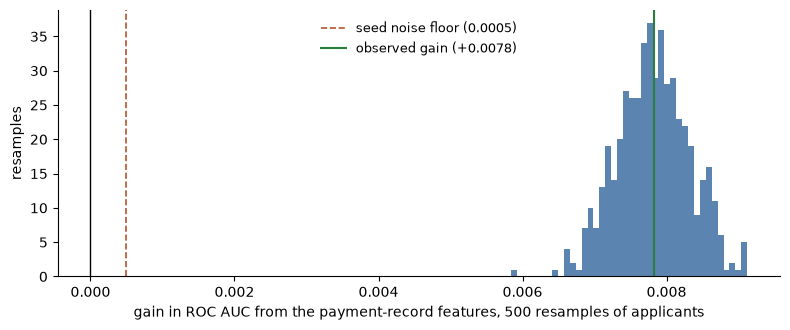

In [12]:
from scipy.stats import rankdata

def fast_auc(y, score):
    ranks = rankdata(score)
    n_pos = y.sum()
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * (len(y) - n_pos))
assert abs(fast_auc(y_arr, baseline['oof']) - roc_auc_score(y_arr, baseline['oof'])) < 1e-12

rng = np.random.default_rng(SEED)
boot = np.empty((500, 2))
for i in range(500):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot[i] = fast_auc(y_arr[idx], baseline['oof'][idx]), fast_auc(y_arr[idx], with_new['oof'][idx])
boot_gain = boot[:, 1] - boot[:, 0]
pooled_gain = roc_auc_score(y_arr, with_new['oof']) - roc_auc_score(y_arr, baseline['oof'])
print(f"gain on all out-of-fold predictions pooled: {pooled_gain:+.5f}  (mean of the five fold gains: {GAIN:+.5f})")
print(f"95% interval for the gain: {np.quantile(boot_gain, 0.025):+.5f} to {np.quantile(boot_gain, 0.975):+.5f}; standard deviation {boot_gain.std(ddof=1):.5f}")
print(f"resamples in which the model with the new features scores higher: {(boot_gain > 0).mean():.1%}; in which the gain exceeds the noise floor: {(boot_gain > NOISE_FLOOR).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(boot_gain, bins=40, color='#5b84b1')
ax.axvline(0, color='black', linewidth=1)
ax.axvline(NOISE_FLOOR, color='#b5542d', linestyle='--', linewidth=1.2, label=f'seed noise floor ({NOISE_FLOOR:.4f})')
ax.axvline(pooled_gain, color='#2a7f3f', linewidth=1.5, label=f'observed gain ({pooled_gain:+.4f})')
ax.set_xlabel('gain in ROC AUC from the payment-record features, 500 resamples of applicants'); ax.set_ylabel('resamples'); ax.legend(frameon=False, fontsize=9)
sns.despine(); plt.tight_layout(); plt.show()

### 3.4 What the gain means in practice

Each model declines the same share of applicants, the share the reference operating point declines, and the question is how many defaults each catches. This uses only the order of the predictions, so it does not depend on calibration.

In [13]:
APPROVE = float((p_old < THRESHOLD).mean())            # the approval rate of the calibrated current model at the reference threshold
def at_approval_rate(score, approve):
    declined = score >= np.quantile(score, approve)
    return {'defaults_caught_pct': (declined & (y_arr == 1)).sum() / y_arr.sum() * 100, 'default_rate_among_approved_pct': y_arr[~declined].mean() * 100}

practical = {}
for approve in [0.90, 0.80, APPROVE, 0.60]:
    a, b = at_approval_rate(baseline['oof'], approve), at_approval_rate(with_new['oof'], approve)
    practical[f'approve {approve:.1%}'] = {'defaults caught, current model (%)': a['defaults_caught_pct'], 'with the payment record (%)': b['defaults_caught_pct'],
                                          'more defaults caught per 100,000 applicants': (b['defaults_caught_pct'] - a['defaults_caught_pct']) / 100 * y_arr.mean() * 100000,
                                          'default rate among approved, current (%)': a['default_rate_among_approved_pct'], 'with the payment record  (%)': b['default_rate_among_approved_pct']}
print(pd.DataFrame(practical).T.to_string(float_format=lambda v: f'{v:,.2f}'))

declined_a = baseline['oof'] >= np.quantile(baseline['oof'], APPROVE)
declined_b = with_new['oof'] >= np.quantile(with_new['oof'], APPROVE)
print(f"\nat {APPROVE:.1%} approval: applicants whose decision changes {(declined_a != declined_b).mean():.1%}")
print(f"  newly declined: {int((declined_b & ~declined_a).sum()):,}, default rate {y_arr[declined_b & ~declined_a].mean():.1%}")
print(f"  newly approved: {int((~declined_b & declined_a).sum()):,}, default rate {y_arr[~declined_b & declined_a].mean():.1%}")
print(f"rank correlation between the two models' predictions: {pd.Series(baseline['oof']).corr(pd.Series(with_new['oof']), method='spearman'):.4f}  "
      f"(two seeds of the current model: {pd.Series(baseline['oof']).corr(pd.Series(seed_runs[1]['oof']), method='spearman'):.4f})")
def lift(score):
    order = np.argsort(-score)
    tenth = len(order) // 10
    return y_arr[order[:tenth]].sum() / y_arr.sum() * 100, y_arr[order[-tenth:]].mean() * 100
(top_a, safe_a), (top_b, safe_b) = lift(baseline['oof']), lift(with_new['oof'])
print(f"share of all defaults in the riskiest tenth: {top_a:.2f}% -> {top_b:.2f}%; default rate in the safest tenth: {safe_a:.2f}% -> {safe_b:.2f}%")

               defaults caught, current model (%)  with the payment record (%)  more defaults caught per 100,000 applicants  default rate among approved, current (%)  with the payment record  (%)
approve 90.0%                               36.54                        37.87                                       107.31                                      5.69                          5.57
approve 80.0%                               56.07                        57.60                                       123.57                                      4.43                          4.28
approve 71.4%                               67.66                        68.69                                        82.52                                      3.65                          3.54
approve 60.0%                               78.89                        79.81                                        74.79                                      2.84                          2.72

at 71.4% approval: 

rank correlation between the two models' predictions: 0.9620  (two seeds of the current model: 0.9942)
share of all defaults in the riskiest tenth: 36.54% -> 37.87%; default rate in the safest tenth: 0.88% -> 0.80%


### Stage 3 findings

**The payment record improves the model, and all four conditions are met**

| Fold | Current model (85) | With the payment record (114) | Gain |
|---|---:|---:|---:|
| 0 | 0.78518 | 0.79347 | +0.00829 |
| 1 | 0.78217 | 0.79008 | +0.00791 |
| 2 | 0.78659 | 0.79433 | +0.00774 |
| 3 | 0.78721 | 0.79391 | +0.00670 |
| 4 | 0.78710 | 0.79552 | +0.00843 |
| **Mean** | **0.78565** | **0.79346** | **+0.00781** |

- The gain is **0.0078**, with nothing tuned to the new features. It is higher in all five folds, 25.5 times its standard error, and 16 times the seed noise floor.
- PR AUC rises from 0.2768 to 0.2854, in all five folds.
- The three history tables have each added about the same: 0.0092 for the bureau, 0.0077 for earlier applications, 0.0078 for the payment record. Cross-validated, the model has gone from 0.7685 to 0.7935.
- Notebook 07 declined to predict a size. Its one-feature-at-a-time check said the behaviour features were mostly new to the model, and for once that reading and the result agree.

**The controls behave as they should**

| Run | Gain | Folds better | Meets all four |
|---|---:|---:|---|
| Real features, seed 42 | +0.00781 | 5 of 5 | Yes |
| Scrambled features, seed 42 | -0.00072 | 0 of 5 | No |
| Real features, seed 1 | +0.00750 | 5 of 5 | Yes |
| Real features, seed 2 | +0.00750 | 5 of 5 | Yes |

- Given another applicant's payment record, the model gets worse in every fold, by 0.0007. So the gain is not from having more columns. Against that control, the information in the features is worth 0.0085.
- The scrambled columns cost less here than in the earlier notebooks (0.0020 and 0.0015). There are fewer of them, and they are a smaller share of what each tree is offered.
- On two other seeds the gain is 0.0075 both times.

**Resampling applicants gives the same picture**
- Over 500 resamples, the 95% interval for the gain is 0.0069 to 0.0088. The model with the new features scores higher in every resample, and by more than the noise floor in every one.

**In practice**
- Declining the same 28.6% of applicants, the model now catches 68.7% of defaults against 67.7%. That is about 83 more defaults caught per 100,000 applicants.
- The default rate among approved applicants falls from 3.65% to 3.54%.
- 6.5% of applicants get a different decision. Those newly declined default at 10.9%, and those newly approved at 8.3%.
- The riskiest tenth now holds 37.9% of all defaults, up from 36.5%, and the safest tenth defaults at 0.80%, down from 0.88%.

**Leakage check for this stage**
- The only change from the baseline is the list of features. Settings, trees, seed and folds are the same.
- Nothing was chosen in this stage. The 29 features are the list notebook 07 saved, which dropped none of its candidates using outcomes.
- The holdout was not used.

**Decisions**
- The features are adopted. `with_new` (114 features, 0.7935) is the model to carry forward.

## Stage 4: Where the gain comes from

| Section | Question |
|---|---|
| 4.1 | Who is the gain for? |
| 4.2 | Which families of features carry it? Each family added alone, and each removed |
| 4.3 | What do the two features carrying a shift warning contribute? |
| 4.4 | How much does the simplest version of this table give? |

Every model here uses the settings of stage 3 and the same folds.

### 4.1 Who is the gain for?

The groups are those of section 2.4. Applicants with no payment history have every new feature missing. In notebook 04 applicants in that position lost a little, and in notebook 06 they gained a little.

In [14]:
def group_auc(result):
    return pd.DataFrame({label: [roc_auc_score(y_arr[m & (dev_fold == k)], result['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS)] for label, m in GROUPS.items()})
a, b = group_auc(baseline), group_auc(with_new)
d = b - a
rank_a, rank_b = pd.Series(baseline['oof']).rank(pct=True).values, pd.Series(with_new['oof']).rank(pct=True).values
who = pd.DataFrame({'applicants': {label: int(m.sum()) for label, m in GROUPS.items()}, 'default_pct': {label: y_arr[m].mean() * 100 for label, m in GROUPS.items()},
                    'current_model': a.mean(), 'with_new_features': b.mean(), 'gain': d.mean(), 'standard_error': d.std(ddof=1) / np.sqrt(N_SPLITS), 'folds_better': (d > 0).sum(),
                    'position_in_risk_order_before': {label: rank_a[m].mean() for label, m in GROUPS.items()}, 'position_after': {label: rank_b[m].mean() for label, m in GROUPS.items()}})
print('ROC AUC within each group, and where the group sits on average in the ordering of all applicants by risk (1 = riskiest):')
print(who.to_string(float_format=lambda v: f'{v:,.4f}'))
changed = declined_a != declined_b
print(f"\nof the applicants whose decision changes, {has_payments[changed].mean():.1%} have a payment history (they are {has_payments.mean():.1%} of all applicants)")
print(f"share whose decision changes: with a payment history {changed[has_payments].mean():.2%}, without {changed[~has_payments].mean():.2%}")
ever_late = GROUPS['   late by over 5 days at some time']
print(f"among applicants newly declined, {ever_late[declined_b & ~declined_a].mean():.1%} have been late by over 5 days; among those newly approved, {ever_late[~declined_b & declined_a].mean():.1%} (all applicants: {ever_late.mean():.1%})")

ROC AUC within each group, and where the group sits on average in the ordering of all applicants by risk (1 = riskiest):
                                             applicants  default_pct  current_model  with_new_features    gain  standard_error  folds_better  position_in_risk_order_before  position_after
all applicants                                   246008       8.0729         0.7856             0.7935  0.0078          0.0003             5                         0.5000          0.5000
no payment history                                12686       5.9830         0.8196             0.8191 -0.0005          0.0012             1                         0.4142          0.4179
has a payment history                            233322       8.1865         0.7837             0.7920  0.0083          0.0003             5                         0.5047          0.5045
   never late by over 5 days                     164187       7.3934         0.7893             0.7947  0.0054          0.0003 

### 4.2 Which families carry the gain?

Each family is added alone to the current model, which shows what it can do by itself, and removed from the full model, which shows what the other families cannot supply.

{'lateness': ['SHARE_LATE_5D', 'MAX_DAYS_LATE', 'N_LATE_30D', 'MEAN_DAYS_EARLY'], 'recent behaviour': ['SHARE_LATE_5D_12M', 'MEAN_TIMING_12M', 'TIMING_CHANGE', 'N_LATE_5D_6M', 'DAYS_SINCE_LAST_LATE_5D', 'LAST_TIMING'], 'parts and shortfall': ['SHARE_PAID_IN_PARTS', 'SHARE_PAID_IN_PARTS_12M', 'N_SHORT'], 'penalties': ['N_PENALTIES', 'N_PENALTIES_24M', 'DAYS_SINCE_LAST_PENALTY'], 'unpaid': ['N_UNPAID_RECENT', 'N_UNPAID_OLDER'], 'cards': ['CARD_N_INSTALMENTS', 'CARD_SHARE_LATE_5D', 'CARD_ACTIVE_90D', 'CARD_MEAN_PAYMENT_12M'], 'amounts': ['PAID_12M', 'MEDIAN_AMT_DUE', 'SHARE_LOANS_LARGE_PAYMENT', 'SHARE_SPLIT_DUE'], 'volume': ['N_INSTALMENTS', 'DAYS_SINCE_LAST_PAYMENT', 'N_PAYMENTS_30D']}



sixteen models: 0.5 minutes (16 loaded from cache)

                     features  gain_when_added_alone  folds_better  share_of_full_gain_pct  change_when_removed  folds_worse  se_removed
recent behaviour            6               +0.00447             5               +57.25808             -0.00087            5    +0.00025
parts and shortfall         3               +0.00365             5               +46.73477             -0.00031            4    +0.00022
lateness                    4               +0.00336             5               +42.96452             -0.00015            3    +0.00009
cards                       4               +0.00156             5               +19.96679             -0.00088            5    +0.00030
amounts                     4               +0.00148             5               +18.98343             -0.00093            5    +0.00016
penalties                   3               +0.00130             5               +16.67636             -0.00029            3 


average position in the risk ordering (1 = riskiest of all applicants):
                                        applicants  default_pct  current model  full model  full model without penalties  full model without unpaid  current model plus penalties only
a penalty charge in the last 24 months   2,567.000       23.919          0.687       0.840                         0.780                      0.839                              0.845
a penalty charge at some time            7,246.000       15.139          0.598       0.680                         0.657                      0.679                              0.679
an unpaid instalment                       397.000       27.204          0.661       0.722                         0.725                      0.722                              0.669


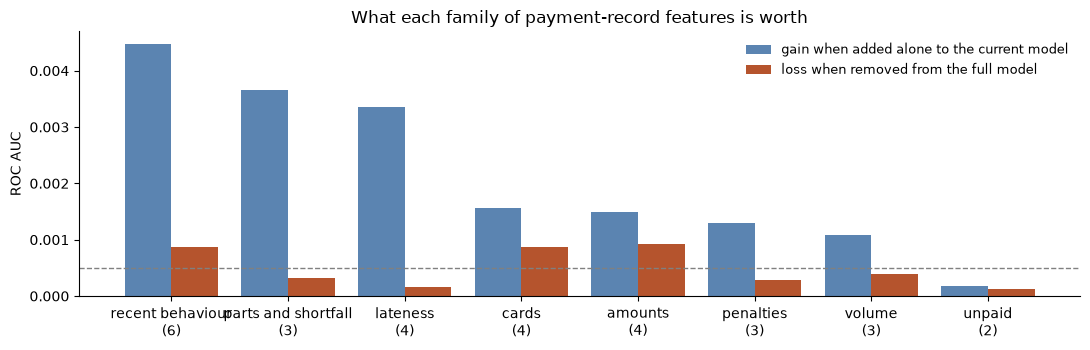

In [15]:
FAMILIES = {family: [c for c in INST if FAMILY[c] == family] for family in ['lateness', 'recent behaviour', 'parts and shortfall', 'penalties', 'unpaid', 'cards', 'amounts', 'volume']}
assert sum(len(v) for v in FAMILIES.values()) == len(INST)
print({family: [short(c) for c in members] for family, members in FAMILIES.items()})

started = time.time()
alone_runs = {family: run(CURRENT + members) for family, members in FAMILIES.items()}
without_runs = {family: run([c for c in WITH_NEW if c not in members]) for family, members in FAMILIES.items()}
print(f"\nsixteen models: {(time.time() - started) / 60:.1f} minutes ({sum(r['cached'] for r in list(alone_runs.values()) + list(without_runs.values()))} loaded from cache)")
rows = {}
for family, members in FAMILIES.items():
    up, down = compare(alone_runs[family], baseline), compare(without_runs[family], with_new)
    rows[family] = {'features': len(members), 'gain_when_added_alone': up['mean_difference'], 'folds_better': up['folds_better'], 'share_of_full_gain_pct': up['mean_difference'] / GAIN * 100,
                    'change_when_removed': down['mean_difference'], 'folds_worse': N_SPLITS - down['folds_better'], 'se_removed': down['standard_error']}
families = pd.DataFrame(rows).T.sort_values('gain_when_added_alone', ascending=False)
print()
print(families.astype({'features': int, 'folds_better': int, 'folds_worse': int}).to_string(float_format=lambda v: f'{v:+.5f}'))
print(f"\nfull gain from all eight families together: {GAIN:+.5f}")
print(f"sum of the eight gains when added alone: {families['gain_when_added_alone'].sum():+.5f}  ({families['gain_when_added_alone'].sum() / GAIN:.0%} of the full gain: above 100% means the families overlap)")
print(f"sum of the eight losses when removed:    {families['change_when_removed'].sum():+.5f}  ({-families['change_when_removed'].sum() / GAIN:.0%} of the full gain is unique to one family)")

# the two families of rare events: what they do for the applicants they describe, whatever they do to the overall score
rare_groups = {'a penalty charge in the last 24 months': GROUPS['   a penalty charge in the last 24 months'], 'a penalty charge at some time': GROUPS['   a penalty charge at some time'], 'an unpaid instalment': GROUPS['   an unpaid instalment']}
position = lambda r, m: float(pd.Series(r['oof']).rank(pct=True).values[m].mean())
rare_table = pd.DataFrame({label: {'applicants': int(m.sum()), 'default_pct': y_arr[m].mean() * 100, 'current model': position(baseline, m), 'full model': position(with_new, m),
                                   'full model without penalties': position(without_runs['penalties'], m), 'full model without unpaid': position(without_runs['unpaid'], m),
                                   'current model plus penalties only': position(alone_runs['penalties'], m)} for label, m in rare_groups.items()}).T
print('\naverage position in the risk ordering (1 = riskiest of all applicants):')
print(rare_table.to_string(float_format=lambda v: f'{v:,.3f}'))

fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(len(families))
ax.bar(x - 0.2, families['gain_when_added_alone'].astype(float), 0.4, label='gain when added alone to the current model', color='#5b84b1')
ax.bar(x + 0.2, -families['change_when_removed'].astype(float), 0.4, label='loss when removed from the full model', color='#b5542d')
ax.axhline(NOISE_FLOOR, color='grey', linestyle='--', linewidth=1)
ax.set_xticks(x); ax.set_xticklabels([f"{f}\n({int(n)})" for f, n in zip(families.index, families['features'])]); ax.set_ylabel('ROC AUC'); ax.legend(frameon=False, fontsize=9)
ax.set_title('What each family of payment-record features is worth')
sns.despine(); plt.tight_layout(); plt.show()

### 4.3 The two features carrying a shift warning

Notebook 07 sent two features forward with a warning: `N_LATE_5D_6M`, the number of instalments in the last six months completed more than five days late, and `N_UNPAID_RECENT`, the number of recent instalments with no payment. Both events are about a third rarer among test applicants than among train applicants.

They are removed from the full model together. A small loss means the warning costs little to act on. Because both are rare events, the overall score is expected to say little, so the applicants concerned are looked at directly.

In [16]:
SHIFT_WARNED = list(WARNED)
assert SHIFT_WARNED == ['INST_N_LATE_5D_6M', 'INST_N_UNPAID_RECENT']
started = time.time()
no_warned = run([c for c in WITH_NEW if c not in SHIFT_WARNED])
print(f"without the two flagged features ({len(WITH_NEW) - 2} features): {'loaded from cache' if no_warned['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
against_full, against_base = compare(no_warned, with_new), compare(no_warned, baseline)
print(f"ROC AUC {no_warned['mean']['roc_auc']:.5f}; change from the full model {against_full['mean_difference']:+.5f} (standard error {against_full['standard_error']:.5f}, worse in {N_SPLITS - against_full['folds_better']} of 5 folds)")
print(f"gain over the current model {against_base['mean_difference']:+.5f} ({against_base['mean_difference'] / GAIN:.0%} of the full gain); still meets all four conditions: {verdict(no_warned)['improves']}")

flag_groups = {'late by over 5 days in the last 6 months': (inst('N_LATE_5D_6M') > 0).values, 'a recent unpaid instalment': (inst('N_UNPAID_RECENT') > 0).values,
               'late in the last 12 months but not the last 6': ((inst('SHARE_LATE_5D_12M') > 0) & ~(inst('N_LATE_5D_6M') > 0)).values}
auc_in = lambda r, m: float(np.mean([roc_auc_score(y_arr[m & (dev_fold == k)], r['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS) if 0 < y_arr[m & (dev_fold == k)].sum() < (m & (dev_fold == k)).sum()]))
flag_table = pd.DataFrame({label: {'applicants': int(m.sum()), 'default_pct': y_arr[m].mean() * 100, 'position: current model': position(baseline, m), 'position: full model': position(with_new, m),
                                   'position: without the two': position(no_warned, m), 'AUC within: full model': auc_in(with_new, m), 'AUC within: without the two': auc_in(no_warned, m)}
                           for label, m in flag_groups.items()}).T
print('\nthe applicants the two features describe (position: average place in the risk ordering, 1 = riskiest):')
print(flag_table.to_string(float_format=lambda v: f'{v:,.3f}'))

without the two flagged features (112 features): loaded from cache
ROC AUC 0.79327; change from the full model -0.00019 (standard error 0.00018, worse in 3 of 5 folds)
gain over the current model +0.00762 (98% of the full gain); still meets all four conditions: True



the applicants the two features describe (position: average place in the risk ordering, 1 = riskiest):
                                               applicants  default_pct  position: current model  position: full model  position: without the two  AUC within: full model  AUC within: without the two
late by over 5 days in the last 6 months        5,707.000       15.437                    0.594                 0.704                      0.703                   0.776                        0.778
a recent unpaid instalment                        305.000       30.164                    0.671                 0.744                      0.742                   0.739                        0.737
late in the last 12 months but not the last 6   7,005.000       14.575                    0.605                 0.702                      0.702                   0.761                        0.761


### 4.4 How much does the simplest version give?

Two shorter lists, for scale. One feature: the share of instalments completed more than five days late, which is what most people would build first from this table. And the four features that notebook 07's screening ranked highest beyond the current model.

In [17]:
started = time.time()
one_feature = run(CURRENT + ['INST_SHARE_LATE_5D'])
strongest_four = ['INST_DAYS_SINCE_LAST_PENALTY', 'INST_DAYS_SINCE_LAST_LATE_5D', 'INST_MAX_DAYS_LATE', 'INST_SHARE_PAID_IN_PARTS_12M']
top_four = run(CURRENT + strongest_four)
print(f"two models: {(time.time() - started) / 60:.1f} minutes")
steps = {}
for label, r in {'current model (85)': baseline, 'plus the share of instalments over 5 days late (86)': one_feature,
                 'plus the four features notebook 07 ranked highest beyond the current model (89)': top_four, 'plus all 29 features (114)': with_new}.items():
    c = compare(r, baseline)
    steps[label] = {'roc_auc': r['mean']['roc_auc'], 'gain': c['mean_difference'], 'folds_better': c['folds_better'], 'share_of_full_gain_pct': c['mean_difference'] / GAIN * 100}
print()
print(pd.DataFrame(steps).T.astype({'folds_better': int}).to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nthe four features: {[short(c) for c in strongest_four]}")

two models: 0.1 minutes

                                                                                 roc_auc    gain  folds_better  share_of_full_gain_pct
current model (85)                                                               0.78565 0.00000             0                 0.00000
plus the share of instalments over 5 days late (86)                              0.78798 0.00233             5                29.77044
plus the four features notebook 07 ranked highest beyond the current model (89)  0.78995 0.00430             5                55.03450
plus all 29 features (114)                                                       0.79346 0.00781             5               100.00000

the four features: ['DAYS_SINCE_LAST_PENALTY', 'DAYS_SINCE_LAST_LATE_5D', 'MAX_DAYS_LATE', 'SHARE_PAID_IN_PARTS_12M']


### Stage 4 findings

**The gain goes to the applicants the model was wrong about**

| Group | Applicants | Current model | With the payment record | Gain | Folds better |
|---|---:|---:|---:|---:|---:|
| Has a payment history | 233,322 | 0.7837 | 0.7920 | +0.0083 | 5 of 5 |
| An unpaid instalment | 397 | 0.7436 | 0.7696 | +0.0261 | 5 of 5 |
| A penalty charge at some time | 7,246 | 0.7612 | 0.7806 | +0.0194 | 5 of 5 |
| No bureau record | 35,244 | 0.7656 | 0.7812 | +0.0156 | 5 of 5 |
| Late by over 5 days at some time | 66,918 | 0.7691 | 0.7800 | +0.0109 | 5 of 5 |
| Paid in parts over 15% of the time | 31,057 | 0.7645 | 0.7753 | +0.0107 | 5 of 5 |
| Never late by over 5 days | 164,187 | 0.7893 | 0.7947 | +0.0054 | 5 of 5 |
| No payment history | 12,686 | 0.8196 | 0.8191 | -0.0005 | 1 of 5 |

- Those figures are the ordering *within* each group. The larger effect is on where each group sits among all applicants. Applicants with a penalty charge in the last 24 months, who default at 23.9%, move from 0.69 to 0.84 on a scale where 1 is the riskiest of all. Applicants late in the last six months move from 0.59 to 0.70. Applicants who have never been late move down, from 0.49 to 0.48.
- Of the applicants newly declined, 60% have been late by more than five days at some time. Of those newly approved, 18% have. Among all applicants it is 27%. The model is doing what the features were built for.
- **Applicants with no bureau record gain twice the average again** (+0.0156), as in notebook 06. For them Home Credit's own records are most of what there is.
- **Applicants with no payment history lose 0.0005, in 4 of 5 folds.** The standard error is 0.0012, so this is inside the noise, and it is the dilution notebook 04 first saw: 29 columns that are empty for them take up room in each tree. It is small, and it is the price of the gain for the other 95%.

**Three families carry most of it, and they overlap heavily**

| Family | Features | Gain when added alone | Share of the full gain | Change when removed |
|---|---:|---:|---:|---:|
| Recent behaviour | 6 | +0.0045 | 57% | -0.0009 |
| Parts and shortfall | 3 | +0.0037 | 47% | -0.0003 |
| Lateness | 4 | +0.0034 | 43% | -0.0002 |
| Cards | 4 | +0.0016 | 20% | -0.0009 |
| Amounts | 4 | +0.0015 | 19% | -0.0009 |
| Penalties | 3 | +0.0013 | 17% | -0.0003 |
| Volume | 3 | +0.0011 | 14% | -0.0004 |
| Unpaid | 2 | +0.0002 | 2% | -0.0001 |

- The gains alone sum to 219% of the full gain. In notebook 06 the same figure was 143%. These families are different views of one thing, how reliably the applicant pays, and any of the three largest gives about half the gain by itself.
- For the same reason no family is indispensable. The largest loss when one is removed is 0.0009.
- The three families that cost most to remove are recent behaviour, cards and amounts. Cards and amounts are small alone and are not replaceable by the others, because they describe something else.
- **Every family adds something alone, in all five folds, except unpaid.** In notebook 06 three of the six families added about 0.001 between them. This table has less dead weight.

**The unpaid features do nothing, even for the applicants they describe**

| Applicants with | Default rate | Position: current model | Full model | Full model without the family |
|---|---:|---:|---:|---:|
| A penalty charge in the last 24 months | 23.9% | 0.687 | 0.840 | 0.780 without penalties |
| An unpaid instalment | 27.2% | 0.661 | 0.722 | 0.725 without unpaid |

- The penalty features do what rare-event features should. Without them the applicants concerned are placed lower in the risk ordering (0.78 against 0.84), although the overall score moves by only 0.0003.
- The unpaid features do not. The 397 applicants with an unpaid instalment are placed just as high without those two features as with them. Another feature already tells the model: the timing of the most recent instalment is missing when that instalment has no payment.
- This is the opposite of what I expected. In notebook 07 I nearly left these features out for being rare, then kept them because the applicants default at 30%, and called the first instinct a mistake the project had made four times. The applicants are high risk. The features are still redundant. Whether a rare-event feature earns its place depends on whether anything else describes the same people, and that can only be seen in the model.

**The two features with a shift warning are not needed, and are dropped**
- Without `N_LATE_5D_6M` and `N_UNPAID_RECENT` the model scores 0.79327 against 0.79346: a change of -0.0002 with a standard error of 0.0002, worse in 3 of 5 folds. That is nothing.
- The applicants they describe are placed in the same position without them: 0.703 against 0.704 for those late in the last six months, and 0.742 against 0.744 for those with a recent unpaid instalment. The other recent-behaviour features carry the same information.
- In notebook 06 the flagged feature was worth 0.0012 and was kept, with a diagnostic submission to test it. Here the flagged features are worth nothing measurable. A feature that is distributed differently in the test file and adds nothing is a risk with no return. **Both are removed.** The model carried forward has 112 features and scores 0.7933.
- This is a decision made on the development folds, and I want to be exact about its kind. It does not select for score: the score falls slightly. It removes two inputs on a ground fixed before any model was fitted (the warning from notebook 07), once the folds showed that acting on the warning costs nothing.
- Stage 9 still writes a second submission, now the other way round: the model *with* the two features, as a check on this decision.

**A short list gives half the gain**

| Model | ROC AUC | Share of the full gain |
|---|---:|---:|
| Current model (85) | 0.78565 | |
| Plus the share of instalments over 5 days late (86) | 0.78798 | 30% |
| Plus the four features ranked highest by notebook 07 (89) | 0.78995 | 55% |
| Plus all 29 (114) | 0.79346 | 100% |

- One feature, the first anyone would build, gives 30% of the gain. Four give 55%. The remaining 25 features give the other 45%, which is why stage 5 is worth doing carefully.

**Leakage check for this stage**
- Every comparison is on the frozen folds with unchanged settings.
- One decision was taken: dropping the two flagged features. Its effect on the score is -0.0002.
- The holdout was not used.

**Decisions**
- The model carried forward is `no_warned`: 112 features, 0.79327.
- Stage 5 prunes the 27 remaining new features.

## Stage 5: Pruning

Can the list of new features be shortened at no cost?

The method is that of notebooks 04 and 06.

- **Selection inside the folds.** In each fold the new features are ranked using the training folds only, and the model is fitted on the ones that ranking kept. That gives an honest score for "the best *m*". One fixed list is drawn up only afterwards, and the difference between its score and the honest one is reported.
- **Rare events judged separately.** A ranking by average contribution undervalues a feature that is zero for almost everyone. So the rare-event features are identified in advance, and those the ranking drops are tested by adding them back.

**The rules, fixed in advance.**
1. Take the smallest number of new features whose honest score is within the noise floor (0.0005) of the full model's.
2. Rare-event features are those that are zero for at least 90% of applicants with a payment history. Add back the ones the ranking dropped, and keep them if the overall score does not fall by more than the noise floor. **One change from notebook 06**, made because of what stage 4 found: a rare-event feature is added back only if the applicants it describes are placed differently in the risk ordering with it than without it, by at least 0.01. Stage 4 showed that a rare-event feature can describe very risky applicants and still add nothing, and notebook 06 kept one such feature only because its rule had no test for it. The 0.01 is fixed now, before the ranking is seen.

The "full model" here is the 112-feature model of stage 4, and the candidates are its 27 new features. The 85 features of the current model are always kept.

No features built from two tables are tried this time. The idea was tested in notebooks 04 and 06 and changed nothing in either.

| Section | What it does |
|---|---|
| 5.1 | Rank the new features inside each fold |
| 5.2 | The honest score for the best 20, 15 and 10 |
| 5.3 | A fixed list, and the rare-event test |

### 5.1 Ranking inside each fold

In [18]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

full = no_warned                                              # the model carried forward from stage 4
FULL_FEATURES = [c for c in WITH_NEW if c not in SHIFT_WARNED]
CANDIDATES = [c for c in INST if c not in SHIFT_WARNED]
assert len(FULL_FEATURES) == 112 and len(CANDIDATES) == 27
FAST_TREES, FAST_RATE = 1400, 0.05              # a quicker version of the model for ranking: the same settings, 3,500 trees at 0.02 scaled to 0.05

def rank_candidates(X_encoded, y, always, candidates):
    # Ranks the candidates using these rows only: fit on 80%, measure each feature's average contribution on the other 20%.
    y = np.asarray(y)
    grow, watch = train_test_split(np.arange(len(y)), test_size=0.20, stratify=y, random_state=SEED)
    columns = list(always) + list(candidates)
    model = lgbm_model(BEST_PARAMS, FAST_TREES, FAST_RATE).fit(X_encoded.iloc[grow][columns], y[grow])
    contributions = model.booster_.predict(X_encoded.iloc[watch][columns], pred_contrib=True)[:, :-1]
    size = pd.Series(np.abs(contributions).mean(axis=0), index=columns)
    return size[list(candidates)].sort_values(ascending=False)

class TopCandidates(BaseEstimator, TransformerMixin):
    # Keeps the 'always' columns and the best 'keep' of the 'candidates', ranked on the rows passed to fit.
    def __init__(self, always, candidates, keep):
        self.always = always
        self.candidates = candidates
        self.keep = keep
    def fit(self, X, y):
        self.ranking_ = rank_candidates(X, y, self.always, self.candidates)
        self.columns_ = list(self.always) + list(self.ranking_.index[:self.keep])
        return self
    def transform(self, X):
        return X[self.columns_]

def selecting_pipeline(keep):
    return Pipeline([('preprocess', Pipeline([('encode', CategoryEncoder(columns=list(TEXT_FEATURES))), ('choose', TopCandidates(CURRENT, CANDIDATES, keep))])), ('model', FINAL())])

RANK_PATH = CACHE_DIR / 'rankings_v1.joblib'
started = time.time()
if RANK_PATH.exists():
    fold_rankings = joblib.load(RANK_PATH)
else:
    fold_rankings = {}
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for k in range(N_SPLITS):
            fit = dev_fold != k
            encoded = CategoryEncoder(columns=list(TEXT_FEATURES)).fit(X_dev[fit]).transform(X_dev[fit])
            fold_rankings[k] = rank_candidates(encoded, y_arr[fit], CURRENT, CANDIDATES)
    joblib.dump(fold_rankings, RANK_PATH)
print(f"five rankings: {(time.time() - started) / 60:.1f} minutes")

size = pd.DataFrame(fold_rankings)
ranks = size.rank(ascending=False).astype(int)
zero_share = (X_dev.loc[has_payments, CANDIDATES] == 0).sum() / X_dev.loc[has_payments, CANDIDATES].notna().sum()
ranking = pd.DataFrame({'family': pd.Series(FAMILY).reindex(CANDIDATES), 'mean_contribution': size.mean(axis=1), 'mean_rank': ranks.mean(axis=1), 'best_rank': ranks.min(axis=1), 'worst_rank': ranks.max(axis=1),
                        'share_pct': size.mean(axis=1) / size.mean(axis=1).sum() * 100, 'zero_for_pct_of_applicants': zero_share * 100,
                        'has_a_value_pct': X_dev[CANDIDATES].notna().mean() * 100}).sort_values('mean_rank')
ranking.index = [short(c) for c in ranking.index]
ranking['cumulative_pct'] = ranking['share_pct'].cumsum()
print(ranking.to_string(float_format=lambda v: f'{v:.3f}'))
RARE_EVENTS = [c for c in CANDIDATES if zero_share[c] >= 0.90]
print(f"\nrare-event features (zero for at least 90% of applicants with a value): {[short(c) for c in RARE_EVENTS]}")
print(pd.DataFrame({m: {'chosen in all five folds': int((ranks <= m).all(axis=1).sum()), 'chosen in at least one': int((ranks <= m).any(axis=1).sum()),
                        'share of the new features\' contribution (%)': float(size.mean(axis=1).sort_values(ascending=False).iloc[:m].sum() / size.mean(axis=1).sum() * 100)} for m in [20, 15, 10]}).T.round(1).to_string())
print(pd.DataFrame({'features': ranking.groupby('family').size(), 'share_pct': ranking.groupby('family')['share_pct'].sum(), 'best_rank': ranking.groupby('family')['mean_rank'].min()}).sort_values('share_pct', ascending=False).round(1).to_string())

five rankings: 0.0 minutes


                                        family  mean_contribution  mean_rank  best_rank  worst_rank  share_pct  zero_for_pct_of_applicants  has_a_value_pct  cumulative_pct
N_INSTALMENTS                           volume              0.100      1.000          1           1     13.878                       0.950           94.843          13.878
MEDIAN_AMT_DUE                         amounts              0.061      2.800          2           6      8.395                       0.001           93.942          22.273
CARD_MEAN_PAYMENT_12M                    cards              0.052      3.800          3           4      7.153                       0.027           18.278          29.426
DAYS_SINCE_LAST_LATE_5D       recent behaviour              0.050      4.200          2           7      6.863                       0.000           27.202          36.288
MAX_DAYS_LATE                         lateness              0.051      4.400          3           6      6.986                      50.757  

### 5.2 The honest score for the best *m*

In [19]:
def run_pipeline(pipe, X=None):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return cross_validate(pipe, X_dev if X is None else X, y_arr, dev_fold, cache_dir=CACHE_DIR)

def group_change(result, reference, mask):
    d = [roc_auc_score(y_arr[mask & (dev_fold == k)], result['oof'][mask & (dev_fold == k)]) - roc_auc_score(y_arr[mask & (dev_fold == k)], reference['oof'][mask & (dev_fold == k)]) for k in range(N_SPLITS)]
    return float(np.mean(d))

M_VALUES = [20, 15, 10]
started = time.time()
selected_runs = {m: run_pipeline(selecting_pipeline(m)) for m in M_VALUES}
print(f"three models with selection inside the folds: {(time.time() - started) / 60:.1f} minutes")
rows = {}
for label, r in {'all 27 new features': full, **{f'best {m}, chosen in each fold': selected_runs[m] for m in M_VALUES}, 'no new features': baseline}.items():
    against_full, base = compare(r, full), compare(r, baseline)
    rows[label] = {'roc_auc': r['mean']['roc_auc'], 'change_from_all_27': against_full['mean_difference'], 'folds_worse': (N_SPLITS - against_full['folds_better']) if r is not full else 0,
                   'gain_over_current_model': base['mean_difference'], 'within_noise_of_all_27': against_full['mean_difference'] > -NOISE_FLOOR}
honest = pd.DataFrame(rows).T
print()
print(honest.to_string(float_format=lambda v: f'{v:+.5f}'))
eligible = [m for m in M_VALUES if honest.loc[f'best {m}, chosen in each fold', 'within_noise_of_all_27']]
M_CHOSEN = min(eligible) if eligible else len(CANDIDATES)
print(f"\nrule 1: the smallest number of new features within {NOISE_FLOOR:.4f} of the full model -> {M_CHOSEN}")

three models with selection inside the folds: 0.1 minutes

                              roc_auc change_from_all_27 folds_worse gain_over_current_model within_noise_of_all_27
all 27 new features          +0.79327           +0.00000           0                +0.00762                   True
best 20, chosen in each fold +0.79312           -0.00015           2                +0.00747                   True
best 15, chosen in each fold +0.79243           -0.00084           5                +0.00678                  False
best 10, chosen in each fold +0.79261           -0.00066           5                +0.00696                  False
no new features              +0.78565           -0.00762           5                +0.00000                  False

rule 1: the smallest number of new features within 0.0005 of the full model -> 20


### 5.3 A fixed list, and the rare-event test

In [20]:
order = ['INST_' + c for c in ranking.index]
RULE_INST = order[:M_CHOSEN]
print(f"fixed list by rule 1: {len(RULE_INST)} new features")
print(pd.Series({f: [short(c) for c in RULE_INST if FAMILY[c] == f] for f in FAMILIES}).to_string())
print(f"\ndropped: {[short(c) for c in order[M_CHOSEN:]]}")

started = time.time()
pruned_rule = run(CURRENT + RULE_INST) if M_CHOSEN < len(CANDIDATES) else full
vs_full = compare(pruned_rule, full)
print(f"\nfixed list of {len(CURRENT) + len(RULE_INST)} features: ROC AUC {pruned_rule['mean']['roc_auc']:.5f}; against all 27: {vs_full['mean_difference']:+.5f} (better in {vs_full['folds_better']} of 5 folds)")
if M_CHOSEN in selected_runs:
    print(f"against the honest score for the same number: {compare(pruned_rule, selected_runs[M_CHOSEN])['mean_difference']:+.5f}  <- what fixing the list on these folds flatters")

# rule 2: the rare-event features the ranking dropped, tested one group at a time
MIN_MOVE = 0.01
rare_dropped = [c for c in RARE_EVENTS if c not in RULE_INST]
print(f"\nrare-event features the ranking dropped: {[short(c) for c in rare_dropped]}")
pct = lambda score: pd.Series(score).rank(pct=True).values
ADDED_BACK = []
if rare_dropped:
    pruned_rare = run(CURRENT + RULE_INST + rare_dropped)
    rare_vs = compare(pruned_rare, pruned_rule)
    print(f"all added back: ROC AUC {pruned_rule['mean']['roc_auc']:.5f} -> {pruned_rare['mean']['roc_auc']:.5f}: change {rare_vs['mean_difference']:+.5f} (standard error {rare_vs['standard_error']:.5f}, better in {rare_vs['folds_better']} of 5 folds)")
    positions = {}
    for c in rare_dropped:
        m = (X_dev[c] > 0).values
        positions[short(c)] = {'applicants': int(m.sum()), 'pct_of_applicants': m.mean() * 100, 'default_pct': y_arr[m].mean() * 100, 'current model': pct(baseline['oof'])[m].mean(),
                               'rule list (without)': pct(pruned_rule['oof'])[m].mean(), 'rule list plus the rare events': pct(pruned_rare['oof'])[m].mean(), 'all 27': pct(full['oof'])[m].mean()}
    positions = pd.DataFrame(positions).T
    positions['move'] = positions['rule list plus the rare events'] - positions['rule list (without)']
    print('\napplicants with the event: their average position in the risk ordering under each model (1 = riskiest of all)')
    print(positions.to_string(float_format=lambda v: f'{v:,.3f}'))
    score_ok = bool(rare_vs['mean_difference'] > -NOISE_FLOOR)
    ADDED_BACK = ['INST_' + c for c in positions.index[positions['move'].abs() >= MIN_MOVE]] if score_ok else []
    print(f"\nrule 2: the overall score does not fall by more than {NOISE_FLOOR:.4f}: {score_ok}; features whose applicants move by at least {MIN_MOVE}: {[short(c) for c in ADDED_BACK]}")
KEPT_INST = RULE_INST + ADDED_BACK
PRUNED = CURRENT + KEPT_INST
pruned = pruned_rule if not ADDED_BACK else (pruned_rare if set(ADDED_BACK) == set(rare_dropped) else run(PRUNED))
print(f"\nfixed list now: {len(KEPT_INST)} new features, {len(PRUNED)} in total; ROC AUC {pruned['mean']['roc_auc']:.5f}; against all 27: {compare(pruned, full)['mean_difference']:+.5f}; "
      f"against the current model: {compare(pruned, baseline)['mean_difference']:+.5f}")
print(f"by family: {pd.Series([FAMILY[c] for c in KEPT_INST]).value_counts().to_dict()}")
print(f"new features left out: {[short(c) for c in CANDIDATES if c not in KEPT_INST]}")
print(f"applicants with no payment history: {group_change(pruned, baseline, ~has_payments):+.5f} against the current model; applicants with no bureau record: {group_change(pruned, baseline, ~has_bureau):+.5f}")
for label, m in {'a penalty charge in the last 24 months': GROUPS['   a penalty charge in the last 24 months'], 'an unpaid instalment': GROUPS['   an unpaid instalment'],
                 'late by over 5 days in the last 6 months': GROUPS['   late by over 5 days in the last 6 months']}.items():
    print(f"   position of applicants with {label}: current model {pct(baseline['oof'])[m].mean():.3f}, all 27 {pct(full['oof'])[m].mean():.3f}, fixed list {pct(pruned['oof'])[m].mean():.3f}")
CHOSEN_FEATURES, chosen = PRUNED, pruned
final_verdict = verdict(chosen)
print(f"\nfeature list carried forward: {len(CHOSEN_FEATURES)} features ({len(APP_IN_MODEL)} application, {len(BUREAU_IN_MODEL)} bureau, {len(PREV_IN_MODEL)} earlier applications, {len(KEPT_INST)} payment record); "
      f"meets all four conditions: {final_verdict['improves']}")
print(f"minutes for this section: {(time.time() - started) / 60:.1f}")
assert final_verdict['improves']

fixed list by rule 1: 20 new features
lateness                 [MAX_DAYS_LATE, MEAN_DAYS_EARLY, SHARE_LATE_5D]
recent behaviour       [DAYS_SINCE_LAST_LATE_5D, LAST_TIMING, TIMING_...
parts and shortfall       [SHARE_PAID_IN_PARTS_12M, SHARE_PAID_IN_PARTS]
penalties                                                             []
unpaid                                                                []
cards                  [CARD_MEAN_PAYMENT_12M, CARD_N_INSTALMENTS, CA...
amounts                [MEDIAN_AMT_DUE, SHARE_SPLIT_DUE, PAID_12M, SH...
volume                 [N_INSTALMENTS, DAYS_SINCE_LAST_PAYMENT, N_PAY...

dropped: ['DAYS_SINCE_LAST_PENALTY', 'SHARE_LATE_5D_12M', 'N_PENALTIES_24M', 'N_SHORT', 'N_PENALTIES', 'N_LATE_30D', 'N_UNPAID_OLDER']



fixed list of 105 features: ROC AUC 0.79316; against all 27: -0.00011 (better in 2 of 5 folds)
against the honest score for the same number: +0.00004  <- what fixing the list on these folds flatters

rare-event features the ranking dropped: ['N_LATE_30D', 'SHARE_LATE_5D_12M', 'N_SHORT', 'N_UNPAID_OLDER', 'N_PENALTIES', 'N_PENALTIES_24M']


all added back: ROC AUC 0.79316 -> 0.79339: change +0.00024 (standard error 0.00018, better in 4 of 5 folds)



applicants with the event: their average position in the risk ordering under each model (1 = riskiest of all)
                   applicants  pct_of_applicants  default_pct  current model  rule list (without)  rule list plus the rare events  all 27   move
N_LATE_30D         11,037.000              4.486        9.541          0.517                0.558                           0.555   0.555 -0.002
SHARE_LATE_5D_12M  12,712.000              5.167       14.962          0.600                0.707                           0.703   0.702 -0.003
N_SHORT             1,512.000              0.615       16.005          0.572                0.605                           0.674   0.672  0.068
N_UNPAID_OLDER        163.000              0.066       28.834          0.691                0.745                           0.745   0.744 -0.000
N_PENALTIES         7,246.000              2.945       15.139          0.598                0.657                           0.675   0.678  0.018
N_PENALTIES_24M    


fixed list now: 23 new features, 108 in total; ROC AUC 0.79316; against all 27: -0.00011; against the current model: +0.00751
by family: {'amounts': 4, 'cards': 4, 'recent behaviour': 4, 'volume': 3, 'lateness': 3, 'parts and shortfall': 3, 'penalties': 2}
new features left out: ['N_LATE_30D', 'SHARE_LATE_5D_12M', 'N_UNPAID_OLDER', 'DAYS_SINCE_LAST_PENALTY']
applicants with no payment history: -0.00192 against the current model; applicants with no bureau record: +0.01542


   position of applicants with a penalty charge in the last 24 months: current model 0.687, all 27 0.838, fixed list 0.835
   position of applicants with an unpaid instalment: current model 0.661, all 27 0.721, fixed list 0.721


   position of applicants with late by over 5 days in the last 6 months: current model 0.594, all 27 0.703, fixed list 0.704

feature list carried forward: 108 features (36 application, 24 bureau, 25 earlier applications, 23 payment record); meets all four conditions: True
minutes for this section: 0.1


### Stage 5 findings

**Twenty of the 27 features carry the gain**

| New features | ROC AUC | Against all 27 | Folds worse |
|---|---:|---:|---:|
| All 27 | 0.79327 | | |
| Best 20, chosen in each fold | 0.79312 | -0.00015 | 2 of 5 |
| Best 15, chosen in each fold | 0.79243 | -0.00084 | 5 of 5 |
| Best 10, chosen in each fold | 0.79261 | -0.00066 | 5 of 5 |

- These scores are honest: each fold ranked the features and chose its own list from its training rows.
- Rule 1 picks **20**. Fifteen and ten are both outside the noise floor and worse in every fold. In notebook 06, 20 of 41 were enough and 15 missed by a hair. Here the list can be cut by a quarter and no further, which fits what stage 4 found: this table has less dead weight.
- The ranking is stable. Seventeen of the 20 are chosen in all five folds.
- Fixing one list of 20 on all the development rows gives 0.79316 against the honest 0.79312, so the fixed list is flattered by 0.00004.

**The ranking and the tests of stage 4 disagree about what matters, and both are right**
- By average contribution the three families at the top are volume (21%), amounts (21%) and recent behaviour (21%). The number of instalments is first in every fold. In stage 4, volume added the least of any family but one when given to the model alone.
- These measure different things. Stage 4 asked what a family adds to the score. The ranking asks how much the model moves its predictions with a feature once all the others are there. The number of instalments tells the model how much evidence stands behind every other payment feature: one late instalment out of three is not one out of sixty. It is used heavily and adds little alone.
- This is why the pruning is done by fitting models and not by reading either list.

**Three rare-event features are added back, and three are not**

| Feature | Applicants | Default rate | Position without it | With it | Move | Added back |
|---|---:|---:|---:|---:|---:|---|
| `N_SHORT` | 1,512 | 16.0% | 0.605 | 0.674 | +0.068 | Yes |
| `N_PENALTIES_24M` | 2,567 | 23.9% | 0.781 | 0.832 | +0.052 | Yes |
| `N_PENALTIES` | 7,246 | 15.1% | 0.657 | 0.675 | +0.018 | Yes |
| `N_LATE_30D` | 11,037 | 9.5% | 0.558 | 0.555 | -0.002 | No |
| `SHARE_LATE_5D_12M` | 12,712 | 15.0% | 0.707 | 0.703 | -0.003 | No |
| `N_UNPAID_OLDER` | 163 | 28.8% | 0.745 | 0.745 | 0.000 | No |

- The ranking dropped all six features that are zero for at least 90% of applicants, as it always does.
- Added back together they raise the score by 0.0002, better in 4 of 5 folds, so the first half of rule 2 is met.
- The second half, new in this notebook, separates them cleanly. Three move the applicants they describe up the risk ordering by 0.02 to 0.07. Three move theirs by 0.003 or less, because other features already place those applicants. Applicants late in the last twelve months sit at 0.71 without the feature that counts them.
- Under notebook 06's rule all six would have been kept, three of them for nothing.
- `N_UNPAID_OLDER` goes, which removes the last of the unpaid family. Stage 4 found it redundant, and the applicants with an unpaid instalment are placed at 0.721 by the fixed list, the same as by the full model.

**The list carried forward**

| Source | Features |
|---|---:|
| Application | 36 |
| Credit bureau | 24 |
| Earlier applications | 25 |
| Payment record | 23 (4 amounts, 4 cards, 4 recent behaviour, 3 lateness, 3 parts and shortfall, 3 volume, 2 penalties) |
| **Total** | **108** |

- ROC AUC **0.79316**, a gain of **0.00751** over the current model, meeting all four conditions. Dropping six of the 29 features cost 0.0003 in all, of which 0.0002 was the two flagged features.
- The four left out here are `N_LATE_30D`, `SHARE_LATE_5D_12M`, `N_UNPAID_OLDER` and `DAYS_SINCE_LAST_PENALTY`.
- The last of those is worth a word. In notebook 07 it scored highest of all beyond the model (0.609). It has a value for 3% of applicants, so the ranking placed it 21st, and it is not a rare event by the definition used, because it is missing and not zero for the rest. It is gone, and applicants with a recent penalty are still placed at 0.835 against 0.838 with all 27, because `N_PENALTIES_24M` says nearly the same thing. A score of 0.609 among 3% of applicants was not the signal it looked like.
- The applicants the rare events describe keep their positions: recent penalty 0.835, unpaid instalment 0.721, late in the last six months 0.704.

**One thing to watch**
- For the 12,686 applicants with no payment history, the fixed list scores 0.0019 below the current model. With all 29 features the figure was 0.0005. The standard error for this group is about 0.0012, so neither is clearly different from zero, but the direction is the dilution seen before, and pruning has not helped it. Stage 6 checks the share of features per tree, which is the setting that governs it, and stage 7 checks whether these applicants' probabilities are still right.

**Leakage check for this stage**
- The scores used to choose how many features to keep came from lists chosen inside each fold.
- The fixed list was ranked on all development rows. Its score is compared with the honest one, and they differ by 0.00004.
- Rule 2 was decided on the validation folds. It added three features for a gain of 0.0000 in the overall score, so it cannot have raised the score by selection.
- The threshold of 0.01 in rule 2 was written before the ranking was run.
- The holdout was not used.

**Decision**
- 108 features. Stage 6 checks whether the settings still suit them.

## Stage 6: Settings

Do the settings still fit now that the model has 23 more features?

As in notebook 06, there is no new search. Three searches in notebooks 02 and 04 found the settings on a plateau, and notebook 06's two targeted checks changed nothing. The same two checks are run here, because they are the two settings with a reason to move when features are added:

- **The share of features offered to each tree**, now 30%. With 108 features each tree sees about 33. This is also the setting behind the small loss for applicants with no payment history.
- **The number of trees**, now 3,500.

**The rules, fixed in advance**, and unchanged from notebook 06.
- The share changes only if another value meets all four conditions against the current value, on the same folds.
- The number of trees changes only if the best point on the curve beats 3,500 by more than the noise floor of 0.0005, in at least four of five folds.

| Section | What it does |
|---|---|
| 6.1 | The share of features per tree |
| 6.2 | The number of trees |
| 6.3 | The model carried forward, and the gain stated like for like |

### 6.1 The share of features per tree

In [21]:
CURRENT_SHARE = float(BEST_PARAMS['colsample_bytree'])
SHARES = [0.2, 0.4, 0.5]
print(f"share in use: {CURRENT_SHARE:.4f} (about {CURRENT_SHARE * len(CHOSEN_FEATURES):.0f} of {len(CHOSEN_FEATURES)} features offered to each tree)")

started = time.time()
share_runs = {s: run(CHOSEN_FEATURES, model=lgbm_model({**BEST_PARAMS, 'colsample_bytree': s}, N_TREES, LEARNING_RATE)) for s in SHARES}
print(f"three models: {(time.time() - started) / 60:.1f} minutes ({sum(r['cached'] for r in share_runs.values())} loaded from cache)\n")

share_verdicts = {s: verdict(r, chosen) for s, r in share_runs.items()}
table = pd.DataFrame({f'{s:.0%}': {'roc_auc': r['mean']['roc_auc'], 'change_from_current_share': share_verdicts[s]['mean_difference'], 'standard_error': share_verdicts[s]['standard_error'],
                                   'folds_better': share_verdicts[s]['folds_better'], 'no_bureau_record': group_change(r, chosen, ~has_bureau),
                                   'no_payment_history': group_change(r, chosen, ~has_payments), 'meets_all_four': share_verdicts[s]['improves']} for s, r in share_runs.items()}).T
table.loc[f'{CURRENT_SHARE:.0%} (in use)'] = {'roc_auc': chosen['mean']['roc_auc'], 'change_from_current_share': 0.0, 'standard_error': np.nan, 'folds_better': 0,
                                               'no_bureau_record': 0.0, 'no_payment_history': 0.0, 'meets_all_four': False}
print(table.sort_values('roc_auc', ascending=False).to_string(float_format=lambda v: f'{v:.5f}'))

passing = [s for s in SHARES if share_verdicts[s]['improves']]
NEW_SHARE = max(passing, key=lambda s: share_runs[s]['mean']['roc_auc']) if passing else CURRENT_SHARE
SHARE_CHANGED = NEW_SHARE != CURRENT_SHARE
CANDIDATE_PARAMS = {**BEST_PARAMS, 'colsample_bytree': NEW_SHARE}
after_share = share_runs[NEW_SHARE] if SHARE_CHANGED else chosen
print(f"\nrule: change only if a value meets all four conditions against the current one -> {'changed to ' + format(NEW_SHARE, '.0%') if SHARE_CHANGED else 'unchanged'}")

share in use: 0.3019 (about 33 of 108 features offered to each tree)


three models: 0.1 minutes (3 loaded from cache)



             roc_auc change_from_current_share standard_error folds_better no_bureau_record no_payment_history meets_all_four
20%          0.79337                   0.00021        0.00025            3         -0.00005           -0.00092          False
30% (in use) 0.79316                   0.00000            NaN            0          0.00000            0.00000          False
40%          0.79312                  -0.00004        0.00029            3          0.00011            0.00183          False
50%          0.79292                  -0.00024        0.00017            1         -0.00024            0.00130          False

rule: change only if a value meets all four conditions against the current one -> unchanged


### 6.2 The number of trees

One model of 5,000 trees is fitted on each set of training folds and scored on its validation fold at seven points along the way.

In [22]:
import hashlib, joblib

CHECKPOINTS = [2000, 2500, 3000, 3500, 4000, 4500, 5000]
assert N_TREES in CHECKPOINTS
curve_path = CACHE_DIR / f"trees_{hashlib.md5(json.dumps({'p': {k: repr(v) for k, v in sorted(CANDIDATE_PARAMS.items())}, 'f': CHOSEN_FEATURES, 'c': CHECKPOINTS, 'rate': LEARNING_RATE, 'seed': SEED}, sort_keys=True).encode()).hexdigest()}.joblib"
started = time.time()
if curve_path.exists():
    curve = joblib.load(curve_path)
else:
    curve = {}
    for k in range(N_SPLITS):
        fit, val = dev_fold != k, dev_fold == k
        encoder = CategoryEncoder(columns=list(TEXT_FEATURES)).fit(X_dev[fit])               # learned from the training folds only
        X_fit, X_val = encoder.transform(X_dev[fit])[CHOSEN_FEATURES], encoder.transform(X_dev[val])[CHOSEN_FEATURES]
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            model = lgbm_model(CANDIDATE_PARAMS, max(CHECKPOINTS), LEARNING_RATE).fit(X_fit, y_arr[fit])
            curve[k] = {n: roc_auc_score(y_arr[val], model.predict_proba(X_val, num_iteration=n)[:, 1]) for n in CHECKPOINTS}
    joblib.dump(curve, curve_path)
print(f"tree curve: {(time.time() - started) / 60:.1f} minutes")

fold_columns = [f'fold {k}' for k in range(N_SPLITS)]
curve = pd.DataFrame(curve)
curve.columns = fold_columns
curve['mean'] = curve[fold_columns].mean(axis=1)
curve[f'against {N_TREES:,}'] = curve['mean'] - curve.loc[N_TREES, 'mean']
curve['folds better'] = [(curve.loc[n, fold_columns] > curve.loc[N_TREES, fold_columns]).sum() for n in curve.index]
curve.index.name = 'trees'
print(curve.to_string(float_format=lambda v: f'{v:.5f}'))

same_as_pipeline = abs(curve.loc[N_TREES, 'mean'] - after_share['mean']['roc_auc'])
print(f"\ncheck: the curve's value at {N_TREES:,} trees ({curve.loc[N_TREES, 'mean']:.5f}) equals the pipeline's result ({after_share['mean']['roc_auc']:.5f}): {same_as_pipeline < 1e-9}")
assert same_as_pipeline < 1e-9, 'the curve and the pipeline must be the same model'

best_count = int(curve['mean'].idxmax())
tree_gain = float(curve.loc[best_count, f'against {N_TREES:,}'])
FINAL_TREES = best_count if (tree_gain > NOISE_FLOOR and curve.loc[best_count, 'folds better'] >= 4) else N_TREES
TREES_CHANGED = FINAL_TREES != N_TREES
print(f"best point on the curve: {best_count:,} trees, {tree_gain:+.5f} against {N_TREES:,}")
print(f"rule: change the number only if the gain exceeds the noise floor of {NOISE_FLOOR:.4f} in at least four folds -> {FINAL_TREES:,} trees")

tree curve: 0.0 minutes
       fold 0  fold 1  fold 2  fold 3  fold 4    mean  against 3,500  folds better
trees                                                                             
2000  0.79205 0.78880 0.79241 0.79275 0.79321 0.79185       -0.00132             0
2500  0.79269 0.78936 0.79336 0.79329 0.79409 0.79256       -0.00060             0
3000  0.79299 0.78966 0.79363 0.79367 0.79478 0.79295       -0.00021             1
3500  0.79312 0.78987 0.79395 0.79364 0.79522 0.79316        0.00000             0
4000  0.79338 0.79008 0.79418 0.79362 0.79528 0.79331        0.00015             4
4500  0.79329 0.79004 0.79431 0.79338 0.79520 0.79325        0.00008             3
5000  0.79324 0.79003 0.79424 0.79324 0.79517 0.79319        0.00002             3

check: the curve's value at 3,500 trees (0.79316) equals the pipeline's result (0.79316): True
best point on the curve: 4,000 trees, +0.00015 against 3,500
rule: change the number only if the gain exceeds the noise floor of 0.00

### 6.3 The model carried forward

In [23]:
FINAL_PARAMS = dict(CANDIDATE_PARAMS)

def MODEL():
    # the model carried forward from this stage, unfitted
    return lgbm_model(FINAL_PARAMS, FINAL_TREES, LEARNING_RATE)

ANYTHING_CHANGED = SHARE_CHANGED or TREES_CHANGED
started = time.time()
if TREES_CHANGED:
    final_run = run(CHOSEN_FEATURES, model=MODEL())
    print(f"model with {FINAL_TREES:,} trees: {'loaded from cache' if final_run['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
    print(f"it reproduces the curve's value ({curve.loc[FINAL_TREES, 'mean']:.5f}): {abs(final_run['mean']['roc_auc'] - curve.loc[FINAL_TREES, 'mean']) < 1e-9}. "
          'The number was read off that curve, so this is a check of the pipeline and not an independent test.')
else:
    final_run = after_share
baseline_same = run(CURRENT, model=MODEL()) if ANYTHING_CHANGED else baseline

print(f"\ncarried forward: {len(CHOSEN_FEATURES)} features; share of features per tree {FINAL_PARAMS['colsample_bytree']:.4f} ({'changed' if SHARE_CHANGED else 'unchanged'}); "
      f"{FINAL_TREES:,} trees ({'changed from ' + format(N_TREES, ',') if TREES_CHANGED else 'unchanged'}) at learning rate {LEARNING_RATE}")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL_PARAMS.items()})

if ANYTHING_CHANGED:
    effect = compare(baseline_same, baseline)
    print(f"\ncurrent model (85 features) with the same settings: ROC AUC {baseline_same['mean']['roc_auc']:.5f} against {baseline['mean']['roc_auc']:.5f} as saved "
          f"({effect['mean_difference']:+.5f}, better in {effect['folds_better']} of 5 folds)")
like = compare(final_run, baseline_same)
print(f"\ngain from the payment record, both models on the same settings      : {like['mean_difference']:+.5f} (standard error {like['standard_error']:.5f}, better in {like['folds_better']} of 5 folds)")
print(f"gain against the current model as saved:                               {compare(final_run, baseline)['mean_difference']:+.5f}")

summary = pd.DataFrame({label: {'features': n, 'trees': trees, 'roc_auc': r['mean']['roc_auc'], 'pr_auc': r['mean']['pr_auc'], 'gain_over_current_model': compare(r, baseline)['mean_difference'],
                                'no_bureau_record': group_change(r, baseline, ~has_bureau), 'no_payment_history': group_change(r, baseline, ~has_payments),
                                'seconds_per_fold': r['folds']['fit_seconds'].mean()}
                        for label, n, trees, r in [('current model', len(CURRENT), N_TREES, baseline), ('all 29 new features', len(WITH_NEW), N_TREES, with_new),
                                                   ('pruned list (stage 5)', len(CHOSEN_FEATURES), N_TREES, chosen), ('carried forward', len(CHOSEN_FEATURES), FINAL_TREES, final_run)]}).T
print()
print(summary.astype({'features': int, 'trees': int}).to_string(float_format=lambda v: f'{v:.5f}'))
final_verdict = verdict(final_run)
print(f"\nthe model carried forward meets all four conditions against the current model as saved: {final_verdict['improves']}")
assert final_verdict['improves']


carried forward: 108 features; share of features per tree 0.3019 (unchanged); 3,500 trees (unchanged) at learning rate 0.02
{'num_leaves': 10, 'max_depth': 10, 'min_child_samples': 803, 'colsample_bytree': 0.3019, 'reg_alpha': 0.0048, 'reg_lambda': 0.4351, 'min_split_gain': 0.0095, 'cat_smooth': 24.2843, 'neg_bagging_fraction': 0.6151, 'scale_pos_weight': 1.2018}

gain from the payment record, both models on the same settings      : +0.00751 (standard error 0.00030, better in 5 of 5 folds)
gain against the current model as saved:                               +0.00751



                       features  trees  roc_auc  pr_auc  gain_over_current_model  no_bureau_record  no_payment_history  seconds_per_fold
current model                85   3500  0.78565 0.27684                  0.00000           0.00000             0.00000         234.36035
all 29 new features         114   3500  0.79346 0.28536                  0.00781           0.01562            -0.00047         113.96841
pruned list (stage 5)       108   3500  0.79316 0.28483                  0.00751           0.01542            -0.00192          79.50825
carried forward             108   3500  0.79316 0.28483                  0.00751           0.01542            -0.00192          79.50825

the model carried forward meets all four conditions against the current model as saved: True


### Stage 6 findings

**The share of features per tree stays at 30%**

| Share | ROC AUC | Against 30% | Folds better |
|---|---:|---:|---:|
| 20% | 0.79337 | +0.00021 | 3 of 5 |
| 30% (in use) | 0.79316 | | |
| 40% | 0.79312 | -0.00004 | 3 of 5 |
| 50% | 0.79292 | -0.00024 | 1 of 5 |

- No value meets the four conditions. The best, 20%, is 0.0002 higher with a standard error of 0.0003, in 3 of 5 folds.
- For the first time a lower share scores a little above the one in use. With 108 features the model may be starting to prefer seeing fewer per tree. The difference is well inside the noise, and the rule exists so that differences of this size are not acted on.
- For applicants with no payment history, the change against 30% is -0.0009 at a share of 20%, +0.0018 at 40% and +0.0013 at 50%. That has no pattern, which says the 0.0019 seen in stage 5 is mostly noise in a group of 12,686 and not something a setting will fix.

**The number of trees stays at 3,500**

| Trees | Mean ROC AUC | Against 3,500 | Folds better |
|---:|---:|---:|---:|
| 2,500 | 0.79256 | -0.00060 | 0 of 5 |
| 3,000 | 0.79295 | -0.00021 | 1 of 5 |
| 3,500 | 0.79316 | | |
| 4,000 | 0.79331 | +0.00015 | 4 of 5 |
| 4,500 | 0.79325 | +0.00008 | 3 of 5 |
| 5,000 | 0.79319 | +0.00002 | 3 of 5 |

- The peak has moved to 4,000, where it was 3,500 to 4,000 in notebook 06. The gain is 0.00015, a third of what the rule asks for. The number stays.
- The curve is flat from 3,500 to 5,000, within 0.0002.
- The curve's value at 3,500 equals the stage 5 result to nine decimals.

**So nothing changes, and the gain is like for like as it stands**
- Settings and tree count are those of the current model. The gain of **0.00751** (standard error 0.00030, 5 of 5 folds) is between two models that differ only in their features.
- Both checks leaned the same way, towards slightly more regularisation and slightly more trees, as one would expect of a model that has grown from 36 features to 108 on settings tuned for 55. Neither is close to the bar. If a later table adds as many features again, a proper search would be worth its cost. That is noted for the conclusions.

**Leakage check for this stage**
- Both checks were read on the validation folds and neither changed anything, so neither adds optimism.
- The holdout was not used.

**Decision**
- `MODEL()` builds the model and `final_run` holds its result: 108 features, 3,500 trees, ROC AUC 0.79316, PR AUC 0.2848. Stage 7 calibrates it.

## Stage 7: Calibration and threshold

Are the probabilities still right, and what does the gain mean at the reference operating point?

The method is unchanged from notebooks 02, 04 and 06: Platt scaling fitted in a nested way, and a threshold that follows from the cost ratio by the formula 1 / (1 + ratio), 0.0909 at a ratio of ten. Neither is chosen again.

"Current model" below means the calibrated 85-feature model of notebook 06, rebuilt in stage 2.

Stage 2 found that model wrong, by up to eleven standard errors, for groups defined by payment behaviour. The main question of this stage is whether those gaps close.

| Section | What it does |
|---|---|
| 7.1 | Calibrate, and compare with the calibrated current model |
| 7.2 | Are the probabilities right, overall and across the range? |
| 7.3 | Are they right within groups, especially groups defined by payment behaviour? |
| 7.4 | The reference operating point, and the cost at three cost ratios |
| 7.5 | Approval rates by gender, age and kind of history |

### 7.1 Calibrate

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression

started = time.time()
final_cal = run(CHOSEN_FEATURES, model=CalibratedModel(MODEL(), method='platt'))
print(f"calibrated model with the payment record: {'loaded from cache' if final_cal['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_new = final_cal['oof']
assert np.array_equal(p_old, baseline_cal['oof'])

metrics = pd.DataFrame({'current model': baseline_cal['mean'], 'with the payment record': final_cal['mean']}).loc[['roc_auc', 'pr_auc', 'log_loss', 'brier']]
metrics['change'] = metrics['with the payment record'] - metrics['current model']
metrics['folds_better'] = [int(((final_cal['folds'][m] > baseline_cal['folds'][m]) if m in ('roc_auc', 'pr_auc') else (final_cal['folds'][m] < baseline_cal['folds'][m])).sum()) for m in metrics.index]
print(metrics.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nbefore calibration the model predicts {final_run['oof'].mean():.2%} on average, with a log loss of {final_run['mean']['log_loss']:.4f}; after, {p_new.mean():.2%} and {final_cal['mean']['log_loss']:.4f}; actual default rate {y_arr.mean():.2%}")
print(f"calibration changes ROC AUC by at most {np.abs(final_cal['folds']['roc_auc'] - final_run['folds']['roc_auc']).max():.1e} in any fold")
print(f"log loss of predicting the default rate for everyone: {-(y_arr.mean() * np.log(y_arr.mean()) + (1 - y_arr.mean()) * np.log(1 - y_arr.mean())):.4f}")

# the line that would correct the uncalibrated scores, fitted to each validation fold: is the distortion still a plain shift?
lines = []
for k in range(N_SPLITS):
    m = dev_fold == k
    line = LogisticRegression(C=1e6, max_iter=1000).fit(logit(final_run['oof'][m]).reshape(-1, 1), y_arr[m])
    lines.append({'fold': k, 'slope': line.coef_[0, 0], 'intercept': line.intercept_[0], 'mean_prediction_after_pct': p_new[m].mean() * 100, 'actual_pct': y_arr[m].mean() * 100})
print('\nthe correction each fold would need (a slope of 1 means the scores are correctly spread and only their level is off):')
print(pd.DataFrame(lines).set_index('fold').to_string(float_format=lambda v: f'{v:.4f}'))

calibrated model with the payment record: loaded from cache
          current model  with the payment record   change  folds_better
roc_auc         0.78565                  0.79316  0.00751             5
pr_auc          0.27684                  0.28483  0.00799             5
log_loss        0.23773                  0.23529 -0.00244             5
brier           0.06612                  0.06562 -0.00050             5

before calibration the model predicts 13.17% on average, with a log loss of 0.2504; after, 8.13% and 0.2353; actual default rate 8.07%
calibration changes ROC AUC by at most 0.0e+00 in any fold
log loss of predicting the default rate for everyone: 0.2805



the correction each fold would need (a slope of 1 means the scores are correctly spread and only their level is off):
      slope  intercept  mean_prediction_after_pct  actual_pct
fold                                                         
0    0.9919    -0.6432                     8.1185      8.0728
1    0.9680    -0.6905                     8.2178      8.0728
2    1.0090    -0.6303                     8.1825      8.0728
3    1.0146    -0.5960                     8.0179      8.0730
4    1.0181    -0.6072                     8.1163      8.0730


### 7.2 Are the probabilities right?

                                             mean_prediction_pct  actual_pct  calibration_error_pts  largest_gap_in_any_twentieth_pts
current model                                              8.126       8.073                  0.282                             0.609
with the payment record                                    8.131       8.073                  0.277                             0.827
with the payment record, before calibration               13.175       8.073                  5.102                            16.204



predicted and actual default rate (%) by tenth of applicants, safest first:
          current: predicted  current: actual  new: predicted  new: actual
tenth 1                 0.96             0.89            0.89         0.78
tenth 2                 1.72             1.45            1.62         1.42
tenth 3                 2.44             2.13            2.32         2.02
tenth 4                 3.27             3.11            3.13         2.81
tenth 5                 4.28             3.96            4.13         3.89
tenth 6                 5.61             5.54            5.47         5.41
tenth 7                 7.47             7.88            7.35         7.62
tenth 8                10.32            10.52           10.23        10.32
tenth 9                15.23            15.76           15.35        15.91
tenth 10               29.97            29.50           30.82        30.55

the new model spreads applicants further: safest tenth 0.78% against 0.89%, riskiest tenth 30.55%

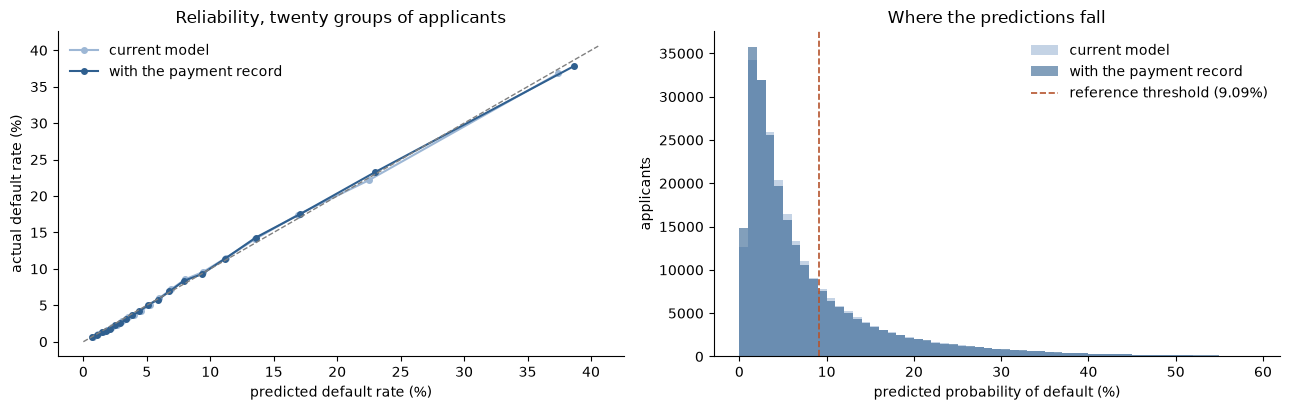

In [25]:
def reliability(p, bins=20):
    order = np.argsort(p)
    groups = np.array_split(order, bins)
    table = pd.DataFrame({'predicted_pct': [p[g].mean() * 100 for g in groups], 'actual_pct': [y_arr[g].mean() * 100 for g in groups], 'applicants': [len(g) for g in groups]})
    table['gap'] = table['predicted_pct'] - table['actual_pct']
    return table

def calibration_error(p, bins=20):
    t = reliability(p, bins)
    return float((t['gap'].abs() * t['applicants']).sum() / t['applicants'].sum()), float(t['gap'].abs().max())

report = {}
for label, p in {'current model': p_old, 'with the payment record': p_new, 'with the payment record, before calibration': final_run['oof']}.items():
    error, worst = calibration_error(p)
    report[label] = {'mean_prediction_pct': p.mean() * 100, 'actual_pct': y_arr.mean() * 100, 'calibration_error_pts': error, 'largest_gap_in_any_twentieth_pts': worst}
print(pd.DataFrame(report).T.to_string(float_format=lambda v: f'{v:.3f}'))

tenths = pd.DataFrame({'current: predicted': reliability(p_old, 10)['predicted_pct'], 'current: actual': reliability(p_old, 10)['actual_pct'],
                       'new: predicted': reliability(p_new, 10)['predicted_pct'], 'new: actual': reliability(p_new, 10)['actual_pct']})
tenths.index = [f'tenth {i + 1}' for i in range(10)]
print('\npredicted and actual default rate (%) by tenth of applicants, safest first:')
print(tenths.to_string(float_format=lambda v: f'{v:.2f}'))
print(f"\nthe new model spreads applicants further: safest tenth {tenths.iloc[0, 3]:.2f}% against {tenths.iloc[0, 1]:.2f}%, riskiest tenth {tenths.iloc[-1, 3]:.2f}% against {tenths.iloc[-1, 1]:.2f}%")
print(f"share of all defaults in the riskiest tenth: {tenths.iloc[-1, 1] / tenths['current: actual'].sum():.1%} -> {tenths.iloc[-1, 3] / tenths['new: actual'].sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for label, p, colour in [('current model', p_old, '#9db7d5'), ('with the payment record', p_new, '#2f5f8f')]:
    t = reliability(p)
    axes[0].plot(t['predicted_pct'], t['actual_pct'], marker='o', markersize=4, label=label, color=colour)
limit = max(reliability(p_new)['predicted_pct'].max(), reliability(p_new)['actual_pct'].max()) * 1.05
axes[0].plot([0, limit], [0, limit], color='grey', linestyle='--', linewidth=1)
axes[0].set_xlabel('predicted default rate (%)'); axes[0].set_ylabel('actual default rate (%)'); axes[0].set_title('Reliability, twenty groups of applicants'); axes[0].legend(frameon=False)
axes[1].hist(p_old * 100, bins=np.arange(0, 60, 1), alpha=0.6, label='current model', color='#9db7d5')
axes[1].hist(p_new * 100, bins=np.arange(0, 60, 1), alpha=0.6, label='with the payment record', color='#2f5f8f')
axes[1].axvline(THRESHOLD * 100, color='#b5542d', linestyle='--', linewidth=1.2, label=f'reference threshold ({THRESHOLD:.2%})')
axes[1].set_xlabel('predicted probability of default (%)'); axes[1].set_ylabel('applicants'); axes[1].set_title('Where the predictions fall'); axes[1].legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

### 7.3 Within groups

The groups of stage 2, with a few more. As there, they were chosen from what notebook 07 found to matter, before looking at the new model's gaps.

Several are defined by features the pruned model does not use: instalments late in the last six months, unpaid instalments, and days since the last penalty. For those the model has to be right without being told directly who they are.

In [26]:
age = -X_dev['DAYS_BIRTH'].values / 365.25
early_days = inst('MEAN_DAYS_EARLY')
calibration_groups = {
    'no payment history': ~has_payments, 'has a payment history': has_payments,
    'never late by over 5 days': (inst('SHARE_LATE_5D') == 0).values, 'late by over 5 days at some time': (inst('SHARE_LATE_5D') > 0).values,
    'late by over 5 days in the last 6 months': (inst('N_LATE_5D_6M') > 0).values, 'late on over 20% of instalments': (inst('SHARE_LATE_5D') > 0.20).values,
    'a penalty charge at some time': (inst('N_PENALTIES') > 0).values, 'a penalty charge in the last 24 months': (inst('N_PENALTIES_24M') > 0).values,
    'an unpaid instalment': ((inst('N_UNPAID_RECENT') + inst('N_UNPAID_OLDER')) > 0).values,
    'paid in parts over 15% of the time': (inst('SHARE_PAID_IN_PARTS') > 0.15).values, 'paid less than was due at some time': (inst('N_SHORT') > 0).values,
    'pays under 3 days early on average': (early_days < 3).values, 'pays over 15 days early on average': (early_days > 15).values,
    'has card payments': (inst('CARD_N_INSTALMENTS') > 0).values,
    'no bureau record': ~has_bureau, 'no earlier application': ~has_prev,
    'men': (X_dev['CODE_GENDER'] == 'M').values, 'women': (X_dev['CODE_GENDER'] == 'F').values,
    'under 30': age < 30, 'over 60': age >= 60,
    'cash loans': (X_dev['NAME_CONTRACT_TYPE'] == 'Cash loans').values, 'revolving loans': (X_dev['NAME_CONTRACT_TYPE'] == 'Revolving loans').values,
}
N_PAYMENT_GROUPS = 14
defining = ['SHARE_LATE_5D', 'N_LATE_5D_6M', 'N_PENALTIES', 'N_PENALTIES_24M', 'N_UNPAID_RECENT', 'N_UNPAID_OLDER', 'SHARE_PAID_IN_PARTS', 'N_SHORT', 'MEAN_DAYS_EARLY', 'CARD_N_INSTALMENTS']
print('features used to define groups that the model itself does not use:', [c for c in defining if 'INST_' + c not in CHOSEN_FEATURES])

rows = {}
for label, m in calibration_groups.items():
    actual = y_arr[m].mean()
    se = np.sqrt(actual * (1 - actual) / m.sum()) * 100
    rows[label] = {'applicants': int(m.sum()), 'actual_pct': actual * 100, 'current_model_pct': p_old[m].mean() * 100, 'new_model_pct': p_new[m].mean() * 100,
                   'gap_current': (p_old[m].mean() - actual) * 100, 'gap_new': (p_new[m].mean() - actual) * 100, 'standard_error': se}
groups_table = pd.DataFrame(rows).T
groups_table['gap_current_in_se'] = groups_table['gap_current'] / groups_table['standard_error']
groups_table['gap_new_in_se'] = groups_table['gap_new'] / groups_table['standard_error']
print()
print(groups_table.astype({'applicants': int}).to_string(float_format=lambda v: f'{v:,.2f}'))
payment_groups = list(calibration_groups)[:N_PAYMENT_GROUPS]
print(f"\nlargest gap in the {N_PAYMENT_GROUPS} groups defined by payment behaviour: {groups_table.loc[payment_groups, 'gap_current'].abs().max():.2f} points with the current model "
      f"({groups_table.loc[payment_groups, 'gap_current'].abs().idxmax()}), {groups_table.loc[payment_groups, 'gap_new'].abs().max():.2f} with the new one ({groups_table.loc[payment_groups, 'gap_new'].abs().idxmax()})")
off_new = list(groups_table.index[groups_table['gap_new_in_se'].abs() > 2])
print(f"groups more than 2 standard errors off: {int((groups_table['gap_current_in_se'].abs() > 2).sum())} with the current model, {len(off_new)} with the new one {off_new}")
print(f"average gap, weighted by group size: {np.average(groups_table['gap_current'].abs(), weights=groups_table['applicants']):.3f} -> {np.average(groups_table['gap_new'].abs(), weights=groups_table['applicants']):.3f} points")
fifth = pd.qcut(early_days, 5, labels=False)
print('\npredicted and actual default rate (%) by fifth of the average number of days paid early (lowest fifth pays closest to the due date):')
print(pd.DataFrame({'current model': pd.Series(p_old).groupby(fifth.values).mean() * 100, 'new model': pd.Series(p_new).groupby(fifth.values).mean() * 100,
                    'actual': pd.Series(y_arr).groupby(fifth.values).mean() * 100}).round(2).T.to_string())

features used to define groups that the model itself does not use: ['N_LATE_5D_6M', 'N_UNPAID_RECENT', 'N_UNPAID_OLDER']

                                          applicants  actual_pct  current_model_pct  new_model_pct  gap_current  gap_new  standard_error  gap_current_in_se  gap_new_in_se
no payment history                             12686        5.98               6.11           6.01         0.13     0.03            0.21               0.61           0.12
has a payment history                         233322        8.19               8.24           8.25         0.05     0.06            0.06               0.87           1.05
never late by over 5 days                     164187        7.39               7.96           7.46         0.57     0.07            0.06               8.78           1.06
late by over 5 days at some time               66918       10.01               8.79          10.04        -1.23     0.02            0.12             -10.57           0.21
late by over 5 days in 

                 0.0   1.0   2.0   3.0   4.0
current model   8.98  8.30  8.05  7.76  7.90
new model      10.01  8.50  7.87  7.31  7.34
actual          9.99  8.43  7.81  7.22  7.29


### 7.4 The operating point, and what it costs

The reference rule from notebook 02: decline when the predicted probability is 0.0909 or above. The same rule is applied to both models' calibrated probabilities.

Cost is counted in units of one wrongly declined good applicant: each good applicant declined costs 1, and each defaulter approved costs the ratio.

In [27]:
from scipy.stats import ks_2samp

def outcome(p, ratio):
    t = 1 / (1 + ratio)
    declined, bad = p >= t, y_arr == 1
    missed, wrongly = int((~declined & bad).sum()), int((declined & ~bad).sum())
    return {'threshold': t, 'approved_pct': (~declined).mean() * 100, 'defaults_caught_pct': (declined & bad).sum() / bad.sum() * 100,
            'default_rate_among_approved_pct': missed / (~declined).sum() * 100, 'good_applicants_declined_pct': wrongly / (~bad).sum() * 100,
            'cost_per_1000_applicants': (ratio * missed + wrongly) / len(p) * 1000}

rows = {}
for ratio in [5, 10, 20]:
    a, b = outcome(p_old, ratio), outcome(p_new, ratio)
    blanket = min(ratio * y_arr.mean(), 1 - y_arr.mean()) * 1000            # the better of approving everyone and declining everyone
    for label, o in [('current model', a), ('with the payment record', b)]:
        rows[(f'ratio {ratio}', label)] = {**o, 'saving_against_no_model_pct': (1 - o['cost_per_1000_applicants'] / blanket) * 100}
    rows[(f'ratio {ratio}', 'change')] = {k: b[k] - a[k] for k in a} | {'saving_against_no_model_pct': (a['cost_per_1000_applicants'] - b['cost_per_1000_applicants']) / blanket * 100}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:,.3f}'))

ref_old, ref_new = outcome(p_old, 10), outcome(p_new, 10)
assert abs(ref_old['threshold'] - THRESHOLD) < 1e-4
d_old, d_new, bad = p_old >= THRESHOLD, p_new >= THRESHOLD, y_arr == 1
print(f"\nat the reference threshold of {THRESHOLD:.4f}:")
print(pd.DataFrame({'current model': {'approved, repaid': int((~d_old & ~bad).sum()), 'approved, defaulted': int((~d_old & bad).sum()), 'declined, repaid': int((d_old & ~bad).sum()), 'declined, defaulted': int((d_old & bad).sum())},
                    'with the payment record': {'approved, repaid': int((~d_new & ~bad).sum()), 'approved, defaulted': int((~d_new & bad).sum()), 'declined, repaid': int((d_new & ~bad).sum()), 'declined, defaulted': int((d_new & bad).sum())}}
                   ).assign(change=lambda t: t['with the payment record'] - t['current model']).to_string())
print(f"\ncost per 1,000 applicants at a ratio of 10: {ref_old['cost_per_1000_applicants']:.1f} -> {ref_new['cost_per_1000_applicants']:.1f} ({(ref_new['cost_per_1000_applicants'] / ref_old['cost_per_1000_applicants'] - 1):+.1%})")
print(f"applicants whose decision changes: {(d_old != d_new).mean():.1%}; newly declined default at {y_arr[d_new & ~d_old].mean():.1%}, newly approved at {y_arr[~d_new & d_old].mean():.1%}")

ks = lambda p: ks_2samp(p[bad], p[~bad]).statistic
print(f"KS statistic: {ks(p_old):.4f} -> {ks(p_new):.4f}")
by_fold = pd.DataFrame({k: {'current model': (10 * (~d_old & bad)[dev_fold == k].sum() + (d_old & ~bad)[dev_fold == k].sum()) / (dev_fold == k).sum() * 1000,
                            'with the payment record': (10 * (~d_new & bad)[dev_fold == k].sum() + (d_new & ~bad)[dev_fold == k].sum()) / (dev_fold == k).sum() * 1000} for k in range(N_SPLITS)}).T
by_fold['change'] = by_fold['with the payment record'] - by_fold['current model']
print('\ncost per 1,000 applicants at a ratio of 10, by fold:')
print(by_fold.round(1).T.to_string())
print(f"lower cost with the payment record in {int((by_fold['change'] < 0).sum())} of 5 folds")

                                  threshold  approved_pct  defaults_caught_pct  default_rate_among_approved_pct  good_applicants_declined_pct  cost_per_1000_applicants  saving_against_no_model_pct
ratio 5  current model                0.167        87.281               42.638                            5.306                        10.091                   324.302                       19.657
         with the payment record      0.167        87.081               44.496                            5.145                        10.146                   317.303                       21.391
         change                       0.000        -0.200                1.858                           -0.160                         0.054                    -7.000                        1.734
ratio 10 current model                0.091        71.435               67.669                            3.654                        25.131                   492.029                       39.052
         with t

KS statistic: 0.4294 -> 0.4416



cost per 1,000 applicants at a ratio of 10, by fold:
                             0      1      2      3      4
current model            495.2  494.8  488.7  489.9  491.6
with the payment record  488.7  487.4  480.0  476.0  478.1
change                    -6.5   -7.4   -8.7  -13.9  -13.4
lower cost with the payment record in 5 of 5 folds


### 7.5 Approval rates by gender, age and kind of history

The gaps measured in notebooks 02, 04 and 06 are measured again, with one added: applicants who have been late against those who have not. That gap should widen. It is what the features are for, and it is behaviour and not a fixed attribute of the person. This section only measures.

In [28]:
fair_groups = {'gender': {'women': calibration_groups['women'], 'men': calibration_groups['men']},
               'age': {'under 30': age < 30, '30 to 45': (age >= 30) & (age < 45), '45 to 60': (age >= 45) & (age < 60), 'over 60': age >= 60},
               'bureau record': {'has a bureau record': has_bureau, 'no bureau record': ~has_bureau},
               'payment history': {'has a payment history': has_payments, 'no payment history': ~has_payments},
               'refused before': {'never refused': has_prev & ~(X_dev['PREV_N_REFUSED'] > 0).values, 'refused at least once': (X_dev['PREV_N_REFUSED'] > 0).values},
               'lateness': {'never late by over 5 days': calibration_groups['never late by over 5 days'], 'late by over 5 days at some time': calibration_groups['late by over 5 days at some time']},
               'penalties': {'no penalty charge': has_payments & ~calibration_groups['a penalty charge at some time'], 'a penalty charge at some time': calibration_groups['a penalty charge at some time']}}
rows = {}
for segment, members in fair_groups.items():
    old_rates = {g: (~d_old)[m].mean() for g, m in members.items()}
    new_rates = {g: (~d_new)[m].mean() for g, m in members.items()}
    for g, m in members.items():
        rows[(segment, g)] = {'applicants': int(m.sum()), 'default_pct': y_arr[m].mean() * 100, 'approved_current_pct': old_rates[g] * 100, 'approved_new_pct': new_rates[g] * 100,
                              'ratio_to_highest_current': old_rates[g] / max(old_rates.values()), 'ratio_to_highest_new': new_rates[g] / max(new_rates.values()),
                              'defaults_caught_current_pct': (d_old & bad)[m].sum() / bad[m].sum() * 100, 'defaults_caught_new_pct': (d_new & bad)[m].sum() / bad[m].sum() * 100}
fairness = pd.DataFrame(rows).T
print(fairness.astype({'applicants': int}).to_string(float_format=lambda v: f'{v:,.2f}'))
print()
for segment, low in [('gender', 'men'), ('age', 'under 30'), ('bureau record', 'no bureau record'), ('refused before', 'refused at least once'), ('lateness', 'late by over 5 days at some time'),
                     ('penalties', 'a penalty charge at some time')]:
    print(f"{low} against the highest in '{segment}': {fairness.loc[(segment, low), 'ratio_to_highest_current']:.3f} -> {fairness.loc[(segment, low), 'ratio_to_highest_new']:.3f}")

                                                  applicants  default_pct  approved_current_pct  approved_new_pct  ratio_to_highest_current  ratio_to_highest_new  defaults_caught_current_pct  defaults_caught_new_pct
gender          women                                 161887         7.00                 76.29             76.47                      1.00                  1.00                        62.77                    63.68
                men                                    84119        10.14                 62.09             62.82                      0.81                  0.82                        74.18                    74.64
age             under 30                               36281        11.48                 54.17             55.16                      0.63                  0.64                        78.25                    78.73
                30 to 45                               98993         9.04                 67.67             68.19                      0

### Stage 7 findings

**Calibrated, the model is better on every measure**

| Measure | Current model | With the payment record | Change | Folds better |
|---|---:|---:|---:|---:|
| ROC AUC | 0.7856 | 0.7932 | +0.0075 | 5 of 5 |
| PR AUC | 0.2768 | 0.2848 | +0.0080 | 5 of 5 |
| Log loss | 0.2377 | 0.2353 | -0.0024 | 5 of 5 |
| Brier score | 0.0661 | 0.0656 | -0.0005 | 5 of 5 |

- Before calibration the model predicts 13.2% on average against an actual 8.07%. After Platt scaling it predicts 8.13%.
- The distortion is still a plain shift, with a correcting slope between 0.97 and 1.02 in every fold. The method of notebook 02 still fits.
- Calibration changes ROC AUC by exactly zero.

**Across the range the probabilities are right, with one tenth a little off**
- The average calibration error is 0.28 points, the same as the current model's.
- The largest gap in any twentieth of applicants is 0.83 points, against 0.61. It is among safe applicants, where the model predicts slightly too much: in the fourth tenth it predicts 3.13% and 2.81% default.
- The model spreads applicants further again. The safest tenth defaults at 0.78% (0.89% before) and the riskiest at 30.6% (29.5%). The riskiest tenth holds 37.8% of all defaults.

**The gaps found in stage 2 close, all but one**

| Group | Applicants | Actual | Current model | New model |
|---|---:|---:|---:|---:|
| A penalty charge in the last 24 months | 2,567 | 23.92% | 14.25% | 23.39% |
| A penalty charge at some time | 7,246 | 15.14% | 10.94% | 14.82% |
| Late by over 5 days in the last 6 months | 5,707 | 15.44% | 10.91% | 15.21% |
| Late on over 20% of instalments | 11,997 | 13.48% | 10.28% | 13.20% |
| Paid less than was due at some time | 1,512 | 16.01% | 10.60% | 15.32% |
| Paid in parts over 15% of the time | 31,057 | 11.86% | 9.90% | 11.97% |
| Pays under 3 days early on average | 15,307 | 11.18% | 9.45% | 11.12% |
| Pays over 15 days early on average | 65,350 | 7.11% | 7.82% | 7.25% |
| Never late by over 5 days | 164,187 | 7.39% | 7.96% | 7.46% |
| **An unpaid instalment** | 397 | 27.20% | 14.20% | **19.74%** |

- Of 22 groups, the current model is more than two standard errors from the actual rate for **12**. The new model is for **1**. The average gap across groups falls from 0.42 points to 0.08.
- The current model gave applicants with a recent penalty 14.3% when 23.9% default. The new model gives 23.4%. For those late in the last six months it gives 15.2% against an actual 15.4%, although the feature that counts those instalments was dropped in stage 4. The model is right for that group from the features it kept.
- By how early applicants pay, the new model follows the actual rates in every fifth, from 10.0% for those who pay closest to the due date to 7.3% for those who pay earliest. The current model was nearly flat across them.
- The same caution as before: the groups were chosen knowing where the current model was weak, so the 12 is not a neutral count. The 1 is the result.

**The one group still wrong, and why**
- The 397 applicants with an unpaid instalment default at 27.2%. The new model gives them 19.7%, up from 14.2% and still 7.5 points short, more than three standard errors.
- Stage 4 dropped one unpaid feature and stage 5 the other, on the evidence that these applicants were ranked the same with or without them. That evidence stands: the model with both features placed them no higher. So keeping the features would not have closed this gap.
- A likely reason is a setting. The model requires at least 803 applicants in every leaf of every tree, a value found by the search in notebook 02 and good for the score as a whole. A group of 397 can never have a leaf of its own, so no tree can single it out, whatever feature marks it. The model can only reach these applicants through features that describe larger groups they belong to. I have not tested this by fitting a model with smaller leaves, and it should be read as an explanation that fits, not a finding.
- It is a real limit, for a few applicants in ten thousand: the highest-risk group in the table is the one the model cannot see directly.

**At the reference threshold the model approves more people and catches more defaults**

| | Current model | With the payment record | Change |
|---|---:|---:|---:|
| Approved | 71.44% | 71.80% | +0.36 |
| Defaults caught | 67.67% | 68.38% | +0.72 |
| Default rate among approved | 3.65% | 3.56% | -0.10 |
| Good applicants declined | 25.13% | 24.67% | -0.46 |
| Cost per 1,000 applicants, ratio 10 | 492.0 | 482.0 | -2.0% |

- In the development set that is 142 more defaults declined and 1,037 more good applicants approved, at the same threshold.
- The cost falls in all five folds, by between 7 and 14 per 1,000 applicants. At cost ratios of 5 and 20 it falls by 2.2% and 2.0%.
- 6.5% of applicants get a different decision. Those newly declined default at 11.0% and those newly approved at 8.2%.
- The KS statistic rises from 0.429 to 0.442.
- Over four models the cost at the reference point has gone 516, 503, 492, 482 per 1,000 applicants, and defaults caught 65.4%, 66.7%, 67.7%, 68.4%, with a few more applicants approved each time.

**Approval rates by group**

| Comparison | Current model | With the payment record |
|---|---:|---:|
| Men against women | 0.81 | 0.82 |
| Under 30 against over 60 | 0.63 | 0.64 |
| No bureau record against a record | 0.83 | 0.84 |
| Refused before against never refused | 0.82 | 0.82 |
| Late by over 5 days at some time against never | 0.95 | 0.86 |
| A penalty charge at some time against none | 0.83 | 0.66 |

- The gaps by gender, age, bureau record and earlier refusal are unchanged or a little narrower. Each of the four disadvantaged groups is approved slightly more often than before.
- Two gaps widen sharply, and they are the two this table creates. Applicants who have been late are approved at 0.86 times the rate of those who have not, down from 0.95. Applicants who have been charged a penalty are approved at 0.66 times the rate of those who have not, down from 0.83: fewer than half of them are now approved.
- These are different in kind from the gap notebook 06 flagged for refused applicants. A refusal is the lender's judgement. A late payment is something the applicant did. A lender declining someone because they paid the same lender late is on firmer ground than declining them because it once declined them.
- Two cautions remain. Stage 5 of notebook 07 found that lateness more than four years old says almost nothing about default, and the model's penalty count covers all eight years (the 24-month count is there as well). And the penalty reading is an inference from the pattern of the rows. Both go to the conclusions.
- Among applicants who have been late, the share of defaults caught rises from 67.3% to 73.2%. Among those who never have, it falls from 67.9% to 65.8%, as the model approves more of them.

**Leakage check for this stage**
- The calibrator is fitted inside the training folds, on predictions the model made for rows it had not seen.
- The calibration method and the threshold were taken from notebook 02 unchanged. Nothing was chosen in this stage.
- All figures are out-of-fold on the frozen folds. The holdout was not used.

**Decisions**
- The model carried forward is the 108-feature model with Platt scaling, and the reference threshold stays at 0.0909.
- For the conclusions: the minimum leaf size as a limit on rare groups, and how far back lateness should count.

## Stage 8: Explainability

What does the model now say about an applicant, and can it be said to them?

Notebook 06 ended with two concerns about the reasons the model gives. The external scores were still the main reason for 59% of declines, and they cannot be explained. And two of the new reasons, the price of earlier loans and earlier refusals, were the lender's own past decisions about the applicant.

Payment behaviour is neither of those. It is a record of what the applicant did, which they can recognise and could have done differently. "You paid nine of your last thirty instalments late" is a reason of a kind the model has not been able to give until now.

**Method**, as in notebooks 02, 04 and 06. Both models are fitted on the whole development set with calibration. For a sample of 20,000 applicants, each prediction is split into one contribution per feature (SHAP values, computed exactly by LightGBM), in the same calibrated log-odds as the probability. A contribution above zero pushes the applicant's risk up. A family's contribution is the sum over its features.

| Section | What it does |
|---|---|
| 8.1 | Fit both models and check the contributions add up |
| 8.2 | What each model relies on, by family and by feature |
| 8.3 | What the leading new features say |
| 8.4 | Reasons for a decline, before and after |
| 8.5 | Two applicants whose decision changed |
| 8.6 | Do the explanations hold for applicants the model has not seen? |

### 8.1 Fit and check

In [29]:
import hashlib, joblib, lightgbm, sklearn

MODEL_DIR = CACHE_DIR / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def fitted(tag, build):
    # a fitted pipeline, saved to disk so that a later run does not have to fit it again
    path = MODEL_DIR / f'{tag}.joblib'
    if path.exists():
        return joblib.load(path), True
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        model = build()
    joblib.dump(model, path, compress=3)
    return model, False

def model_tag(prefix, features, params, trees, rows):
    spec = {'features': list(features), 'params': {k: repr(v) for k, v in sorted(params.items())}, 'trees': trees, 'rate': LEARNING_RATE, 'rows': rows, 'seed': SEED,
            'module': hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest(), 'versions': [lightgbm.__version__, sklearn.__version__]}
    return prefix + '_' + hashlib.md5(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:16]

started = time.time()
new_model, c1 = fitted(model_tag('dev_with_installments', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'dev'),
                       lambda: make_pipeline(CHOSEN_FEATURES, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt')).fit(X_dev, y_arr))
old_model, c2 = fitted(model_tag('dev_current', CURRENT, BEST_PARAMS, N_TREES, 'dev'),
                       lambda: make_pipeline(CURRENT, TEXT_FEATURES, CalibratedModel(FINAL(), method='platt')).fit(X_dev, y_arr))
print(f"both models fitted on the development set: {(time.time() - started) / 60:.1f} minutes ({int(c1) + int(c2)} of 2 loaded from disk)")

def explain_sample(model, X_raw):
    # contributions in calibrated log-odds, one column per feature, plus the starting point
    prepared = model.named_steps['preprocess'].transform(X_raw)
    calibrated_step = model.named_steps['model']
    a, b = float(calibrated_step.calibrator_.coef_[0, 0]), float(calibrated_step.calibrator_.intercept_[0])
    out = calibrated_step.model_.booster_.predict(prepared, pred_contrib=True)
    return pd.DataFrame(a * out[:, :-1], columns=list(prepared.columns), index=X_raw.index), float(a * out[0, -1] + b), (a, b)

sample_rows = np.sort(np.random.default_rng(SEED).choice(len(X_dev), size=20_000, replace=False))       # the same sample as notebooks 02 and 04
X_sample, y_sample = X_dev.iloc[sample_rows], y_arr[sample_rows]
started = time.time()
shap_new, base_new, line_new = explain_sample(new_model, X_sample)
shap_old, base_old, line_old = explain_sample(old_model, X_sample)
print(f"contributions for {len(X_sample):,} applicants under both models in {time.time() - started:.0f} seconds")

sigmoid = lambda z: 1 / (1 + np.exp(-z))
p_fit_new, p_fit_old = new_model.predict_proba(X_sample)[:, 1], old_model.predict_proba(X_sample)[:, 1]
checks = {
    'with the payment record: contributions and starting point rebuild the probability': float(np.abs(sigmoid(shap_new.sum(axis=1).values + base_new) - p_fit_new).max()),
    'current model: the same': float(np.abs(sigmoid(shap_old.sum(axis=1).values + base_old) - p_fit_old).max()),
}
for name, gap in checks.items():
    print(f"largest difference, {name}: {gap:.1e}")
assert max(checks.values()) < 1e-9
print(f"\nstarting point: current model {sigmoid(base_old):.2%}, with the payment record {sigmoid(base_new):.2%}")
print(f"calibration line: current model {line_old[0]:.4f} x log-odds {line_old[1]:+.4f}; with the payment record {line_new[0]:.4f} x log-odds {line_new[1]:+.4f}")
print(f"average predicted probability in the sample: {p_fit_old.mean():.2%} and {p_fit_new.mean():.2%}; actual default rate in the sample {y_sample.mean():.2%}")
print(f"features explained: {shap_old.shape[1]} and {shap_new.shape[1]}")
assert list(shap_new.columns) == list(CHOSEN_FEATURES) and list(shap_old.columns) == list(CURRENT)

both models fitted on the development set: 0.0 minutes (2 of 2 loaded from disk)


contributions for 20,000 applicants under both models in 71 seconds


largest difference, with the payment record: contributions and starting point rebuild the probability: 4.1e-15
largest difference, current model: the same: 3.8e-15

starting point: current model 5.37%, with the payment record 5.25%
calibration line: current model 0.9949 x log-odds -0.6424; with the payment record 0.9952 x log-odds -0.6383
average predicted probability in the sample: 8.05% and 8.08%; actual default rate in the sample 7.90%
features explained: 85 and 108


### 8.2 What each model relies on

In [30]:
APP_FAMILIES = {            # the families of notebook 02, stage 12
    'external scores': [c for c in APP_IN_MODEL if c.startswith('EXT_')],
    'loan and amounts': ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'ANNUITY_TO_CREDIT', 'CREDIT_TO_GOODS', 'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME', 'NAME_CONTRACT_TYPE'],
    'age, gender, education, family': ['DAYS_BIRTH', 'CODE_GENDER', 'EDUCATION_LEVEL', 'NAME_FAMILY_STATUS'],
    'employment': ['DAYS_EMPLOYED', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE'],
    'documents, phone and registration': ['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'FLAG_DOCUMENT_3', 'FLAG_WORK_PHONE'],
    'housing, car and region': ['OWN_CAR_AGE', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'REGION_RATING_CLIENT_W_CITY', 'REG_CITY_NOT_LIVE_CITY'],
    'social circle and bureau enquiries': ['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'AMT_REQ_CREDIT_BUREAU_YEAR'],
}
assert sorted(c for members in APP_FAMILIES.values() for c in members) == sorted(APP_IN_MODEL)
OLD_FAMILIES = {**APP_FAMILIES, 'credit bureau': list(BUREAU_IN_MODEL), 'earlier applications': list(PREV_IN_MODEL)}
ALL_FAMILIES = {**OLD_FAMILIES, 'payment record': list(KEPT_INST)}
family_of = {c: f for f, members in ALL_FAMILIES.items() for c in members}
NEW = 'payment record'

size_old, size_new = shap_old.abs().mean(), shap_new.abs().mean()
by_family = pd.DataFrame({'features': {f: len(m) for f, m in ALL_FAMILIES.items()},
                          'current: share (%)': {f: size_old.reindex(m).sum() / size_old.sum() * 100 for f, m in ALL_FAMILIES.items()},
                          'new: share (%)': {f: size_new.reindex(m).sum() / size_new.sum() * 100 for f, m in ALL_FAMILIES.items()},
                          'current: size': {f: size_old.reindex(m).sum() for f, m in ALL_FAMILIES.items()},
                          'new: size': {f: size_new.reindex(m).sum() for f, m in ALL_FAMILIES.items()}}).fillna(0)
by_family['change in size (%)'] = (by_family['new: size'] / by_family['current: size'].where(by_family['current: size'] > 0) - 1) * 100
print("share of each model's total contribution, by family ('size' is the summed average contribution of the family's features, in log-odds):")
print(by_family.sort_values('new: share (%)', ascending=False).to_string(float_format=lambda v: f'{v:.2f}'))

sub = pd.Series({c: FAMILY[c] for c in KEPT_INST})
sub_table = pd.DataFrame({'features': sub.value_counts(), 'share of the model (%)': size_new[KEPT_INST].groupby(sub).sum() / size_new.sum() * 100,
                          'share of the new family (%)': size_new[KEPT_INST].groupby(sub).sum() / size_new[KEPT_INST].sum() * 100}).sort_values('share of the model (%)', ascending=False)
print('\ninside the payment-record family:')
print(sub_table.to_string(float_format=lambda v: f'{v:.2f}'))

top = pd.DataFrame({'family': pd.Series(family_of), 'new model': size_new, 'current model': size_old}).sort_values('new model', ascending=False)
top['rank'] = np.arange(1, len(top) + 1)
top['rank before'] = top['current model'].rank(ascending=False)
top['change (%)'] = (top['new model'] / top['current model'] - 1) * 100
print('\nthe twenty features the new model relies on most (average size of contribution):')
print(top.head(20).to_string(float_format=lambda v: f'{v:.3f}'))
first_new = top.index[top['family'] == NEW][0]
print(f"\npayment-record features in the top 10: {int((top.head(10)['family'] == NEW).sum())}; in the top 20: {int((top.head(20)['family'] == NEW).sum())}; highest-ranked: {first_new} at {int(top.loc[first_new, 'rank'])}")
print(f"credit bureau features in the top 20: {int((top.head(20)['family'] == 'credit bureau').sum())}")

gave_way = top.dropna(subset=['current model']).sort_values('change (%)')
print('\nthe ten features of the current model that give way most (among its 30 largest):')
print(gave_way[gave_way['rank before'] <= 30].head(10)[['family', 'current model', 'new model', 'change (%)']].to_string(float_format=lambda v: f'{v:.3f}'))
new_sum = shap_new[KEPT_INST].sum(axis=1)
print(f"\ncorrelation between the two models' total log-odds: {(shap_new.sum(axis=1)).corr(shap_old.sum(axis=1)):.3f}")
print('correlation, across applicants, between what the payment record contribute now and what each family contributed before:')
print(pd.Series({f: new_sum.corr(shap_old[m].sum(axis=1)) for f, m in OLD_FAMILIES.items()}).sort_values(ascending=False).round(3).to_string())

share of each model's total contribution, by family ('size' is the summed average contribution of the family's features, in log-odds):
                                    features  current: share (%)  new: share (%)  current: size  new: size  change in size (%)
payment record                            23                0.00           17.45           0.00       0.69                 NaN
external scores                            8               20.03           17.21           0.70       0.68               -3.19
earlier applications                      25               21.59           15.98           0.76       0.63              -16.56
credit bureau                             24               17.33           13.89           0.61       0.55               -9.73
loan and amounts                           8               13.97           11.50           0.49       0.45               -7.24
age, gender, education, family             4                9.33            8.51           0.33       0

earlier applications                  0.203
external scores                       0.148
loan and amounts                      0.123
documents, phone and registration     0.115
credit bureau                         0.091
social circle and bureau enquiries    0.085
employment                            0.078
age, gender, education, family        0.050
housing, car and region               0.030


### 8.3 What the leading new features say

For the six new features the model relies on most, which way each pushes: the average contribution among applicants in each fifth of the feature's values, and among those for whom it is missing. A value above zero raises the predicted risk. The fifths are cut on the sample being explained and nothing is fitted to them.

In [31]:
leading_new = [c for c in top.index if family_of[c] == NEW][:6]
rows = {}
for c in leading_new:
    values, contribution = X_sample[c], shap_new[c]
    has = values.notna()
    fifth = pd.qcut(values[has].rank(method='first'), 5, labels=['lowest fifth', 'second', 'middle', 'fourth', 'highest fifth'])
    by_fifth = contribution[has].groupby(fifth, observed=True).mean()
    edges = values[has].quantile([0.2, 0.8])
    rows[short(c)] = {**by_fifth.to_dict(), 'missing': contribution[~has].mean() if (~has).any() else np.nan, 'missing_pct': (~has).mean() * 100,
                                   'value at the 20th percentile': edges.iloc[0], 'value at the 80th percentile': edges.iloc[1],
                                   'rank correlation of value and contribution': values[has].corr(contribution[has], method='spearman')}
direction = pd.DataFrame(rows).T
print('average contribution in log-odds (above zero raises risk):')
print(direction.to_string(float_format=lambda v: f'{v:,.3f}'))
print('\nthe same as odds multipliers, lowest and highest fifth:')
print(np.exp(direction[['lowest fifth', 'highest fifth', 'missing']]).to_string(float_format=lambda v: f'{v:.2f}'))

# actual default rates in the same fifths, from the labels of the sample: does the direction the model learned match what happened?
actual = {}
for c in leading_new:
    values = X_sample[c]
    has = values.notna().values
    fifth = pd.qcut(values[has].rank(method='first'), 5, labels=False).values
    actual[short(c)] = {'lowest fifth': y_sample[has][fifth == 0].mean() * 100, 'highest fifth': y_sample[has][fifth == 4].mean() * 100,
                                      'missing': y_sample[~has].mean() * 100 if (~has).any() else np.nan}
print('\nactual default rate (%) in the lowest and highest fifth:')
print(pd.DataFrame(actual).T.to_string(float_format=lambda v: f'{v:.2f}'))

average contribution in log-odds (above zero raises risk):
                         lowest fifth  second  middle  fourth  highest fifth  missing  missing_pct  value at the 20th percentile  value at the 80th percentile  rank correlation of value and contribution
N_INSTALMENTS                   0.135   0.097   0.017  -0.063         -0.203   -0.005        5.055                         9.000                        40.000                                      -0.971
MEDIAN_AMT_DUE                  0.112   0.031  -0.013  -0.051         -0.082   -0.015        5.885                     5,940.630                    19,630.013                                      -0.981
DAYS_SINCE_LAST_LATE_5D         0.252   0.192   0.039  -0.042         -0.113   -0.026       72.135                       386.000                     2,036.000                                      -0.960
CARD_MEAN_PAYMENT_12M          -0.027   0.080   0.154   0.178          0.238   -0.029       81.785                       283.230 

### 8.4 Reasons for a decline

For each declined applicant, the main reason is the family whose features together push the risk up the most. Under the current model the external scores were the main reason for 59% of declines.

In [32]:
def family_push(shap, families):
    return pd.DataFrame({f: shap[[c for c in members if c in shap.columns]].sum(axis=1) for f, members in families.items() if any(c in shap.columns for c in members)})

push_old, push_new = family_push(shap_old, OLD_FAMILIES), family_push(shap_new, ALL_FAMILIES)
declined_old, declined_new = p_fit_old >= THRESHOLD, p_fit_new >= THRESHOLD
print(f"declined in the sample: {declined_old.mean():.1%} by the current model, {declined_new.mean():.1%} by the model with the payment record")

reasons = pd.DataFrame({'current: main reason (%)': push_old[declined_old].idxmax(axis=1).value_counts(normalize=True) * 100,
                        'new: main reason (%)': push_new[declined_new].idxmax(axis=1).value_counts(normalize=True) * 100,
                        'new: among the top two (%)': pd.Series({f: (push_new[declined_new].rank(axis=1, ascending=False)[f] <= 2).mean() * 100 for f in push_new.columns}),
                        'new: average odds multiplier among declined': np.exp(push_new[declined_new].mean())}).fillna(0).sort_values('new: main reason (%)', ascending=False)
print(reasons.to_string(float_format=lambda v: f'{v:.2f}'))

main_old, main_new = push_old[declined_old].idxmax(axis=1), push_new[declined_new].idxmax(axis=1)
print(f"\ndeclines whose main reason is an external score: {(main_old == 'external scores').mean():.1%} -> {(main_new == 'external scores').mean():.1%}")
print(f"declines whose main reason is the credit bureau family: {(main_old == 'credit bureau').mean():.1%} -> {(main_new == 'credit bureau').mean():.1%}")
print(f"declines whose main reason is the payment record: {(main_new == NEW).mean():.1%}; where they are among the top two: {reasons.loc[NEW, 'new: among the top two (%)']:.1f}%")
history = ['credit bureau', 'earlier applications', NEW]
print(f"declines whose main reason is a recorded credit history of any of the three kinds: {main_old.isin(history).mean():.1%} -> {main_new.isin(history).mean():.1%}")
others_outweigh = lambda push, declined: (push[declined].drop(columns='external scores').clip(lower=0).sum(axis=1) > push.loc[declined, 'external scores']).mean()
print(f"declines where the families other than the external scores, added together, push the risk up by more than the external scores do: {others_outweigh(push_old, declined_old):.1%} -> {others_outweigh(push_new, declined_new):.1%}")

# which single features are most often the largest payment-record reason for a decline
new_declined = shap_new.loc[declined_new, KEPT_INST]
leading = pd.DataFrame({'group': pd.Series({c: FAMILY[c] for c in KEPT_INST}), 'largest reason in the family (%)': new_declined.idxmax(axis=1).value_counts(normalize=True) * 100,
                        'pushes risk up for (% of declined)': (new_declined > 0.05).mean() * 100,
                        'average odds multiplier when it does': np.exp(new_declined.where(new_declined > 0.05).mean())}).fillna({'largest reason in the family (%)': 0}).sort_values('largest reason in the family (%)', ascending=False)
leading.index = [short(c) for c in leading.index]
print('\namong declined applicants, the payment-record feature that pushes risk up the most:')
print(leading.head(12).to_string(float_format=lambda v: f'{v:.2f}'))
by_group = leading.groupby('group')['largest reason in the family (%)'].sum().sort_values(ascending=False)
print('\nthe same, added up by kind of fact (%):')
print(by_group.round(1).to_string())
print(f"\ndeclined applicants for whom the payment record as a whole lower the risk: {(push_new.loc[declined_new, NEW] < 0).mean():.1%}; "
      f"approved applicants for whom they raise it: {(push_new.loc[~declined_new, NEW] > 0).mean():.1%}")

# the five rare-event features kept by rule 2 of stage 5: what they do for the applicants they concern
rare_rows = {}
for c in RARE_EVENTS:
    if c in shap_new.columns:
        event = (X_sample[c] > 0).values
        rare_rows[short(c)] = {'applicants with the event in the sample': int(event.sum()), 'average odds multiplier for them': float(np.exp(shap_new.loc[event, c].mean())),
                                             'average odds multiplier for the rest': float(np.exp(shap_new.loc[~event, c].mean())), 'share of the model (%)': size_new[c] / size_new.sum() * 100}
print('\nthe rare-event features kept in stage 5 (those dropped there are not in the model and are not listed):')
print(pd.DataFrame(rare_rows).T.astype({'applicants with the event in the sample': int}).to_string(float_format=lambda v: f'{v:.3f}'))

declined in the sample: 28.2% by the current model, 27.8% by the model with the payment record


                                    current: main reason (%)  new: main reason (%)  new: among the top two (%)  new: average odds multiplier among declined
external scores                                        59.31                 55.59                       69.70                                         1.77
earlier applications                                   14.75                 13.07                       26.30                                         1.17
payment record                                          0.00                 12.42                       29.32                                         1.18
loan and amounts                                       12.70                  8.10                       24.91                                         1.13
credit bureau                                           7.92                  6.32                       23.69                                         1.16
age, gender, education, family                          2.57    

### 8.5 Two applicants whose decision changed

One applicant the current model would approve and the new model declines, and one the other way round. For each, the six largest contributions under the new model are shown, with the value of the feature.

In [33]:
def show(position, top_n=6):
    row, contributions = X_sample.iloc[position], shap_new.iloc[position]
    order = contributions.abs().sort_values(ascending=False).index[:top_n]
    def readable(c):
        v = row[c]
        if isinstance(v, str) or pd.isna(v):
            return 'missing' if not isinstance(v, str) else v
        if c.startswith('DAYS_'):
            return f'{-v / 365.25:.1f} years'
        if 'DAYS' in c:
            return f'{v:,.0f} days'
        return f'{v:,.3f}' if abs(v) < 10 else f'{v:,.0f}'
    table = pd.DataFrame({'family': [family_of[c] for c in order], 'value': [readable(c) for c in order], 'contribution': contributions[order].values,
                          'odds_multiplier': np.exp(contributions[order].values)}, index=[c.replace('BUREAU_', 'bureau: ').replace('PREV_', 'earlier: ').replace('INST_', 'payments: ') for c in order])
    table['direction'] = np.where(table['contribution'] > 0, 'raises risk', 'lowers risk')
    rest = contributions.drop(order).sum()
    print(f"  current model: {p_fit_old[position]:.2%}   with the payment record: {p_fit_new[position]:.2%}   (threshold {THRESHOLD:.2%}; in fact {'defaulted' if y_sample[position] == 1 else 'repaid'})")
    print(f"  family totals: external scores x{np.exp(push_new['external scores'].iloc[position]):.2f}, credit bureau x{np.exp(push_new['credit bureau'].iloc[position]):.2f}, "
          f"payment record x{np.exp(push_new[NEW].iloc[position]):.2f}, everything else x{np.exp(push_new.drop(columns=['external scores', 'credit bureau', NEW]).iloc[position].sum()):.2f}")
    print(table.to_string(float_format=lambda v: f'{v:.3f}'))
    print(f"  all other features together: x{np.exp(rest):.2f}\n")

newly_declined = np.where(declined_new & ~declined_old)[0]
newly_approved = np.where(~declined_new & declined_old)[0]
print(f"in the sample: {len(newly_declined):,} newly declined, {len(newly_approved):,} newly approved")
pick_declined = newly_declined[np.argsort(-push_new[NEW].values[newly_declined])[len(newly_declined) // 10]]       # a clear case, not the most extreme one
pick_approved = newly_approved[np.argsort(push_new[NEW].values[newly_approved])[len(newly_approved) // 10]]
print(f"\nNEWLY DECLINED (applicant {X_sample.index[pick_declined]}):")
show(pick_declined)
print(f"NEWLY APPROVED (applicant {X_sample.index[pick_approved]}):")
show(pick_approved)
print(f"among the newly declined, the payment record raises risk for {(push_new[NEW].values[newly_declined] > 0).mean():.1%}; among the newly approved, it lowers risk for {(push_new[NEW].values[newly_approved] < 0).mean():.1%}")
print(f"in the sample the newly declined defaulted at {y_sample[newly_declined].mean():.1%} and the newly approved at {y_sample[newly_approved].mean():.1%} "
      '(these applicants were in the training data of both models, so the out-of-fold figures of stage 7 are the ones to rely on)')

in the sample: 575 newly declined, 667 newly approved

NEWLY DECLINED (applicant 254968):
  current model: 9.00%   with the payment record: 20.87%   (threshold 9.09%; in fact repaid)
  family totals: external scores x1.86, credit bureau x0.75, payment record x2.31, everything else x1.48
                                             family     value  contribution  odds_multiplier    direction
EXT_MEAN                            external scores     0.291         0.374            1.454  raises risk
payments: DAYS_SINCE_LAST_LATE_5D    payment record  260 days         0.240            1.271  raises risk
EXT_MAX                             external scores     0.291         0.239            1.270  raises risk
payments: N_INSTALMENTS              payment record     6.000         0.194            1.214  raises risk
ANNUITY_TO_CREDIT                  loan and amounts     0.054         0.156            1.169  raises risk
payments: SHARE_PAID_IN_PARTS_12M    payment record     0.400         0.138 

### 8.6 Do the explanations hold for unseen applicants?

A second model is fitted without fold 0, and both models explain the applicants in the sample who are in fold 0, whom the second model has never seen.

In [34]:
in_fold0 = dev_fold[sample_rows] == 0
keep0 = dev_fold != 0
unseen_model, was_loaded = fitted(model_tag('without_fold0', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'dev without fold 0'),
                                  lambda: make_pipeline(CHOSEN_FEATURES, TEXT_FEATURES, MODEL()).fit(X_dev[keep0], y_arr[keep0]))
prepared = unseen_model.named_steps['preprocess'].transform(X_sample[in_fold0])
raw_unseen = pd.DataFrame(unseen_model.named_steps['model'].booster_.predict(prepared, pred_contrib=True)[:, :-1], columns=list(prepared.columns), index=prepared.index)
raw_seen = shap_new[in_fold0] / line_new[0]                                   # the final model, before the calibration rescaling, same applicants

fam = lambda s: family_push(s, ALL_FAMILIES)
share = lambda s, members: float(s[members].abs().mean().sum() / s.abs().mean().sum() * 100)
ext = APP_FAMILIES['external scores']
row_corr = np.array([np.corrcoef(raw_unseen.values[i], raw_seen.values[i])[0, 1] for i in range(len(raw_seen))])
agreement = pd.Series({
    'applicants compared (in fold 0, unseen by the second model)': int(in_fold0.sum()),
    'rank agreement on overall feature importance (Spearman)': raw_unseen.abs().mean().corr(raw_seen.abs().mean(), method='spearman'),
    'median correlation between the two explanations of one applicant': float(np.median(row_corr)),
    'same main risk-raising family (%)': float((fam(raw_unseen).values.argmax(axis=1) == fam(raw_seen).values.argmax(axis=1)).mean() * 100),
    'share from the payment record: model that saw the rows (%)': share(raw_seen, KEPT_INST),
    'share from the payment record: model that did not (%)': share(raw_unseen, KEPT_INST),
    'share from the credit bureau: model that saw the rows (%)': share(raw_seen, BUREAU_IN_MODEL),
    'share from the credit bureau: model that did not (%)': share(raw_unseen, BUREAU_IN_MODEL),
    'share from the external scores: model that saw the rows (%)': share(raw_seen, ext),
    'share from the external scores: model that did not (%)': share(raw_unseen, ext),
})
print(agreement.round(3).to_string())

applicants compared (in fold 0, unseen by the second model)         4187.000
rank agreement on overall feature importance (Spearman)                0.982
median correlation between the two explanations of one applicant       0.978
same main risk-raising family (%)                                     87.987
share from the payment record: model that saw the rows (%)            17.400
share from the payment record: model that did not (%)                 17.628
share from the credit bureau: model that saw the rows (%)             13.861
share from the credit bureau: model that did not (%)                  14.170
share from the external scores: model that saw the rows (%)           17.221
share from the external scores: model that did not (%)                16.910


### Stage 8 findings

**The payment record is now the largest family in the model, narrowly**

| Family | Features | Current model | With the payment record |
|---|---:|---:|---:|
| Payment record | 23 | | 17.5% |
| External scores | 8 | 20.0% | 17.2% |
| Earlier applications | 25 | 21.6% | 16.0% |
| Credit bureau | 24 | 17.3% | 13.9% |
| Loan and amounts | 8 | 14.0% | 11.5% |
| Age, gender, education, family | 4 | 9.3% | 8.5% |
| Everything else | 16 | 17.8% | 15.4% |

- Four families now carry between 14% and 17.5% each, and none dominates. In notebook 02 the external scores carried a third of the model.
- The family that gives way most is the earlier applications, down 17% in absolute size. Three of its features lose between 41% and 74% of their weight: the number of loans ended, the annuity on running loans, and the average annuity of earlier loans. The payment table describes the same loans more directly, and the model has moved to it.
- That raises a fair question about notebook 06. Some of what was credited to `previous_application` there was standing in for payment information that table does not hold. The gain measured in notebook 06 was real, and part of it would have come from this table instead had the order been reversed. What each table is "worth" depends on what came before it.
- The external scores shrink by 3%, the least of any large family.

**What the model leans on is not what a person would call payment behaviour**
- Of the new features, the one with the largest contribution is the number of instalments on record (6th of 108), then the typical instalment (20th), then days since the last late instalment.
- Inside the family, volume and amounts hold 43% of the contribution, recent behaviour 20%, lateness 12%, payment in parts 10% and penalties 1%.
- Stage 4 measured the same families the other way, by what each adds to the score alone: recent behaviour 57% of the gain, parts 47%, lateness 43%, volume 14%.
- Both are true and they answer different questions. The lateness features move the predictions of the minority who have been late, by a lot. The count of instalments moves everyone's prediction a little, because it says how much experience the lender has of the applicant: nine instalments or fewer raises the odds by 1.14, forty or more lowers them to 0.82. Averaged over all applicants, the second is larger.
- So a statement like "payment behaviour is 17% of the model" would mislead. A good part of that 17% is length of experience and size of past loans, which the model had in other forms before.

**The leading features point the way the outcomes do**

| Feature | Lowest fifth | Highest fifth | Reading |
|---|---:|---:|---|
| Instalments on record | x1.14 | x0.82 | A longer record lowers risk |
| Typical instalment | x1.12 | x0.92 | Applicants whose past instalments were small are riskier |
| Days since the last late instalment | x1.29 | x0.89 | Recent lateness raises risk, old lateness lowers it relative to that |
| Average card payment in the last year | x0.97 | x1.27 | Heavier recent card use raises risk |
| Share paid in parts in the last year | x0.95 | x1.11 | Splitting payments raises risk |
| Longest delay | x0.95 | x1.06 | |

- For all six the direction the model learned matches the default rates of the same applicants. In notebook 06 one of six ran against them. Applicants in the lowest fifth by days since a late instalment default at 12.9%, against 6.2% in the highest.
- The effect of lateness is graded by time, as stage 5 of notebook 07 found it should be. A late instalment within about a year multiplies the odds by 1.29. One more than five years back multiplies them by 0.89 against the average of those ever late.

**Reasons for a decline**

| Main reason | Current model | With the payment record |
|---|---:|---:|
| External scores | 59.3% | 55.6% |
| Earlier applications | 14.8% | 13.1% |
| Payment record | | 12.4% |
| Loan and amounts | 12.7% | 8.1% |
| Credit bureau | 7.9% | 6.3% |
| Everything else | 5.3% | 4.5% |

- The share of declines whose main reason is an unexplained external score falls again: 71% in notebook 02, 63%, 59%, and now 56%.
- A recorded credit history of one of the three kinds is the main reason for 31.8% of declines, up from 22.7%. The payment record is among the top two reasons for 29% of declined applicants.
- Declines where everything other than the external scores outweighs them: 48%, 64%, 71%, and now 78%.
- **But the reason the model most often gives from this table is a thin one.** Among declined applicants, the payment-record fact that pushes risk up the most is a short record for 29%, when the last late instalment was for 16%, card payments for 14%, and small past instalments for 10%. Volume and amounts together are 47%, recent behaviour 23%, and lateness, payment in parts and penalties together 13%.
- "We have little experience of you" is true and can be said. It is not what the introduction to this stage hoped for. A fact about conduct (when the applicant was last late, how recent payments were timed, a delay, a split payment, a penalty) is the leading one from this table for about a third of declined applicants.
- When a penalty in the last 24 months is present it is the strongest single push in the family, multiplying the odds by 1.5. It applies to 1% of applicants.

**The rare-event features kept in stage 5**
- A shortfall multiplies the odds by 1.40 for the applicants who have one, and a penalty in the last 24 months by 1.50. For everyone else each is neutral. These two do what they were kept for.
- The count of all penalties multiplies the odds by 1.02. With the 24-month count beside it, it adds almost nothing. It met stage 5's test, which looked at where the applicants were placed with all three features added back together, and it would not have met the test alone. A rule that tests features as a group can still carry a passenger.

**Two applicants**
- One, at 9.0% under the current model and just under the threshold, is now declined at 20.9%. The payment record multiplies their odds by 2.3: a late instalment 260 days ago, only six instalments on record, and 40% of last year's instalments paid in parts. They repaid.
- The other falls from 9.7% to 7.4% and is approved. The payment record multiplies the odds by 0.58, mostly through 55 instalments on record. They repaid.
- As before, two cases picked to show the mechanism. Out of fold, the newly declined default at 11.0% and the newly approved at 8.2%.
- Among the newly declined in the sample the payment record raises risk for 93%, and among the newly approved it lowers it for 80%.

**The explanations hold for unseen applicants**
- A model fitted without fold 0 explains the 4,187 fold-0 applicants in the sample almost identically: rank agreement on feature importance 0.982, median correlation between the two explanations of one applicant 0.978, the same main family for 88%. The payment record's share is 17.4% under one model and 17.6% under the other.

**Checks**
- For both models the contributions and the starting point rebuild the reported probability to within 5e-15.
- The current model refitted here has the calibration line 0.9949 and -0.6424, the same as in notebook 06.

**Limits**
- Contributions describe what the model does, not what causes default.
- The external scores are still the main reason for 56% of declines and are still unexplained.
- The reason most often available from this table is the length of the record, not conduct.
- Family totals depend on how features are grouped, and this stage shows how much: the same family is 17% of the model by one measure and most of it is not what its name suggests.

**Decisions**
- Nothing about the model changes.
- A reason given to an applicant from this table should name conduct where conduct is the leading fact (a recent late instalment, payments made in parts, a penalty), and should say "a short record with us" plainly where that is the fact.

## Stage 9: Outputs

Refit the model on all of the training data, save it, and write the Kaggle submission files.

Every choice is fixed: the 108 features (stages 4 and 5), the settings and 3,500 trees (stage 6), Platt scaling and the threshold (stage 7). This stage changes none of them.

**About the holdout.** As before, the model that produces the submission is fitted on all 307,511 training applicants, holdout included. The holdout applicants are used as training rows only. Nothing is scored on them, here or anywhere in this notebook. The holdout's one remaining use, a final check of the model that includes every history table, is untouched.

So the model saved here has not been scored on any labelled data it did not see, and cannot be. Its evidence is the cross-validated result of the same recipe on the development set, and the Kaggle score.

**Why two submissions.** Stage 4 removed `INST_N_LATE_5D_6M` and `INST_N_UNPAID_RECENT`, the two features notebook 07 flagged as distributed differently in the test file, because the folds showed they add nothing. Cross-validation cannot say what they would do on the test file. So a second model is fitted *with* them and submitted as a diagnostic. It is not a candidate: choosing between the two on the Kaggle score would be tuning on the test set.

| Section | What it does |
|---|---|
| 9.1 | Refit on all training applicants |
| 9.2 | Check the refitted model against the one fitted on the development set |
| 9.3 | Save it, and confirm a separate process can load and use it |
| 9.4 | The diagnostic model, and expectations fixed before any score is seen |
| 9.5 | Write and check the submission files |
| 9.6 | Kaggle scores |

### 9.1 Refit on all training applicants

In [35]:
import subprocess, tempfile

def load_joined(which):
    app = pd.read_parquet(f'{PROCESSED}/application_{which}_features.parquet')
    app['REGION_RATING_CLIENT_W_CITY'] = app['REGION_RATING_CLIENT_W_CITY'].astype(float)
    parts = [pd.read_parquet(f'{PROCESSED}/{name}_{which}_features.parquet') for name in ['bureau', 'previous', 'installments']]
    assert all(app.index.equals(t.index) for t in parts)
    for t in parts:
        app = app.join(t, how='left')
    return app

train_all = load_joined('train')
X_all, y_all = train_all.drop(columns='TARGET'), train_all['TARGET'].values
X_test = load_joined('test')
del train_all

refit_checks = {
    'all 307,511 training applicants, 24,825 defaults': len(X_all) == 307511 and int(y_all.sum()) == 24825,
    'exactly the applicants of the frozen split': set(X_all.index) == set(split.index),
    'the development rows are unchanged': X_all.loc[X_dev.index, CHOSEN_FEATURES].equals(X_dev[CHOSEN_FEATURES]),
    'test: 48,744 applicants, none in train': len(X_test) == 48744 and len(X_test.index.intersection(X_all.index)) == 0,
    'test has every feature the model needs, with the same types': all(str(X_test[c].dtype) == str(X_all[c].dtype) for c in CHOSEN_FEATURES),
    'the test table has no outcome column': 'TARGET' not in X_test.columns,
    'the test file of payment features is the one notebook 07 saved (checksum)': sha(f'{PROCESSED}/installments_test_features.parquet') == inst_meta['tables']['test']['sha256'],
}
for name, ok in refit_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(refit_checks.values())

def final_recipe(features):
    return make_pipeline(features, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt'))

started = time.time()
production, was_loaded = fitted(model_tag('all_train_with_installments', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'all train'), lambda: final_recipe(CHOSEN_FEATURES).fit(X_all, y_all))
print(f"\nrefitted on all training applicants: {'loaded from disk' if was_loaded else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
prod_step, dev_step = production.named_steps['model'], new_model.named_steps['model']
PROD_A, PROD_B = float(prod_step.calibrator_.coef_[0, 0]), float(prod_step.calibrator_.intercept_[0])
prod_features = list(production.named_steps['preprocess'].named_steps['keep'].columns_)
assert prod_features == CHOSEN_FEATURES and prod_step.model_.n_estimators_ == FINAL_TREES
print(pd.DataFrame({'fitted on the development set': {'training applicants': f'{len(X_dev):,}', 'defaults': f'{int(y_arr.sum()):,}', 'features': len(CHOSEN_FEATURES), 'trees': f'{dev_step.model_.n_estimators_:,}',
                                                      'calibration slope': f'{line_new[0]:.4f}', 'calibration intercept': f'{line_new[1]:.4f}'},
                    'refitted on all of train': {'training applicants': f'{len(X_all):,}', 'defaults': f'{int(y_all.sum()):,}', 'features': len(prod_features), 'trees': f'{prod_step.model_.n_estimators_:,}',
                                                 'calibration slope': f'{PROD_A:.4f}', 'calibration intercept': f'{PROD_B:.4f}'}}).to_string())
print(f"identical LightGBM settings: {prod_step.model_.get_params() == dev_step.model_.get_params()}")

PASS  all 307,511 training applicants, 24,825 defaults
PASS  exactly the applicants of the frozen split
PASS  the development rows are unchanged
PASS  test: 48,744 applicants, none in train
PASS  test has every feature the model needs, with the same types
PASS  the test table has no outcome column
PASS  the test file of payment features is the one notebook 07 saved (checksum)

refitted on all training applicants: loaded from disk
                      fitted on the development set refitted on all of train
training applicants                         246,008                  307,511
defaults                                     19,860                   24,825
features                                        108                      108
trees                                         3,500                    3,500
calibration slope                            0.9952                   1.0051
calibration intercept                       -0.6383                  -0.6317
identical LightGBM settings

### 9.2 Is the refitted model the same model?

It cannot be scored, but it can be compared with the model fitted on the development set, which was. Both are run on the 48,744 test applicants, whom neither has seen.

In [36]:
from scipy.stats import spearmanr

p_test = production.predict_proba(X_test)[:, 1]
p_test_dev = new_model.predict_proba(X_test)[:, 1]
assert np.isfinite(p_test).all() and ((p_test > 0) & (p_test < 1)).all()
moved = np.abs(p_test - p_test_dev)
earlier_submission = pd.read_csv('../artifacts/submissions/submission_with_previous.csv').set_index('SK_ID_CURR')['TARGET'].reindex(X_test.index).values     # the submission of notebook 06
assert np.isfinite(earlier_submission).all()
test_payments = X_test[INST].notna().any(axis=1).values
agreement = pd.Series({
    'test applicants scored': len(p_test),
    'rank correlation, refitted against development-fitted': spearmanr(p_test, p_test_dev)[0],
    'average prediction, development-fitted (%)': p_test_dev.mean() * 100,
    'average prediction, refitted (%)': p_test.mean() * 100,
    'median change in one applicant\'s probability (points)': np.median(moved) * 100,
    'same decision at the reference threshold (%)': ((p_test >= THRESHOLD) == (p_test_dev >= THRESHOLD)).mean() * 100,
    'declined at the reference threshold, refitted (%)': (p_test >= THRESHOLD).mean() * 100,
    'rank correlation with the submission of notebook 06': spearmanr(p_test, earlier_submission)[0],
    'same decision as the submission of notebook 06 (%)': ((p_test >= THRESHOLD) == (earlier_submission >= THRESHOLD)).mean() * 100,
    'average prediction in the submission of notebook 06 (%)': earlier_submission.mean() * 100,
    'test applicants with a payment history (%)': test_payments.mean() * 100,
})
print(agreement.round(4).to_string())
print(f"\nfor comparison on the development set: default rate {y_arr.mean():.2%}; average cross-validated prediction {p_new.mean():.2%}; declined at the reference threshold {(p_new >= THRESHOLD).mean():.1%}; "
      f"with a payment history {has_payments.mean():.1%}")
print(f"rank correlation between the two models' cross-validated predictions on the development set: {spearmanr(p_new, p_old)[0]:.4f}; same decision {((p_new >= THRESHOLD) == (p_old >= THRESHOLD)).mean():.1%}")

# the behaviour the new features describe, in the two files
behaviour = pd.DataFrame({label: {'development (%)': (X_dev[c] > 0).mean() * 100, 'test (%)': (X_test[c] > 0).mean() * 100} for label, c in {
    'late by over 5 days at some time': 'INST_SHARE_LATE_5D', 'a penalty charge in the last 24 months': 'INST_N_PENALTIES_24M', 'paid in parts in the last 12 months': 'INST_SHARE_PAID_IN_PARTS_12M',
    'a shortfall': 'INST_N_SHORT', 'late in the last 6 months (not in the model)': 'INST_N_LATE_5D_6M', 'a recent unpaid instalment (not in the model)': 'INST_N_UNPAID_RECENT'}.items()}).T
behaviour['test over development'] = behaviour['test (%)'] / behaviour['development (%)']
print()
print(behaviour.round(3).to_string())

test applicants scored                                     48744.0000
rank correlation, refitted against development-fitted          0.9898
average prediction, development-fitted (%)                     7.5217
average prediction, refitted (%)                               7.5371
median change in one applicant's probability (points)          0.3861
same decision at the reference threshold (%)                  96.6560
declined at the reference threshold, refitted (%)             26.3745
rank correlation with the submission of notebook 06            0.9644
same decision as the submission of notebook 06 (%)            93.7551
average prediction in the submission of notebook 06 (%)        7.8212
test applicants with a payment history (%)                    98.3588

for comparison on the development set: default rate 8.07%; average cross-validated prediction 8.13%; declined at the reference threshold 28.2%; with a payment history 94.8%
rank correlation between the two models' cross-validated

### 9.3 Save the model

The model is saved in the same form as the three before it: LightGBM's own text file for the trees, and a JSON file for everything else. `src/models/scoring.py`, written for the application-only model, loads it without change. The only difference for a caller is that the input table must now carry the payment columns as well.

The models in `artifacts/final_model/`, `artifacts/model_with_bureau/` and `artifacts/model_with_previous/` are left as they are.

In [37]:
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)       # scoring.py builds its table a column at a time; with over 100 features pandas remarks on the speed of that
SAVE_DIR = Path('../artifacts/model_with_installments')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
prod_step.model_.booster_.save_model(str(SAVE_DIR / 'model.txt'))
file_sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
model_sha = file_sha(SAVE_DIR / 'model.txt')
levels = production.named_steps['preprocess'].named_steps['encode'].categories_
like_for_like = compare(final_run, baseline_same)
earlier_warnings = {**{c: meta['bureau']['features'][c]['warning'] for c in BUREAU_IN_MODEL if 'warning' in meta['bureau']['features'][c]},
                    **{c: meta['previous']['features'][c]['warning'] for c in PREV_IN_MODEL if 'warning' in meta['previous']['features'][c]}}

saved_meta = {
    'name': 'Home Credit default risk, application, credit bureau, previous application and instalment payment tables',
    'predicts': 'probability that the applicant has payment difficulties (TARGET = 1)',
    'files': {'model': 'model.txt', 'model_sha256': model_sha},
    'features': CHOSEN_FEATURES,
    'feature_sources': {'application': list(APP_IN_MODEL), 'credit bureau': list(BUREAU_IN_MODEL), 'previous applications': list(PREV_IN_MODEL), 'instalment payments': list(KEPT_INST)},
    'text_feature_levels': {c: list(levels[c]) for c in CHOSEN_FEATURES if c in TEXT_FEATURES},
    'inputs': {'application features': 'data/processed/application_*_features.parquet (notebook 01)', 'bureau features': 'data/processed/bureau_*_features.parquet (notebook 03, src/features/bureau.py)',
               'previous application features': 'data/processed/previous_*_features.parquet (notebook 05, src/features/previous_application.py)',
               'instalment payment features': 'data/processed/installments_*_features.parquet (notebook 07, src/features/installments.py)', 'join': 'on SK_ID_CURR'},
    'calibration': {'method': 'Platt scaling', 'slope': PROD_A, 'intercept': PROD_B,
                    'formula': 'probability = sigmoid(slope * log(p / (1 - p)) + intercept), p = LightGBM output clipped to [1e-7, 1 - 1e-7]'},
    'decision': {'rule': 'decline when the probability is at or above the threshold', 'reference_threshold': float(THRESHOLD), 'reference_cost_ratio': recipe['decision']['reference_cost_ratio'],
                 'thresholds_by_cost_ratio': recipe['decision']['thresholds_by_cost_ratio']},
    'training': {'rows': int(len(X_all)), 'defaults': int(y_all.sum()), 'trees': int(FINAL_TREES), 'learning_rate': float(LEARNING_RATE), 'seed': SEED,
                 'lightgbm_settings': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in FINAL_PARAMS.items()}},
    'evidence': {'note': 'Measured on the same recipe by five-fold cross-validation on the development set (80% of train). The saved model was fitted on all of train and has not itself been scored. '
                         'The holdout has not been opened for this model.',
                 'cross_validation': {'roc_auc': float(final_cal['mean']['roc_auc']), 'pr_auc': float(final_cal['mean']['pr_auc']), 'log_loss': float(final_cal['mean']['log_loss'])},
                 'model_with_previous': {'roc_auc': float(baseline_cal['mean']['roc_auc']), 'pr_auc': float(baseline_cal['mean']['pr_auc']), 'log_loss': float(baseline_cal['mean']['log_loss'])},
                 'gain_from_instalment_payment_features_like_for_like': float(like_for_like['mean_difference'])},
    'warnings': earlier_warnings,
    'left_out': {**{c: 'Distributed differently in train and test (notebook 07) and worth nothing measurable on the development folds (notebook 08, stage 4).' for c in SHIFT_WARNED},
                 **{c: 'Not chosen by the pruning of notebook 08, stage 5.' for c in CANDIDATES if c not in KEPT_INST}},
    'known_limits': ['Applicants with an instalment on record that has no payment (about 0.16% of applicants) are under-predicted: 19.7% predicted against 27.2% observed, out of fold.'],
    'versions': {'python': sys.version.split()[0], 'lightgbm': lightgbm.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__},
}
(SAVE_DIR / 'metadata.json').write_text(json.dumps(saved_meta, indent=2), encoding='utf-8')
for f in sorted(SAVE_DIR.iterdir()):
    print(f"saved {f.as_posix().replace('../', '')}  ({f.stat().st_size / 1024:,.0f} KB)")
print('warnings carried in the file:', list(saved_meta['warnings']))

# 1. the loader written for the application-only model, unchanged, in this process
from scoring import load_model
loaded = load_model(SAVE_DIR)
direct = loaded.predict_proba(X_test)
few = X_test.head(500)
shuffled = few[list(reversed(few.columns))].assign(NOT_A_FEATURE=1.0)
try:
    loaded.predict_proba(few.drop(columns='INST_N_INSTALMENTS'))
    refused = False
except ValueError as error:
    refused = 'INST_N_INSTALMENTS' in str(error)

# 2. a separate Python process, from a file
with tempfile.TemporaryDirectory() as tmp:
    table, out_csv = Path(tmp) / 'test_joined.parquet', Path(tmp) / 'scores.csv'
    X_test.to_parquet(table)
    run_outside = subprocess.run([sys.executable, '../src/models/scoring.py', str(SAVE_DIR), str(table), str(out_csv)], capture_output=True, text=True)
    assert run_outside.returncode == 0, run_outside.stderr[-2000:]
    outside = pd.read_csv(out_csv).set_index('SK_ID_CURR')['TARGET']

earlier_models = {name: json.loads(Path(f'../artifacts/{name}/metadata.json').read_text(encoding='utf-8'))['files']['model_sha256'] for name in ['final_model', 'model_with_bureau', 'model_with_previous']}
save_checks = {
    'loaded in this process: equal to the pipeline to 1e-9': float(np.abs(direct - p_test).max()) < 1e-9,
    'a separate process gives the same predictions': outside.index.equals(X_test.index) and float(np.abs(outside.values - p_test).max()) < 1e-9,
    f'it uses its {len(CHOSEN_FEATURES)} features and ignores the other {X_test.shape[1] - len(CHOSEN_FEATURES)} columns': len(loaded.features) == len(CHOSEN_FEATURES) == 108,
    'column order and extra columns do not matter': np.array_equal(loaded.predict_proba(shuffled), direct[:500]),
    'a missing payment column is refused with a clear message': refused,
    'decisions use the reference threshold': np.array_equal(loaded.decide(X_test), p_test >= THRESHOLD),
    'the three earlier models are untouched': all(file_sha(f'../artifacts/{name}/model.txt') == digest for name, digest in earlier_models.items()),
}
print(f"\nseparate process: {run_outside.stdout.strip()}; largest difference from the notebook pipeline {float(np.abs(outside.values - p_test).max()):.1e}")
for name, ok in save_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(save_checks.values())

saved artifacts/model_with_installments/metadata.json  (14 KB)
saved artifacts/model_with_installments/model.txt  (4,371 KB)
warnings carried in the file: ['BUREAU_LIVE_MAX_DAYS_REMAINING', 'BUREAU_DAYS_SINCE_LAST_OPENED', 'BUREAU_DAYS_SINCE_LAST_UPDATE', 'BUREAU_DAYS_SINCE_FIRST_OPENED', 'BUREAU_N_MICROLOANS', 'BUREAU_N_LIVE_MICROLOANS', 'PREV_RUNNING_MAX_DAYS_REMAINING', 'PREV_COST_OF_CREDIT_LAST', 'PREV_DAYS_SINCE_FIRST_DECISION']



separate process: 48744 rows scored; largest difference from the notebook pipeline 1.0e-16
PASS  loaded in this process: equal to the pipeline to 1e-9
PASS  a separate process gives the same predictions
PASS  it uses its 108 features and ignores the other 57 columns
PASS  column order and extra columns do not matter
PASS  a missing payment column is refused with a clear message
PASS  decisions use the reference threshold
PASS  the three earlier models are untouched


### 9.4 The diagnostic model, and what is expected

The second model is the same recipe with the two flagged features added back: 110 features. Cross-validation gives what they are worth when train and test are alike. Kaggle will show what they do where the events they count are a third rarer.

The expectations below are printed before any file is uploaded.

In [38]:
WITH_FLAGGED = CHOSEN_FEATURES + SHIFT_WARNED
assert len(WITH_FLAGGED) == len(CHOSEN_FEATURES) + 2 == 110 and len(set(WITH_FLAGGED)) == 110

started = time.time()
cv_flagged = run(WITH_FLAGGED, model=MODEL())
flag_effect = compare(cv_flagged, final_run)
print(f"with the two flagged features, cross-validated: {'loaded from cache' if cv_flagged['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
print(pd.DataFrame({f'main model ({len(CHOSEN_FEATURES)})': final_run['folds']['roc_auc'], f'with the two flagged features ({len(WITH_FLAGGED)})': cv_flagged['folds']['roc_auc']}).T.to_string(float_format=lambda v: f'{v:.5f}'))
CV_MAIN, CV_FLAGGED, CV_FLAG_EFFECT = float(final_run['mean']['roc_auc']), float(cv_flagged['mean']['roc_auc']), float(flag_effect['mean_difference'])
print(f"cross-validated ROC AUC: {CV_MAIN:.5f} without, {CV_FLAGGED:.5f} with; adding the two features changes it by {CV_FLAG_EFFECT:+.5f} "
      f"(standard error {flag_effect['standard_error']:.5f}, better in {flag_effect['folds_better']} of 5 folds)")

started = time.time()
production_flagged, was_loaded = fitted(model_tag('all_train_with_flagged', WITH_FLAGGED, FINAL_PARAMS, FINAL_TREES, 'all train'), lambda: final_recipe(WITH_FLAGGED).fit(X_all, y_all))
print(f"\ndiagnostic model refitted on all training applicants: {'loaded from disk' if was_loaded else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_test_flagged = production_flagged.predict_proba(X_test)[:, 1]
for label, c in {'late by over 5 days in the last 6 months': 'INST_N_LATE_5D_6M', 'a recent unpaid instalment': 'INST_N_UNPAID_RECENT'}.items():
    t, d = (X_test[c] > 0).values, (X_dev[c] > 0).values
    print(f"{label}: {int(t.sum()):,} test applicants ({t.mean():.2%}; development {d.mean():.2%}); their average prediction {p_test[t].mean():.2%} from the main model, {p_test_flagged[t].mean():.2%} with the features; "
          f"development applicants like them default at {y_arr[d].mean():.2%}")

# Written down before any submission is scored. The current model's scores are from notebook 06, stage 9.
WITH_PREVIOUS = {'cv': float(baseline['mean']['roc_auc']), 'public': 0.78015, 'private': 0.78421}
CV_GAIN = CV_MAIN - WITH_PREVIOUS['cv']
CARRY_FLOOR = round(CV_MAIN - 0.010, 4)
GAIN_FLOOR = round(WITH_PREVIOUS['private'] + CV_GAIN / 2, 4)
print('\nexpectations, fixed before submitting:')
print(f"  1. The score carries over. Cross-validation {CV_MAIN:.4f}. The model of notebook 06 scored {WITH_PREVIOUS['private'] - WITH_PREVIOUS['cv']:+.4f} against its cross-validation on the private test set.")
print(f"     The validation score is said to carry over if the private score is {CARRY_FLOOR:.4f} or higher (within 0.010 of cross-validation).")
print(f"  2. The gain carries over. In cross-validation the payment record adds {CV_GAIN:+.4f} to the model of notebook 06, which scored {WITH_PREVIOUS['private']:.5f} on the private test set.")
print(f"     The gain is said to carry over if the private score is {GAIN_FLOOR:.4f} or higher (at least half of the cross-validated gain).")
print(f"  3. The two flagged features. In cross-validation adding them changes the score by {CV_FLAG_EFFECT:+.4f}.")
print(f"     If the model with them scores lower on the private test set by more than {NOISE_FLOOR:.4f}, they hurt where the events are rarer, and leaving them out was right for a second reason.")
print(f"     If it scores higher by more than {NOISE_FLOOR:.4f}, leaving them out cost something on the test file that the folds did not show.")
print(f"     A difference under {NOISE_FLOOR:.4f} either way agrees with the folds: the features add nothing.")

with the two flagged features, cross-validated: loaded from cache
fold                                      0       1       2       3       4
main model (108)                    0.79312 0.78987 0.79395 0.79364 0.79522
with the two flagged features (110) 0.79359 0.79017 0.79387 0.79332 0.79512
cross-validated ROC AUC: 0.79316 without, 0.79321 with; adding the two features changes it by +0.00005 (standard error 0.00014, better in 2 of 5 folds)

diagnostic model refitted on all training applicants: loaded from disk


late by over 5 days in the last 6 months: 739 test applicants (1.52%; development 2.32%); their average prediction 14.35% from the main model, 14.43% with the features; development applicants like them default at 15.44%
a recent unpaid instalment: 40 test applicants (0.08%; development 0.12%); their average prediction 13.09% from the main model, 13.66% with the features; development applicants like them default at 30.16%

expectations, fixed before submitting:
  1. The score carries over. Cross-validation 0.7932. The model of notebook 06 scored -0.0014 against its cross-validation on the private test set.
     The validation score is said to carry over if the private score is 0.7832 or higher (within 0.010 of cross-validation).
  2. The gain carries over. In cross-validation the payment record adds +0.0075 to the model of notebook 06, which scored 0.78421 on the private test set.
     The gain is said to carry over if the private score is 0.7880 or higher (at least half of the cross-va

### 9.5 Submission files

In [39]:
SUBMISSION_DIR = Path('../artifacts/submissions')
existing = {f.name: file_sha(f) for f in SUBMISSION_DIR.iterdir() if not f.name.startswith('submission_with_installments')}
sample_submission = pd.read_csv(f'{RAW}/sample_submission.csv')
submissions = {'submission_with_installments.csv': p_test, 'submission_with_installments_with_flagged_features.csv': p_test_flagged}
rows = {}
for filename, predictions in submissions.items():
    frame = pd.DataFrame({'SK_ID_CURR': X_test.index.values, 'TARGET': predictions}).set_index('SK_ID_CURR').loc[sample_submission['SK_ID_CURR']].reset_index()
    frame.to_csv(SUBMISSION_DIR / filename, index=False)
    back = pd.read_csv(SUBMISSION_DIR / filename)
    file_checks = {
        'columns': list(back.columns) == list(sample_submission.columns) == ['SK_ID_CURR', 'TARGET'],
        'rows': len(back) == len(sample_submission) == 48744,
        'ids and order': (back['SK_ID_CURR'].values == sample_submission['SK_ID_CURR'].values).all() and back['SK_ID_CURR'].is_unique,
        'no train id': len(set(back['SK_ID_CURR']) & set(X_all.index)) == 0,
        'probabilities': back['TARGET'].notna().all() and ((back['TARGET'] > 0) & (back['TARGET'] < 1)).all(),
        'survives the round trip': np.allclose(back['TARGET'].values, frame['TARGET'].values, rtol=0, atol=1e-12),
    }
    assert all(file_checks.values()), {k: v for k, v in file_checks.items() if not v}
    rows[filename] = {'rows': len(back), 'checks_passed': f"{sum(file_checks.values())} of {len(file_checks)}", 'mean_pct': back['TARGET'].mean() * 100, 'median_pct': back['TARGET'].median() * 100,
                      'max_pct': back['TARGET'].max() * 100, 'declined_at_reference_threshold_pct': (back['TARGET'] >= THRESHOLD).mean() * 100, 'sha256_first_12': file_sha(SUBMISSION_DIR / filename)[:12]}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\nrank correlation between the two submissions: {spearmanr(p_test, p_test_flagged)[0]:.4f}; same decision at the reference threshold: {((p_test >= THRESHOLD) == (p_test_flagged >= THRESHOLD)).mean():.1%}")
untouched = all(file_sha(SUBMISSION_DIR / name) == digest for name, digest in existing.items())
print(f"the {len(existing)} earlier submission files are untouched: {untouched}  {sorted(existing)}")
assert untouched and len(existing) == 6

# the full training table is not needed again
del X_all, y_all
assert not any(name in globals() for name in ['X_all', 'y_all'])
print('holdout: used as training rows for the two refits only. Nothing was scored on it.')

                                                         rows checks_passed mean_pct median_pct max_pct declined_at_reference_threshold_pct sha256_first_12
submission_with_installments.csv                        48744        6 of 6    7.537      4.390  82.627                              26.375    86259e358aa8
submission_with_installments_with_flagged_features.csv  48744        6 of 6    7.535      4.392  79.208                              26.163    0ec04ec13e58

rank correlation between the two submissions: 0.9953; same decision at the reference threshold: 97.7%
the 6 earlier submission files are untouched: True  ['submission_final_model.csv', 'submission_with_bureau.csv', 'submission_with_bureau_without_microloans.csv', 'submission_with_previous.csv', 'submission_with_previous_without_remaining_term.csv', 'submission_without_annuity_to_credit.csv']
holdout: used as training rows for the two refits only. Nothing was scored on it.


### 9.6 Kaggle scores

The two files in `artifacts/submissions/` have to be uploaded by hand on the competition's "Late Submission" page:

- `submission_with_installments.csv`
- `submission_with_installments_with_flagged_features.csv`

The scores below were read from that page on 14 October 2026 and typed in by hand. The files uploaded are the ones written in 9.5, which a second run reproduced byte for byte.

In [40]:
KAGGLE_SCORES = {
    'submission_with_installments.csv': {'public': 0.79125, 'private': 0.79337},
    'submission_with_installments_with_flagged_features.csv': {'public': 0.79299, 'private': 0.79337},
}

KAGGLE_ENTERED = all(v is not None for scores in KAGGLE_SCORES.values() for v in scores.values())
if not KAGGLE_ENTERED:
    print('Not submitted yet. No test-set score exists for the model with the payment record, and the three expectations in 9.4 are untested.')
else:
    main, second = KAGGLE_SCORES['submission_with_installments.csv'], KAGGLE_SCORES['submission_with_installments_with_flagged_features.csv']
    print(pd.DataFrame({'cross-validation': {'application only': 0.76852, 'with bureau': 0.77790, 'with earlier applications': WITH_PREVIOUS['cv'], 'with the payment record': CV_MAIN, 'the same, with the two flagged features': CV_FLAGGED},
                        'public': {'application only': 0.76743, 'with bureau': 0.77412, 'with earlier applications': WITH_PREVIOUS['public'], 'with the payment record': main['public'], 'the same, with the two flagged features': second['public']},
                        'private': {'application only': 0.76382, 'with bureau': 0.77529, 'with earlier applications': WITH_PREVIOUS['private'], 'with the payment record': main['private'], 'the same, with the two flagged features': second['private']}}
                       ).to_string(float_format=lambda v: f'{v:.5f}'))
    print(f"\n1. private score {main['private']:.5f} against the floor of {CARRY_FLOOR:.4f}: {'the validation score carries over' if main['private'] >= CARRY_FLOOR else 'the validation score does NOT carry over'} "
          f"(private minus cross-validation {main['private'] - CV_MAIN:+.5f}; for the model of notebook 06 it was {WITH_PREVIOUS['private'] - WITH_PREVIOUS['cv']:+.5f})")
    gain = main['private'] - WITH_PREVIOUS['private']
    print(f"2. gain over the model of notebook 06 on the private test set: {gain:+.5f} (in cross-validation {CV_GAIN:+.5f}); floor {GAIN_FLOOR:.4f}: "
          f"{'the gain carries over' if main['private'] >= GAIN_FLOOR else 'the gain does NOT carry over in full'} ({gain / CV_GAIN:.0%} of the cross-validated gain)")
    difference = second['private'] - main['private']
    reading = 'agrees with the folds: the two features add nothing' if abs(difference) < NOISE_FLOOR else ('leaving them out cost something on the test file' if difference > 0 else 'they hurt on the test file, and leaving them out was right')
    print(f"3. the model with the two flagged features against the main model on the private test set: {difference:+.5f} (in cross-validation {CV_FLAG_EFFECT:+.5f}): {reading}")
    print(f"   on the public test set the difference is {second['public'] - main['public']:+.5f}. The expectation was set on the private score, which uses about four fifths of the test rows.")

                                         cross-validation  public  private
application only                                  0.76852 0.76743  0.76382
with bureau                                       0.77790 0.77412  0.77529
with earlier applications                         0.78565 0.78015  0.78421
with the payment record                           0.79316 0.79125  0.79337
the same, with the two flagged features           0.79321 0.79299  0.79337

1. private score 0.79337 against the floor of 0.7832: the validation score carries over (private minus cross-validation +0.00021; for the model of notebook 06 it was -0.00144)
2. gain over the model of notebook 06 on the private test set: +0.00916 (in cross-validation +0.00751); floor 0.7880: the gain carries over (122% of the cross-validated gain)
3. the model with the two flagged features against the main model on the private test set: +0.00000 (in cross-validation +0.00005): agrees with the folds: the two features add nothing
   on the publ

### Stage 9 findings

**What was produced**

| Output | Location |
|---|---|
| The model with the payment record, refitted on all 307,511 training applicants | `artifacts/model_with_installments/model.txt` and `metadata.json` |
| Submission of that model | `artifacts/submissions/submission_with_installments.csv` |
| Submission of the diagnostic model with the two flagged features | `artifacts/submissions/submission_with_installments_with_flagged_features.csv` |

The three earlier models and the six earlier submission files are untouched, by checksum.

**The refit**
- Same recipe: 108 features, the settings from notebook 02, 3,500 trees, Platt scaling. Only the number of training applicants changed, from 246,008 to 307,511.
- The calibration line moved from a slope of 0.9952 to 1.0051 and an intercept of -0.6383 to -0.6317.
- **This model has not been scored on labelled data it did not see, and cannot be.** Its evidence is the cross-validated 0.7932 for the same recipe on the development set, and the Kaggle score when it is in.
- The holdout applicants were used as training rows for the two refits. Nothing was scored on them.

**Is it the same model?** Against the model fitted on the development set, on the 48,744 test applicants:
- Rank correlation 0.990, average prediction 7.54% and 7.52%, and the same decision for 96.7% of applicants. Notebooks 04 and 06 saw much the same for the same comparison (0.990 both times, and 96.7% and 96.4%).
- Against the submission of notebook 06, the rank correlation is 0.964 and 6.2% of test applicants get a different decision. On the development set the two models' cross-validated predictions correlate at 0.962 and 6.5% of decisions differ. The new features change the test predictions as much as they change the development ones.

**The model expects fewer defaults among the test applicants than the last one did**
- The average test prediction is 7.54%. The model of notebook 06 gave the same applicants 7.82%, and the development default rate is 8.07%. At the reference threshold 26.4% of test applicants would be declined, against 28.2% in cross-validation.
- The cause is visible. Test applicants have paid better: 25.2% have been late by more than five days against 27.2% in development, and 0.85% have a penalty in the last 24 months against 1.04%. Given features that see this, the model rates them as safer.
- Whether it is right cannot be checked, because the test labels are unknown. A ranking score such as ROC AUC would not show a wrong level in any case. It is a reason to treat the model's calibration on the test population as unverified.

**The saved model works outside the notebook**
- `src/models/scoring.py`, written for the application-only model, loads this fourth model without any change. A separate Python process scored the test table and matched the notebook pipeline to 1e-16. All 7 checks pass.
- The loader builds its table a column at a time, and with more than 100 features pandas prints a remark about the speed of that. The results are unaffected, and the remark is silenced in the notebook. It is a sign the loader was written for a smaller model.
- The metadata records the six features left out and why, and the one known limit: the under-prediction for applicants with an unpaid instalment.

**The diagnostic**
- Added back to the final 108 features, the two flagged features change the cross-validated score by +0.00005, with a standard error of 0.00014, better in 2 of 5 folds. On the pruned list they are worth even less than stage 4 measured on the full one.
- The 739 test applicants who were late in the last six months get an average prediction of 14.35% from the main model and 14.43% from the diagnostic. Development applicants like them default at 15.4%. The main model already knows who they are.
- The 40 test applicants with a recent unpaid instalment get 13.1% and 13.7%. Development applicants like them default at 30%. Neither model reaches them, which is the limit found in stage 7, seen again on the test file.
- The two submissions have a rank correlation of 0.995. Whatever Kaggle says about the difference between them will be small.

**Expectations, written before any score is seen**
1. The validation score carries over if the private score is **0.7832** or higher, within 0.010 of cross-validation. The model of notebook 06 came in 0.0014 below its own.
2. The gain carries over if the private score is **0.7880** or higher, which is the private score of notebook 06's model plus half of the cross-validated gain.
3. A difference between the two submissions of under 0.0005 either way agrees with the folds. If the diagnostic scores lower by more, the flagged features hurt on the test file. If it scores higher by more, leaving them out cost something the folds did not show.

**Kaggle scores** (late submissions, read on 14 October 2026)

| Model | Cross-validation | Kaggle public | Kaggle private |
|---|---:|---:|---:|
| Application only (notebook 02) | 0.7685 | 0.7674 | 0.7638 |
| With bureau (notebook 04) | 0.7779 | 0.7741 | 0.7753 |
| With earlier applications (notebook 06) | 0.7856 | 0.7802 | 0.7842 |
| **With the payment record** | **0.7932** | **0.7913** | **0.7934** |
| The same, with the two flagged features | 0.7932 | 0.7930 | 0.7934 |

1. **The validation score carries over.** The private score is 0.79337, above the floor of 0.7832, and 0.0002 *above* cross-validation. The three earlier models came in 0.0047, 0.0026 and 0.0014 below their own. The gap between the folds and the test file has closed a little with each table, and is now nothing.
2. **The gain carries over in full, and more.** On the private test set the payment record adds 0.0092 to the model of notebook 06. Cross-validation said 0.0075. The floor was 0.7880 and the score is 0.7934. On the public score the gain is 0.0111.
3. **The two flagged features: the private scores are identical, to five decimals.** That agrees with the folds, which said the features add nothing. On the public score the model with them is 0.0017 higher, which is above the noise floor. The expectation was set on the private score, which uses about four fifths of the test rows, and the private result is the one that counts. But I should not pass over the public figure. In notebook 04 the public and private scores also disagreed about a diagnostic, and there the private one pointed the right way. Here the private result says that dropping the features cost nothing, and the public one says it may have cost a little on one fifth of the test file. The decision stands, and it was made for a reason the scores cannot overturn: the features describe events that are a third rarer in the test file.
4. Like notebooks 04 and 06, this model scores higher on the private test set than on the public one (0.7934 against 0.7913). Over four models the private score has been the higher three times.

The diagnostic model was not, and is not, a candidate.

**Leakage check for this stage**
- Nothing was chosen. Every setting was fixed in stages 4 to 7.
- The test file was only passed through finished models.
- The holdout was not scored.
- The diagnostic model is not a candidate. The main model stays whatever the Kaggle scores say.

## Stage 10: Conclusions

What the payment record was worth, its limits, and what comes next.

Nothing is fitted in this stage. The cell below gathers the results of earlier stages into one table, so that every figure in the conclusions can be traced to the cell that produced it.

cross-validated on the development set, the same five folds throughout:
                                                        stage  features  trees  roc_auc  pr_auc  gain_over_current_model  folds_better     step
Current model, with earlier applications (notebook 06)      2        85   3500  0.78565 0.27684                  0.00000             0         
Add all 29 payment features, nothing else changed           3       114   3500  0.79346 0.28536                  0.00781             5  0.00781
Remove the 2 features with a shift warning                  4       112   3500  0.79327 0.28535                  0.00762             5 -0.00019
Prune to 20 by the ranking                                  5       105   3500  0.79316 0.28480                  0.00751             5 -0.00011
Add back 3 rare-event features                              5       108   3500  0.79316 0.28483                  0.00751             5  0.00001
Settings checked, unchanged                                 6   

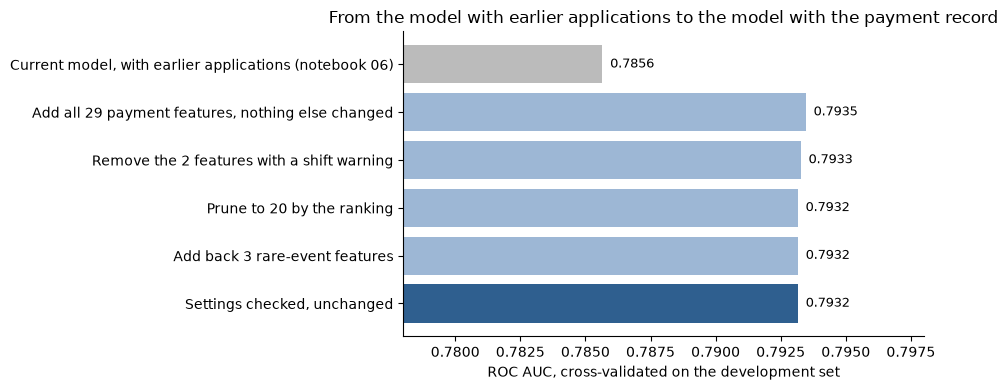

In [41]:
steps = [
    ('Current model, with earlier applications (notebook 06)', len(CURRENT), N_TREES, baseline, 2),
    ('Add all 29 payment features, nothing else changed', len(WITH_NEW), N_TREES, with_new, 3),
    ('Remove the 2 features with a shift warning', len(FULL_FEATURES), N_TREES, no_warned, 4),
    ('Prune to 20 by the ranking', len(CURRENT) + len(RULE_INST), N_TREES, pruned_rule, 5),
    ('Add back 3 rare-event features', len(CHOSEN_FEATURES), N_TREES, chosen, 5),
    ('Settings checked, unchanged', len(CHOSEN_FEATURES), FINAL_TREES, final_run, 6),
]
ladder = pd.DataFrame({label: {'stage': stage, 'features': n, 'trees': trees, 'roc_auc': r['mean']['roc_auc'], 'pr_auc': r['mean']['pr_auc'],
                               'gain_over_current_model': compare(r, baseline)['mean_difference'], 'folds_better': compare(r, baseline)['folds_better'] if r is not baseline else 0}
                       for label, n, trees, r, stage in steps}).T
ladder['step'] = ladder['roc_auc'].astype(float).diff()
print('cross-validated on the development set, the same five folds throughout:')
print(ladder.astype({'stage': int, 'features': int, 'trees': int, 'folds_better': int}).to_string(float_format=lambda v: f'{v:.5f}', na_rep=''))

calibrated_summary = pd.DataFrame({'current model': baseline_cal['mean'], 'with the payment record': final_cal['mean']}).loc[['roc_auc', 'pr_auc', 'log_loss', 'brier']]
calibrated_summary['change'] = calibrated_summary['with the payment record'] - calibrated_summary['current model']
print('\nafter calibration:')
print(calibrated_summary.to_string(float_format=lambda v: f'{v:.5f}'))
first = verdict(with_new)
print(f"\nwhen the features were first added (stage 3): gain {first['mean_difference']:+.5f}, {first['ratio_to_standard_error']:.0f} times its standard error, {first['mean_difference'] / NOISE_FLOOR:.0f} times the seed noise floor of {NOISE_FLOOR:.4f}")
print(f"95% interval for that gain from resampling applicants: {np.quantile(boot_gain, 0.025):+.4f} to {np.quantile(boot_gain, 0.975):+.4f}")
print(f"gain of the final model, both models on the same settings: {like_for_like['mean_difference']:+.5f}")
print(f"cost per 1,000 applicants at the reference threshold: {ref_old['cost_per_1000_applicants']:.1f} -> {ref_new['cost_per_1000_applicants']:.1f}")
print(f"groups more than two standard errors from their actual default rate: {int((groups_table['gap_current_in_se'].abs() > 2).sum())} of {len(groups_table)} with the current model, {int((groups_table['gap_new_in_se'].abs() > 2).sum())} with the new one")

main_scores = KAGGLE_SCORES['submission_with_installments.csv']
evidence = pd.DataFrame({
    'application only': {'cross-validation': 0.76852, 'holdout (opened once, notebook 02)': 0.7715, 'Kaggle public': 0.76743, 'Kaggle private': 0.76382},
    'with bureau': {'cross-validation': 0.77790, 'holdout (opened once, notebook 02)': np.nan, 'Kaggle public': 0.77412, 'Kaggle private': 0.77529},
    'with earlier applications': {'cross-validation': WITH_PREVIOUS['cv'], 'holdout (opened once, notebook 02)': np.nan, 'Kaggle public': WITH_PREVIOUS['public'], 'Kaggle private': WITH_PREVIOUS['private']},
    'with the payment record': {'cross-validation': CV_MAIN, 'holdout (opened once, notebook 02)': np.nan,
                                'Kaggle public': main_scores['public'] if KAGGLE_ENTERED else np.nan, 'Kaggle private': main_scores['private'] if KAGGLE_ENTERED else np.nan},
})
print('\nROC AUC by kind of evidence:')
print(evidence.to_string(float_format=lambda v: f'{v:.4f}', na_rep='not measured'))
print(f"Kaggle scores for the model with the payment record: {'entered in section 9.6' if KAGGLE_ENTERED else 'NOT YET ENTERED (section 9.6)'}")

# the figures quoted in the conclusions
assert round(float(baseline['mean']['roc_auc']), 4) == 0.7856 and round(CV_MAIN, 4) == 0.7932 and len(CHOSEN_FEATURES) == 108 and len(KEPT_INST) == 23 and FINAL_TREES == 3500
assert round(float(final_cal['mean']['log_loss']), 4) == 0.2353 and round(like_for_like['mean_difference'], 4) == 0.0075
assert not any(name in globals() for name in ['X_all', 'y_all']), 'the full training table should not be in memory'
assert KAGGLE_ENTERED and round(main_scores['private'], 4) == 0.7934 and round(main_scores['private'] - WITH_PREVIOUS['private'], 4) == 0.0092

fig, ax = plt.subplots(figsize=(9.5, 4.0))
labels = list(ladder.index)[::-1]
values = ladder['roc_auc'].astype(float)[::-1]
ax.barh(labels, values, color=['#2f5f8f'] + ['#9db7d5'] * (len(labels) - 2) + ['#bbbbbb'])
for i, v in enumerate(values):
    ax.text(v + 0.0003, i, f'{v:.4f}', va='center', fontsize=9)
ax.set_xlim(0.778, 0.798); ax.set_xlabel('ROC AUC, cross-validated on the development set'); ax.set_title('From the model with earlier applications to the model with the payment record')
sns.despine(); plt.tight_layout(); plt.show()

### Conclusions

**The answer.** Yes. How applicants paid their earlier loans improves the model, by as much as either table before it.

| | Current model (notebook 06) | With the payment record | Change |
|---|---:|---:|---:|
| ROC AUC, cross-validated | 0.7856 | 0.7932 | +0.0075 |
| PR AUC | 0.2768 | 0.2848 | +0.0080 |
| Log loss | 0.2377 | 0.2353 | -0.0024 |
| Defaults caught at the reference threshold | 67.7% | 68.4% | +0.7 points |
| Good applicants declined | 25.1% | 24.7% | -0.5 points |
| Cost per 1,000 applicants, ratio 10 | 492 | 482 | -2.0% |
| Groups mis-predicted by over two standard errors | 12 of 22 | 1 of 22 | |
| Kaggle private score | 0.7842 | 0.7934 | +0.0092 |

- Settings and trees did not change, so the 0.0075 comes from the features alone.
- The four conditions fixed in advance were met when the features were first added, with nothing tuned to them: higher on average, higher in every fold, 26 times its standard error and 16 times the noise a change of seed produces. The final model meets them too.
- Across four notebooks on the same five folds: 0.7685 with the application alone, 0.7779 with the bureau, 0.7856 with earlier applications, 0.7932 with the payment record. Each history table has added between 0.0075 and 0.0092.
- **Kaggle confirms it.** On the private test set the gain is 0.0092, more than cross-validation predicted, and the private score (0.7934) is a shade above the cross-validated one (0.7932). All three expectations written down before the upload were met.

**The model**

| | |
|---|---|
| Inputs | 108 features: 36 from the application, 24 from the credit bureau, 25 from earlier applications, 23 of the 29 payment features of notebook 07 |
| Settings | Unchanged from notebook 02. The two settings with a reason to move were checked and did not |
| Trees | 3,500 at a learning rate of 0.02 |
| Output | A calibrated probability, by the same Platt scaling |
| Decision rule | Unchanged: decline at 0.0909 or above |
| Saved as | `artifacts/model_with_installments/`, loaded by the same `src/models/scoring.py` |

**Where the gain comes from**
- **It is new information.** For the first time in this project a one-feature-at-a-time check and the result agreed. Notebook 07 found these features nearly uncorrelated with everything the model had, and the gain is the size that suggested.
- **How reliably the applicant pays, seen three ways.** Recent behaviour, payment in parts and lateness each give about half the gain alone. They overlap heavily, and no family costs more than 0.0009 to remove.
- **Applicants the model was wrong about.** It gave applicants with a recent penalty charge 14.3% when 23.9% default, and now gives 23.4%. It gave the two thirds who have never been late slightly too much risk, and now does not.
- **Applicants with no bureau record gain twice the average**, as in notebook 06.
- **Not** from the two features that count recent lateness and recent unpaid instalments directly. They were flagged for differing between train and test, were found to add nothing, and were left out.

**What I got wrong**
- **Unpaid instalments, twice.** In notebook 07 I first meant to leave them out as too rare, then kept them because those applicants default at 30% and called the first instinct a mistake. Here they turned out to add nothing even for the applicants they describe. Whether a rare-event feature earns its place depends on whether the model can use it, which is not the same as whether the event is serious.
- **And the model still gets those applicants wrong.** It gives them 19.7% against an actual 27.2%. I think the cause is the minimum of 803 applicants per leaf, which no group of 397 can meet. I did not test that.
- **What the explanations would look like.** I expected "you paid late" to become a common reason for a decline. The reason this table most often supplies is "you have a short record with us".
- **Notebook 06's rare-event rule.** It kept every rare-event feature that did not lower the score, and so kept one that did nothing. The rule was tightened here before the ranking was run. It still let one passenger through, because it tests the features added back as a group.
- **A guard in one of my own scripts** stopped stage 8 by mistaking a variable name for a leftover column. Nothing was affected.

**How leakage was controlled**

| Risk | Control | What was measured |
|---|---|---|
| A difference in code, not in features | Shared module, unchanged since notebook 04 | The baseline reproduced notebook 06's predictions exactly, for all 246,008 applicants |
| A gain from more columns, not more information | New features scrambled between applicants | The scrambled columns made the model worse by 0.0007 |
| A gain from seed noise | Other seeds of the baseline; the gain repeated on two more seeds | Noise floor 0.0005; gain 0.0075 on both other seeds |
| Features that use the future | Notebook 07 refuses any table with a date on or after the application | No such date in 13.6 million rows |
| Features supplied differently in train and test | Notebook 07's supply test, and a shift screen on every feature | All pass the supply test. Two features differ in distribution and were left out |
| Feature selection on the scored rows | Selection inside the pipeline, on training folds | Fixing one list flatters the score by 0.00004 |
| Calibration on the scored rows | Nested inside the training folds | |
| The holdout | Never loaded. Its applicants appear only as training rows in the final refit | |
| The test file | No labels. Passed through finished models only | |
| Tuning on the test set | The diagnostic model is not a candidate, whatever its Kaggle score | |

**What is still uncertain**
- **The holdout has not been opened for this model.** Every figure above is cross-validated on the development set. For the three earlier models cross-validation was confirmed by Kaggle each time, and for the first by the holdout as well. That is the reason to trust the method. It is not a measurement of this model.
- **Kaggle has now tested it once.** The private score is 0.0002 above cross-validation, where the three earlier models came in 0.0047, 0.0026 and 0.0014 below. That is direct evidence that the gain is not an artefact of choices made on the development folds. It is one test on one population.
- **The public score disagreed about the flagged features.** The private scores of the two submissions are identical. On the public fifth of the test file the model with the flagged features is 0.0017 higher. The private result is the one fixed in advance as the test, and it agrees with the folds.
- **The level of the test predictions.** The model expects 7.5% of test applicants to default, where the last model expected 7.8% and the development rate is 8.1%, because test applicants have a better payment record. A ranking score will not show whether that is right.
- **Choices made on the development folds add up.** Notebook 07 looked at development outcomes in five of its stages, though it selected nothing on them. This notebook dropped two features, chose a list size, fixed a list and added three features back. Each was done by a rule fixed beforehand, and the one effect that could be measured was 0.00004. The Kaggle result puts a ceiling on the total: the gain on the test file is larger than on the folds, not smaller.
- **The settings are beginning to look dated.** Both checks in stage 6 leaned towards a model with more trees and fewer features per tree. Neither came near the bar. The settings were tuned in notebook 02 for 55 features, and there are now 108.

**Limits**
- **The model cannot see very small groups.** With at least 803 applicants per leaf, the 0.16% of applicants with an unpaid instalment are under-predicted by a quarter. This is the highest-risk group found in the project.
- **Missed instalments are mostly invisible in the source table,** which records payments that were made.
- **The applicants were all approved for a new loan,** so recent bad payment is under-represented, and rarer still in the test file.
- **Lateness counts for eight years.** Notebook 07 found that lateness more than four years old says almost nothing about default. The model has features that date it, and it does grade it by time, but a penalty charge from seven years ago is still in the count. Applicants with a penalty at some time are now approved at 0.66 times the rate of others, down from 0.83. How far back conduct should count against someone is a policy question.
- **The penalty reading is an inference** from the pattern of the rows, not from the data dictionary.
- **The external scores are still the main reason for 56% of declines,** down from 59%, and from 71% in notebook 02.
- **What a table is credited with depends on the order.** Three features from `previous_application` lost 41% to 74% of their weight when this table arrived.
- **Applicants with no payment history are very slightly worse ranked** (0.0019 within their group, inside the noise). Their probabilities are right.
- **Gender and age.** The gaps found in notebook 02 are unchanged.

**What to do next**
1. **Add `POS_CASH_balance` and `credit_card_balance` by the same method.** They are the last two tables. The card table is the proper source for behaviour that this notebook could only summarise roughly.
2. **Then search the settings once more,** inside the folds, for the final feature list. Stage 6 gives two reasons to expect a small gain, and the minimum leaf size gives a third reason to look.
3. **Open the holdout once, at the end,** for the model that includes every table.
4. **Move the application features' code out of notebook 01,** and rewrite the loader in `scoring.py` to build its table in one step.